In [1]:
import os
import glob
import gzip
import math
import pickle
import re
import time as tt
import importlib
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.gridspec import GridSpec
import cmcrameri.cm as cmc

from scipy.stats import circmean, circstd, skew, kurtosis
from scipy.signal import correlate, argrelextrema
from scipy.optimize import curve_fit
from scipy.ndimage import gaussian_filter1d
from statsmodels import robust

import roboarmanalysis as ra
import trackpy as tp

%load_ext autoreload
%autoreload 2

In [2]:

mpl.rcParams["figure.dpi"] = 150
mpl.rcParams["savefig.dpi"] = 300
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "mathtext.fontset": "dejavusans",
    "mathtext.default": "regular",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

CK_colors = {
    "orange":    (215/255, 131/255,  41/255),
    "beige":     (225/255, 209/255, 180/255),
    "gold":      (226/255, 172/255,  72/255),
    "olive":     (140/255, 135/255,  59/255),
    "offwhite":  (222/255, 224/255, 213/255),
    "palecyan":  (167/255, 197/255, 197/255),
    "darkcyan":  (105/255, 155/255, 155/255),
    "lightblue": ( 73/255, 139/255, 167/255),
    "darkblue":  ( 46/255,  89/255, 108/255),
    "darkred":   (102/255,  27/255,  35/255),
    "grey":      (0.25, 0.25, 0.25),
    "midgrey":   (0.45, 0.45, 0.45),
    "lightgrey": (0.72, 0.72, 0.72),
    "black":      (0, 0, 0),
    "white":      (1, 1, 1),
    "warmgold":   (198/255, 161/255,  91/255),
    "target_teal": (111/255, 166/255, 166/255),
    "free_grey":      (201/255, 201/255, 201/255),  # #C9C9C9
    "fit_darkgrey":   ( 46/255,  46/255,  46/255),  # #2E2E2E
}

### Load reconstructed energy landscapes

In [3]:
def load_energy_landscapes(
    root_dir,
    required_filename_text="target_rotor_energy_landscapes",
    recursive_search=True,
    stator_patterns=None,
):
    root_dir = Path(root_dir)

    if not root_dir.exists():
        raise FileNotFoundError(f"Directory does not exist:\n{root_dir}")

    if not stator_patterns:
        raise ValueError("stator_patterns must contain at least one enabled stator variant.")

    search = root_dir.rglob if recursive_search else root_dir.glob

    pickle_files = sorted(
        set(search("*.pkl"))
        | set(search("*.pickle"))
        | set(search("*.pkl.gz"))
        | set(search("*.pickle.gz"))
    )

    if required_filename_text is not None:
        pickle_files = [
            file_path
            for file_path in pickle_files
            if required_filename_text.lower() in file_path.name.lower()
        ]

    energy_landscapes_by_stator = {
        stator_variant: []
        for stator_variant in stator_patterns
    }

    for file_path in pickle_files:
        with (
            gzip.open(file_path, "rb")
            if file_path.name.lower().endswith(".gz")
            else open(file_path, "rb")
        ) as file:
            data = pickle.load(file)

        searchable_text = " ".join(
            [
                file_path.name,
                str(file_path.parent),
                *map(str, data.get("measurements", {}).keys()),
            ]
        )

        stator_variant = next(
            (
                stator_variant
                for stator_variant, pattern in stator_patterns.items()
                if re.search(pattern, searchable_text, flags=re.IGNORECASE)
            ),
            None,
        )

        if stator_variant is None:
            continue

        energy_landscapes_by_stator[stator_variant].append(
            {
                "file_path": file_path,
                "file_name": file_path.name,
                "data": data,
            }
        )

    energy_landscapes_by_stator = {
        stator_variant: datasets
        for stator_variant, datasets in energy_landscapes_by_stator.items()
        if datasets
    }

    if not energy_landscapes_by_stator:
        raise FileNotFoundError(
            "No energy-landscape files matched the enabled stator patterns:\n"
            f"{list(stator_patterns)}"
        )

    print("Loaded energy landscapes")
    print("=" * 80)

    for stator_variant, datasets in energy_landscapes_by_stator.items():
        print(f"\n{stator_variant}: {len(datasets)} files")

        for dataset in datasets:
            print(f"  {dataset['file_name']}")

            for measurement_name, measurement in dataset["data"].get(
                "measurements", {}
            ).items():
                measurement_type = measurement.get(
                    "measurement_type",
                    "unknown",
                )

                n_particles = len(
                    measurement["particle_ids"]
                )

                print(
                    f"      {measurement_type:4s} | "
                    f"{n_particles:3d} particles | "
                    f"{measurement_name}"
                )

    return energy_landscapes_by_stator

In [4]:
root_dir = Path(
    r"R:\_06__Umbrella_Sampling\02_Figures\Figure_4\_data_energy_landscapes"
)

required_filename_text = "target_rotor_energy_landscapes"
recursive_search = True

stator_patterns = {
    # "L2ds": r"L2ds",
    # "L3ds": r"L3ds",
    # "L4ds": r"L4ds",
    
    "L2ss": r"L2ss",
    "L3ss": r"L3ss",
    "L4ss": r"L4ss",
}


# save_dir = r"R:\_06_Umbrella_Sampling\02_Figures\Figure_4\_plots"
# save_dir_SI = r"R:\_06_Umbrella_Sampling\02_Figures\Supplementary_Information\to_Figure_4"

energy_landscapes_by_stator = load_energy_landscapes(
    root_dir=root_dir,
    required_filename_text=required_filename_text,
    recursive_search=recursive_search,
    stator_patterns=stator_patterns,
)

Loaded energy landscapes

L2ss: 3 files
  L2ss-cwccw-fov04_target_rotor_energy_landscapes.pkl.gz
      UMB  |  22 particles | 260704_fov-04_12_UMB_300V_20deg-ccw_5s_L2ss-40nmCalibR_1xRef45Suc_2_MMStack_Default.ome_locs_picked
      UMB  |  22 particles | 260704_fov-04_13_UMB_300V_20deg-ccw_5s_L2ss-40nmCalibR_1xRef45Suc_1_MMStack_Default.ome_locs_picked
      DIFF |  22 particles | 260704_fov-04_11_DIFF_30s_L2ss-40nmCalibR_1xRef45Suc_1_MMStack_Default.ome_locs_picked
  L2ss-fov01_target_rotor_energy_landscapes.pkl.gz
      UMB  | 104 particles | 260707-fov01_02_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked
      UMB  | 104 particles | 260707-fov01_03_UMB_300V_20deg-cw-5s_91s__L2ss-40nmCalibR_1xRef45Su_1_MMStack_Default.ome_locs_render_picked
      DIFF | 104 particles | 260707-fov01_01_DIFF_60s__L2ss-40nmCalibR_1xRef45Suc_1_MMStack_Default.ome_locs_render_picked
  L2ss-fov02_target_rotor_energy_landscapes.pkl.gz
      UMB  | 100 particles |

### _[Check depenendence of reconstruction on bias calibration]_

In [5]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb

def analyze_barrier_height_vs_kappa_by_stator(
    energy_landscapes_by_stator,
    selected_stator_variants="all",
    kappa_key="kappa_target",
    measurement_text=None,
    smooth_nbins=5,
    barrier_quantile=1.0,
    min_finite_fraction=0.90,
    show_rotors=True,
    show_boxplots=True,
    show_umb_medians=True,
    connect_same_fov_umb=True,
    annotate_fov=False,
    show_fov_legend=True,
    sharex=True,
    sharey=True,
    rotor_alpha=0.22,
    rotor_size=8,
    median_size=40,
    line_width=1.0,
    box_width_fraction=0.030,
    jitter_fraction=0.006,
    C=None,
    fov_color_keys=("darkblue", "gold", "darkred", "lightblue", "grey", "midgrey", "lightgrey"),
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    title_size=8,
    annotation_size=6,
    fig_width_mm=180,
    fig_height_mm=70,
    save_dir=None,
    save_prefix="barrier_height_vs_mean_kappa_by_stator",
    stator_variant="all",
    random_seed=3,
):
    """
    Plot reconstructed barrier heights against the mean per-window kappa used
    for each UMB reconstruction.

    Each stator variant is shown in a separate panel. The two UMB measurements
    from the same file/FOV remain separate but share the same color.

    Parameters
    ----------
    selected_stator_variants
        "all", a single variant such as "L3ss", or a sequence such as
        ("L2ss", "L4ss").

    kappa_key
        "kappa_target" is the per-window kappa array used for target-rotor
        reconstruction.

    barrier_quantile
        1.0 uses the maximum of the smoothed, minimum-shifted landscape.
        Values below 1, such as 0.98, reduce sensitivity to isolated peaks.
    """

    def normalize_color(color):
        if isinstance(color, str):
            return to_rgb(color)
        color = np.asarray(color, dtype=float).ravel()[:3]
        return tuple(color / 255.0) if np.nanmax(color) > 1 else tuple(color)

    def mix_with_white(color, fraction):
        color = np.asarray(normalize_color(color))
        return tuple(color + fraction * (1.0 - color))

    def periodic_smooth(values, width):
        values = np.asarray(values, dtype=float)
        width = int(width)
        if width <= 1:
            return values.copy()
        pad_left = width // 2
        pad_right = width - 1 - pad_left
        left = values[-pad_left:] if pad_left else np.empty(0)
        right = values[:pad_right] if pad_right else np.empty(0)
        extended = np.concatenate([left, values, right])
        smoothed = pd.Series(extended).rolling(width, center=True, min_periods=1).mean().to_numpy()
        return smoothed[pad_left:pad_left + len(values)]

    def fill_periodic_nan(values):
        values = np.asarray(values, dtype=float).copy()
        finite = np.isfinite(values)
        if np.all(finite) or np.sum(finite) < 2:
            return values
        x = np.arange(len(values))
        xf = x[finite]
        yf = values[finite]
        values[~finite] = np.interp(x[~finite], np.concatenate([xf - len(values), xf, xf + len(values)]), np.tile(yf, 3))
        return values

    def extract_barrier_height(energy):
        energy = np.asarray(energy, dtype=float)
        finite_fraction = float(np.mean(np.isfinite(energy)))
        if finite_fraction < min_finite_fraction or np.sum(np.isfinite(energy)) < 3:
            return np.nan, finite_fraction
        energy = fill_periodic_nan(energy)
        if np.sum(np.isfinite(energy)) < 3:
            return np.nan, finite_fraction
        energy = periodic_smooth(energy, smooth_nbins)
        energy -= np.nanmin(energy)
        return float(np.nanquantile(energy, barrier_quantile)), finite_fraction

    def extract_voltage(*texts):
        match = re.search(r"(?<!\d)(\d{2,4})\s*V(?!\w)", " ".join(map(str, texts)), flags=re.IGNORECASE)
        return float(match.group(1)) if match else np.nan

    def fov_number(text):
        match = re.search(r"fov[-_]?(\d+)", str(text), flags=re.IGNORECASE)
        return int(match.group(1)) if match else 10**9

    def build_fov_colors(file_names):
        file_names = sorted(file_names, key=lambda name: (fov_number(name), str(name).lower()))
        base_colors = []

        if isinstance(C, dict):
            for key in fov_color_keys:
                if key in C:
                    base_colors.append(normalize_color(C[key]))

        if not base_colors:
            base_colors = [normalize_color(color) for color in plt.rcParams["axes.prop_cycle"].by_key()["color"]]

        colors = []
        whitening = (0.00, 0.18, 0.34, 0.48)

        while len(colors) < len(file_names):
            cycle_index = len(colors)
            base = base_colors[cycle_index % len(base_colors)]
            level = whitening[(cycle_index // len(base_colors)) % len(whitening)]
            colors.append(mix_with_white(base, level))

        return dict(zip(file_names, colors))

    valid_kappa_keys = {"kappa_target", "kappa_calibration", "kappa_used_raw", "kappa_raw"}
    if kappa_key not in valid_kappa_keys:
        raise ValueError(f"kappa_key must be one of {sorted(valid_kappa_keys)}.")

    available_variants = list(energy_landscapes_by_stator)

    if selected_stator_variants in [None, "all"]:
        selected_variants = available_variants
    elif isinstance(selected_stator_variants, str):
        selected_variants = [selected_stator_variants]
    else:
        selected_variants = list(selected_stator_variants)

    missing = [variant for variant in selected_variants if variant not in energy_landscapes_by_stator]
    if missing:
        raise ValueError(f"Unknown stator variants: {missing}. Available variants: {available_variants}")

    rotor_rows = []

    for current_stator in selected_variants:
        for dataset in energy_landscapes_by_stator[current_stator]:
            data = dataset["data"]
            file_name = dataset["file_name"]
            file_path = dataset["file_path"]
            fov = data.get("fov", Path(file_name).stem)
            metadata_all = data.get("umbrella_metadata", {})

            for measurement_name, measurement in data.get("measurements", {}).items():
                if measurement.get("measurement_type") != "UMB":
                    continue

                searchable = " ".join([measurement_name, str(measurement.get("raw_filename", "")), file_name])
                if measurement_text is not None and measurement_text.lower() not in searchable.lower():
                    continue

                metadata = metadata_all.get(measurement_name)
                if metadata is None:
                    continue

                kappa_by_window = np.asarray(metadata.get(kappa_key, []), dtype=float)
                finite_kappa = np.isfinite(kappa_by_window)
                if not np.any(finite_kappa):
                    continue

                particle_ids = np.asarray(measurement.get("particle_ids", []), dtype=int)
                energy_matrix = np.asarray(measurement.get("energy_kBT", []), dtype=float)
                if energy_matrix.ndim != 2 or len(particle_ids) != len(energy_matrix):
                    continue

                mean_kappa = float(np.nanmean(kappa_by_window))
                median_kappa = float(np.nanmedian(kappa_by_window))
                std_kappa = float(np.nanstd(kappa_by_window))
                voltage = extract_voltage(measurement_name, measurement.get("raw_filename", ""), file_name)

                for particle_id, energy in zip(particle_ids, energy_matrix):
                    barrier_height, finite_fraction = extract_barrier_height(energy)
                    if not np.isfinite(barrier_height):
                        continue

                    rotor_rows.append({
                        "stator_variant": current_stator,
                        "file_name": file_name,
                        "file_path": file_path,
                        "fov": fov,
                        "measurement_name": measurement_name,
                        "voltage_V": voltage,
                        "particle_id": int(particle_id),
                        "barrier_height_kBT": barrier_height,
                        "mean_kappa_selected": mean_kappa,
                        "median_kappa_selected": median_kappa,
                        "std_kappa_selected": std_kappa,
                        "cv_kappa_selected": std_kappa / mean_kappa if mean_kappa > 0 else np.nan,
                        "n_kappa_windows": int(np.sum(finite_kappa)),
                        "finite_energy_fraction": finite_fraction,
                    })

    rotor_df = pd.DataFrame(rotor_rows)
    if rotor_df.empty:
        raise ValueError("No valid UMB reconstructions were found for the selected settings.")

    umb_group_columns = ["stator_variant", "file_name", "file_path", "fov", "measurement_name", "voltage_V"]
    umb_summary_df = rotor_df.groupby(umb_group_columns, dropna=False, as_index=False).agg(
        mean_kappa_selected=("mean_kappa_selected", "first"),
        median_kappa_selected=("median_kappa_selected", "first"),
        std_kappa_selected=("std_kappa_selected", "first"),
        cv_kappa_selected=("cv_kappa_selected", "first"),
        n_kappa_windows=("n_kappa_windows", "first"),
        n_rotors=("particle_id", "nunique"),
        barrier_mean_kBT=("barrier_height_kBT", "mean"),
        barrier_median_kBT=("barrier_height_kBT", "median"),
        barrier_std_kBT=("barrier_height_kBT", "std"),
        barrier_q25_kBT=("barrier_height_kBT", lambda x: float(np.nanquantile(x, 0.25))),
        barrier_q75_kBT=("barrier_height_kBT", lambda x: float(np.nanquantile(x, 0.75))),
    )

    fov_group_columns = ["stator_variant", "file_name", "file_path", "fov"]
    fov_summary_df = umb_summary_df.groupby(fov_group_columns, dropna=False, as_index=False).agg(
        n_umb=("measurement_name", "nunique"),
        umb_mean_kappa_mean=("mean_kappa_selected", "mean"),
        umb_mean_kappa_difference=("mean_kappa_selected", lambda x: float(np.nanmax(x) - np.nanmin(x)) if len(x) > 1 else np.nan),
        umb_barrier_median_mean=("barrier_median_kBT", "mean"),
        umb_barrier_median_difference=("barrier_median_kBT", lambda x: float(np.nanmax(x) - np.nanmin(x)) if len(x) > 1 else np.nan),
    )

    x_all = umb_summary_df["mean_kappa_selected"].to_numpy(dtype=float)
    y_all = rotor_df["barrier_height_kBT"].to_numpy(dtype=float)
    x_min, x_max = np.nanmin(x_all), np.nanmax(x_all)
    y_min, y_max = np.nanmin(y_all), np.nanmax(y_all)
    x_span = x_max - x_min if x_max > x_min else max(abs(np.nanmean(x_all)), 1.0)
    y_span = y_max - y_min if y_max > y_min else max(abs(np.nanmean(y_all)), 1.0)
    x_pad = 0.08 * x_span
    y_pad = 0.06 * y_span
    box_width = box_width_fraction * x_span
    jitter_width = jitter_fraction * x_span

    n_panels = len(selected_variants)
    fig, axes = plt.subplots(1, n_panels, figsize=(fig_width_mm / 25.4, fig_height_mm / 25.4), sharex=sharex, sharey=sharey)
    axes = np.atleast_1d(axes)
    rng = np.random.default_rng(random_seed)

    for ax, current_stator in zip(axes, selected_variants):
        rotor_sub = rotor_df[rotor_df["stator_variant"] == current_stator]
        umb_sub = umb_summary_df[umb_summary_df["stator_variant"] == current_stator]
        fov_sub = fov_summary_df[fov_summary_df["stator_variant"] == current_stator]

        file_names = sorted(fov_sub["file_name"].unique(), key=lambda name: (fov_number(name), str(name).lower()))
        fov_colors = build_fov_colors(file_names)

        for file_name in file_names:
            color = fov_colors[file_name]
            rotor_fov = rotor_sub[rotor_sub["file_name"] == file_name]
            umb_fov = umb_sub[umb_sub["file_name"] == file_name].sort_values(
                ["mean_kappa_selected", "measurement_name"],
                ascending=[True, True],
                kind="mergesort",
            )

            if show_rotors and not rotor_fov.empty:
                x = rotor_fov["mean_kappa_selected"].to_numpy(dtype=float)
                y = rotor_fov["barrier_height_kBT"].to_numpy(dtype=float)
                x += rng.uniform(-jitter_width, jitter_width, size=len(x))
                ax.scatter(x, y, s=rotor_size, alpha=rotor_alpha, color=color, linewidths=0, zorder=1)

            if connect_same_fov_umb and len(umb_fov) > 1:
                ax.plot(
                    umb_fov["mean_kappa_selected"],
                    umb_fov["barrier_median_kBT"],
                    color=color,
                    lw=line_width,
                    alpha=0.95,
                    zorder=3,
                )

            for _, row in umb_fov.iterrows():
                values = rotor_sub.loc[
                    (rotor_sub["file_name"] == file_name)
                    & (rotor_sub["measurement_name"] == row["measurement_name"]),
                    "barrier_height_kBT",
                ].dropna().to_numpy()

                x_pos = float(row["mean_kappa_selected"])

                if show_boxplots and len(values):
                    ax.boxplot(
                        [values],
                        positions=[x_pos],
                        widths=box_width,
                        patch_artist=True,
                        manage_ticks=False,
                        showfliers=False,
                        medianprops={"color": "black", "linewidth": 0.9},
                        whiskerprops={"color": color, "linewidth": 0.8},
                        capprops={"color": color, "linewidth": 0.8},
                        boxprops={"facecolor": color, "edgecolor": color, "alpha": 0.25, "linewidth": 0.8},
                    )

                if show_umb_medians:
                    ax.scatter(
                        x_pos,
                        row["barrier_median_kBT"],
                        s=median_size,
                        color=color,
                        edgecolors="black",
                        linewidths=0.6,
                        zorder=4,
                    )

            if annotate_fov and len(umb_fov):
                label = str(umb_fov["fov"].iloc[0])
                ax.text(
                    np.nanmean(umb_fov["mean_kappa_selected"]),
                    np.nanmax(umb_fov["barrier_median_kBT"]) + 0.025 * y_span,
                    label,
                    ha="center",
                    va="bottom",
                    fontsize=annotation_size,
                    color=color,
                )

        if show_fov_legend:
            handles = [
                plt.Line2D(
                    [0],
                    [0],
                    marker="o",
                    linestyle="-",
                    color=fov_colors[file_name],
                    markeredgecolor="black",
                    markeredgewidth=0.4,
                    markersize=4,
                    linewidth=0.8,
                    label=str(fov_sub.loc[fov_sub["file_name"] == file_name, "fov"].iloc[0]),
                )
                for file_name in file_names
            ]
            ax.legend(handles=handles, title="FOV", frameon=False, fontsize=annotation_size, title_fontsize=annotation_size, ncol=2, handlelength=1.2, columnspacing=0.8, handletextpad=0.4)

        ax.set_title(
            f"{current_stator}\n{len(file_names)} FOVs, {len(umb_sub)} UMBs",
            fontsize=title_size,
        )
        ax.set_xlim(x_min - x_pad, x_max + x_pad)
        ax.set_ylim(max(0, y_min - y_pad), y_max + y_pad)
        ax.set_xlabel(
            r"Mean $\kappa_\theta$ used for reconstruction / $(k_\mathrm{B}T)\,\mathrm{rad}^{-2}$",
            fontsize=axis_label_size,
        )
        ax.tick_params(labelsize=tick_label_size, direction="out")
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    axes[0].set_ylabel(r"Reconstructed barrier height / $k_\mathrm{B}T$", fontsize=axis_label_size)
    fig.tight_layout()

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        prefix = "" if stator_variant in [None, "", "all"] else f"{stator_variant}__"
        fig.savefig(save_dir / f"{prefix}{save_prefix}.png", dpi=300, bbox_inches="tight")
        fig.savefig(save_dir / f"{prefix}{save_prefix}.svg", bbox_inches="tight")

    print(f"Analyzed {len(rotor_df)} rotor reconstructions.")
    print(f"Files/FOVs: {len(fov_summary_df)}")
    print(f"UMB measurements: {len(umb_summary_df)}")
    print(f"Kappa source: {kappa_key}")

    for current_stator in selected_variants:
        n_fov = fov_summary_df["stator_variant"].eq(current_stator).sum()
        n_umb = umb_summary_df["stator_variant"].eq(current_stator).sum()
        n_rotors = rotor_df["stator_variant"].eq(current_stator).sum()
        print(f"{current_stator}: {n_fov} FOVs | {n_umb} UMBs | {n_rotors} rotor reconstructions")

    return rotor_df, umb_summary_df, fov_summary_df, fig, axes

In [6]:
# rotor_barrier_kappa_df, umb_barrier_kappa_summary_df, fov_barrier_kappa_summary_df, fig_barrier_kappa, axes_barrier_kappa = analyze_barrier_height_vs_kappa_by_stator(
#     energy_landscapes_by_stator=energy_landscapes_by_stator,
#     selected_stator_variants="all",  # "all", "L2ss", "L3ss", "L4ss", or ["L2ss", "L3ss"]
#     kappa_key="kappa_target",
#     measurement_text=None,
#     smooth_nbins=5,
#     barrier_quantile=1.0,
#     min_finite_fraction=0.90,
#     show_rotors=True,
#     show_boxplots=True,
#     show_umb_medians=True,
#     connect_same_fov_umb=True,
#     annotate_fov=False,
#     show_fov_legend=True,
#     sharex=True,
#     sharey=True,
#     rotor_alpha=0.22,
#     rotor_size=8,
#     median_size=40,
#     line_width=1.0,
#     box_width_fraction=0.030,
#     jitter_fraction=0.006,
#     C=CK_colors,
#     fov_color_keys=("darkblue", "gold", "darkred", "lightblue", "grey", "midgrey", "lightgrey"),
#     fontsize=8,
#     axis_label_size=8,
#     tick_label_size=7,
#     title_size=8,
#     annotation_size=6,
#     fig_width_mm=180,
#     fig_height_mm=70,
#     save_dir=None,
#     save_prefix="barrier_height_vs_mean_kappa_by_stator",
#     stator_variant="L2ss",
#     random_seed=3,
# )

### _[SI | Consistency across different field of views]_

In [7]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_barrier_height_vs_kappa(
    energy_landscapes_by_stator,
    stator_variant="L2ss",
    kappa_key="kappa_target",
    measurement_text=None,
    smooth_nbins=5,
    barrier_quantile=1.0,
    min_finite_fraction=0.90,
    show_rotor_points=True,
    show_boxplots=True,
    show_umb_medians=True,
    show_umb_fit=True,
    show_fit_ci=True,
    show_statistics=True,
    n_fit_bootstrap=5000,
    rotor_alpha=0.20,
    rotor_size=8,
    median_size=34,
    box_width_fraction=0.026,
    jitter_fraction=0.005,
    band_alpha=0.16,
    C=None,
    fontsize=8,
    axis_label_size=8,
    tick_label_size=7,
    annotation_size=6,
    fig_width_mm=90,
    fig_height_mm=66,
    xlim=None,
    ylim=(0, None),
    save_dir=None,
    save_prefix="barrier_height_vs_mean_kappa",
    rotor_random_seed=3,
):
    def mm(value):
        return float(value) / 25.4

    def get_colors(colors):
        if colors is None:
            colors = CK_colors() if "CK_colors" in globals() and callable(CK_colors) else {}
        elif callable(colors):
            colors = colors()

        colors = dict(colors)
        colors.setdefault("black", (0, 0, 0))
        colors.setdefault("grey", (0.25, 0.25, 0.25))
        colors.setdefault("midgrey", colors["grey"])
        colors.setdefault("lightgrey", (0.72, 0.72, 0.72))
        colors.setdefault("target_teal", colors.get("lightblue", (73 / 255, 139 / 255, 167 / 255)))
        colors.setdefault("darkblue", colors.get("target_teal", (46 / 255, 89 / 255, 108 / 255)))

        for key, value in list(colors.items()):
            array = np.asarray(value, dtype=float).ravel()
            if array.size >= 3:
                colors[key] = tuple(array[:3] / 255.0) if np.nanmax(array[:3]) > 1 else tuple(array[:3])

        return colors

    def blend(color_a, color_b, fraction):
        color_a, color_b = np.asarray(color_a, float), np.asarray(color_b, float)
        return tuple((1.0 - float(fraction)) * color_a + float(fraction) * color_b)

    def teal_variants(base_color, n):
        fractions = np.linspace(0.36, -0.18, max(int(n), 1))
        colors = []

        for fraction in fractions:
            reference = (1, 1, 1) if fraction >= 0 else (0, 0, 0)
            colors.append(blend(base_color, reference, abs(fraction)))

        return colors

    def fov_number(text):
        match = re.search(r"fov[-_]?(\d+)", str(text), flags=re.IGNORECASE)
        return int(match.group(1)) if match else 10**9

    def periodic_smooth(values, width):
        values = np.asarray(values, dtype=float)
        width = int(width)

        if width <= 1:
            return values.copy()

        pad_left = width // 2
        pad_right = width - 1 - pad_left
        extended = np.concatenate([
            values[-pad_left:] if pad_left else np.empty(0),
            values,
            values[:pad_right] if pad_right else np.empty(0),
        ])
        smoothed = pd.Series(extended).rolling(width, center=True, min_periods=1).mean().to_numpy()

        return smoothed[pad_left:pad_left + len(values)]

    def fill_periodic_nan(values):
        values = np.asarray(values, dtype=float).copy()
        finite = np.isfinite(values)

        if np.all(finite) or np.sum(finite) < 2:
            return values

        x = np.arange(len(values))
        xf, yf = x[finite], values[finite]
        values[~finite] = np.interp(
            x[~finite],
            np.concatenate([xf - len(values), xf, xf + len(values)]),
            np.concatenate([yf, yf, yf]),
        )

        return values

    def extract_barrier_height(energy):
        energy = np.asarray(energy, dtype=float)
        finite_fraction = float(np.mean(np.isfinite(energy)))

        if finite_fraction < float(min_finite_fraction) or np.sum(np.isfinite(energy)) < 3:
            return np.nan

        energy = fill_periodic_nan(energy)

        if np.sum(np.isfinite(energy)) < 3:
            return np.nan

        energy = periodic_smooth(energy, smooth_nbins)
        energy -= np.nanmin(energy)

        return float(np.nanquantile(energy, barrier_quantile))

    def linear_fit_with_bootstrap(x, y):
        x, y = np.asarray(x, float), np.asarray(y, float)
        finite = np.isfinite(x) & np.isfinite(y)
        x, y = x[finite], y[finite]

        if len(x) < 3 or np.nanstd(x) == 0:
            return None

        slope, intercept = np.polyfit(x, y, 1)
        y_pred = intercept + slope * x
        ss_res = np.sum((y - y_pred) ** 2)
        ss_tot = np.sum((y - np.mean(y)) ** 2)
        r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan
        x_fit = np.linspace(np.nanmin(x), np.nanmax(x), 200)
        y_fit = intercept + slope * x_fit
        rng = np.random.default_rng(rotor_random_seed)
        slopes, predictions = [], []

        for _ in range(int(n_fit_bootstrap)):
            indices = rng.integers(0, len(x), len(x))
            xb, yb = x[indices], y[indices]

            if np.nanstd(xb) == 0:
                continue

            slope_b, intercept_b = np.polyfit(xb, yb, 1)
            slopes.append(slope_b)
            predictions.append(intercept_b + slope_b * x_fit)

        slopes, predictions = np.asarray(slopes, float), np.asarray(predictions, float)

        if len(slopes):
            slope_low, slope_high = np.nanquantile(slopes, [0.025, 0.975])
            fit_low, fit_high = np.nanquantile(predictions, [0.025, 0.975], axis=0)
        else:
            slope_low = slope_high = np.nan
            fit_low = fit_high = np.full_like(x_fit, np.nan)

        return {
            "n": len(x),
            "slope": float(slope),
            "slope_low": float(slope_low),
            "slope_high": float(slope_high),
            "r2": float(r2),
            "x_fit": x_fit,
            "y_fit": y_fit,
            "fit_low": fit_low,
            "fit_high": fit_high,
        }

    def style_axis(ax):
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(0.60)
            spine.set_color(C["black"])

        ax.tick_params(length=2.0, width=0.60, labelsize=tick_label_size, colors=C["black"], pad=1.2, direction="out")
        ax.grid(False)

    valid_kappa_keys = {"kappa_target", "kappa_calibration", "kappa_used_raw", "kappa_raw"}

    if kappa_key not in valid_kappa_keys:
        raise ValueError(f"kappa_key must be one of {sorted(valid_kappa_keys)}.")

    if stator_variant not in energy_landscapes_by_stator:
        raise ValueError(
            f"Stator variant {stator_variant!r} was not loaded. "
            f"Available variants: {list(energy_landscapes_by_stator)}"
        )

    C = get_colors(C)
    rows = []

    for dataset in energy_landscapes_by_stator[stator_variant]:
        data = dataset["data"]
        file_name = dataset["file_name"]
        fov = data.get("fov", Path(file_name).stem)
        metadata_all = data.get("umbrella_metadata", {})

        for measurement_name, measurement in data.get("measurements", {}).items():
            if str(measurement.get("measurement_type", "")).upper() != "UMB":
                continue

            searchable = " ".join([measurement_name, str(measurement.get("raw_filename", "")), file_name])

            if measurement_text is not None and measurement_text.lower() not in searchable.lower():
                continue

            metadata = metadata_all.get(measurement_name)

            if metadata is None:
                continue

            kappa_by_window = np.asarray(metadata.get(kappa_key, []), dtype=float)

            if not np.any(np.isfinite(kappa_by_window)):
                continue

            particle_ids = np.asarray(measurement.get("particle_ids", []), dtype=int)
            energy_matrix = np.asarray(measurement.get("energy_kBT", []), dtype=float)

            if energy_matrix.ndim != 2 or energy_matrix.shape[0] != len(particle_ids):
                continue

            mean_kappa = float(np.nanmean(kappa_by_window))

            for particle_id, energy in zip(particle_ids, energy_matrix):
                barrier_height = extract_barrier_height(energy)

                if np.isfinite(barrier_height):
                    rows.append({
                        "file_name": file_name,
                        "fov": fov,
                        "measurement_name": measurement_name,
                        "particle_id": int(particle_id),
                        "mean_kappa": mean_kappa,
                        "barrier_height": barrier_height,
                    })

    rotor_df = pd.DataFrame(rows)

    if rotor_df.empty:
        raise ValueError(f"No valid {stator_variant} UMB reconstructions were found.")

    umb_df = rotor_df.groupby(
        ["file_name", "fov", "measurement_name"],
        as_index=False,
        dropna=False,
    ).agg(
        mean_kappa=("mean_kappa", "first"),
        median_barrier=("barrier_height", "median"),
        n_rotors=("particle_id", "nunique"),
    )

    file_names = sorted(pd.unique(umb_df["file_name"]), key=lambda name: (fov_number(name), str(name).lower()))
    fov_colors = dict(zip(file_names, teal_variants(C["target_teal"], len(file_names))))
    x_all = umb_df["mean_kappa"].to_numpy(float)
    y_all = rotor_df["barrier_height"].to_numpy(float)
    x_min, x_max = np.nanmin(x_all), np.nanmax(x_all)
    y_min, y_max = np.nanmin(y_all), np.nanmax(y_all)
    x_span = x_max - x_min if x_max > x_min else max(abs(np.nanmean(x_all)), 1.0)
    y_span = y_max - y_min if y_max > y_min else max(abs(np.nanmean(y_all)), 1.0)
    box_width = float(box_width_fraction) * x_span
    jitter_width = float(jitter_fraction) * x_span
    rng = np.random.default_rng(rotor_random_seed)

    fig, ax = plt.subplots(figsize=(mm(fig_width_mm), mm(fig_height_mm)))

    for file_name in file_names:
        color = fov_colors[file_name]
        umb_fov = umb_df[umb_df["file_name"] == file_name].sort_values(["mean_kappa", "measurement_name"], kind="mergesort")

        for _, umb_row in umb_fov.iterrows():
            values = rotor_df.loc[
                (rotor_df["file_name"] == file_name)
                & (rotor_df["measurement_name"] == umb_row["measurement_name"]),
                "barrier_height",
            ].dropna().to_numpy(float)

            x_position = float(umb_row["mean_kappa"])

            if show_rotor_points and len(values):
                jitter = rng.uniform(-jitter_width, jitter_width, len(values))
                ax.scatter(
                    np.full(len(values), x_position) + jitter,
                    values,
                    s=rotor_size,
                    facecolor=color,
                    edgecolor="none",
                    alpha=rotor_alpha,
                    zorder=1,
                )

            if show_boxplots and len(values):
                boxplot = ax.boxplot(
                    [values],
                    positions=[x_position],
                    widths=box_width,
                    patch_artist=True,
                    showfliers=False,
                    whis=(5, 95),
                    manage_ticks=False,
                    zorder=3,
                )

                boxplot["boxes"][0].set_facecolor((*color, 0.22))
                boxplot["boxes"][0].set_edgecolor(blend(color, C["darkblue"], 0.18))
                boxplot["boxes"][0].set_linewidth(0.85)
                boxplot["medians"][0].set_color(C["darkblue"])
                boxplot["medians"][0].set_linewidth(1.10)

                for artist in boxplot["whiskers"] + boxplot["caps"]:
                    artist.set_color(blend(color, C["midgrey"], 0.35))
                    artist.set_linewidth(0.80)

            if show_umb_medians:
                ax.scatter(
                    x_position,
                    umb_row["median_barrier"],
                    s=median_size,
                    facecolor=color,
                    edgecolor=C["darkblue"],
                    linewidth=0.65,
                    zorder=4,
                )

    fit = linear_fit_with_bootstrap(umb_df["mean_kappa"], umb_df["median_barrier"])

    if fit is not None and show_umb_fit:
        if show_fit_ci:
            ax.fill_between(
                fit["x_fit"],
                fit["fit_low"],
                fit["fit_high"],
                color=C["target_teal"],
                alpha=band_alpha,
                linewidth=0,
                zorder=0,
            )

        ax.plot(fit["x_fit"], fit["y_fit"], color=C["darkblue"], lw=1.15, zorder=2)

    if fit is not None and show_statistics:
        ax.text(
            0.03,
            0.97,
            (
                rf"$n={fit['n']}$"
                "\n"
                rf"slope = {fit['slope']:.2f} "
                rf"[{fit['slope_low']:.2f}, {fit['slope_high']:.2f}]"
                "\n"
                rf"$R^2={fit['r2']:.2f}$"
            ),
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=annotation_size,
            color=C["black"],
        )

    ax.set_xlabel(
        r"$\langle \kappa_i \rangle$ / $k_\mathrm{B}T\,\mathrm{rad}^{-2}$",
        fontsize=axis_label_size,
        labelpad=1.5,
    )
    ax.set_ylabel(
        r"$\Delta G_\mathrm{b}$ / $k_\mathrm{B}T$",
        fontsize=axis_label_size,
        labelpad=1.5,
    )

    if xlim is None:
        ax.set_xlim(x_min - 0.06 * x_span, x_max + 0.06 * x_span)
    else:
        ax.set_xlim(*xlim)

    if ylim is not None:
        ymin = y_min - 0.04 * y_span if ylim[0] is None else float(ylim[0])
        ymax = y_max + 0.06 * y_span if ylim[1] is None else float(ylim[1])
        ax.set_ylim(ymin, ymax)

    style_axis(ax)
    fig.subplots_adjust(left=0.15, right=0.985, bottom=0.19, top=0.98)

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_dir / f"{save_prefix}.png", dpi=300, bbox_inches="tight")
        fig.savefig(save_dir / f"{save_prefix}.svg", bbox_inches="tight")

    print(f"{stator_variant}: {len(file_names)} FOVs | {len(umb_df)} UMBs | {len(rotor_df)} rotor reconstructions")

    plt.show()
    plt.close(fig)

In [8]:
# plot_barrier_height_vs_kappa(
#     energy_landscapes_by_stator=energy_landscapes_by_stator,
#     stator_variant="L4ss",
#     kappa_key="kappa_target",
#     measurement_text=None,
#     smooth_nbins=5,
#     barrier_quantile=1.0,
#     min_finite_fraction=0.90,
#     show_rotor_points=True,
#     show_boxplots=True,
#     show_umb_medians=True,
#     show_umb_fit=True,
#     show_fit_ci=True,
#     show_statistics=True,
#     n_fit_bootstrap=5000,
#     rotor_alpha=0.20,
#     rotor_size=8,
#     median_size=34,
#     box_width_fraction=0.026,
#     jitter_fraction=0.005,
#     band_alpha=0.16,
#     C=CK_colors,
#     fontsize=7,
#     axis_label_size=7,
#     tick_label_size=7,
#     annotation_size=6,
#     fig_width_mm=70,
#     fig_height_mm=50,
#     xlim=None,
#     ylim=(0, None),
#     save_dir=None,
#     save_prefix="SI_toFig2d_reconstructed_barrier_versus_kappa",
#     rotor_random_seed=3,
# )

In [9]:
# plot_barrier_height_vs_kappa(
#     energy_landscapes_by_stator=energy_landscapes_by_stator,
#     stator_variant="L3ss",
#     kappa_key="kappa_target",
#     measurement_text=None,
#     smooth_nbins=5,
#     barrier_quantile=1.0,
#     min_finite_fraction=0.90,
#     show_rotor_points=True,
#     show_boxplots=True,
#     show_umb_medians=True,
#     show_umb_fit=True,
#     show_fit_ci=True,
#     show_statistics=True,
#     n_fit_bootstrap=5000,
#     rotor_alpha=0.20,
#     rotor_size=8,
#     median_size=34,
#     box_width_fraction=0.026,
#     jitter_fraction=0.005,
#     band_alpha=0.16,
#     C=CK_colors,
#     fontsize=7,
#     axis_label_size=7,
#     tick_label_size=7,
#     annotation_size=6,
#     fig_width_mm=70,
#     fig_height_mm=50,
#     xlim=None,
#     ylim=(0, None),
#     save_dir=None,
#     save_prefix="SI_toFig2d_reconstructed_barrier_versus_kappa",
#     rotor_random_seed=3,
# )


### Plot gallery of reconstructed rotors

In [10]:
def plot_loaded_energy_landscape_gallery(
    energy_landscapes_by_stator,
    stator_variant=None,
    particles=None,
    ncols=4,
    nrows_per_page=6,
    panel_width_mm=38,
    panel_height_mm=30,
    shared_ylim=False,
    show_diff=True,
    C=None,
    save_dir=None,
    save_svg=False,
    save_prefix="loaded_energy_landscape_gallery",
):
    """
    Plot original loaded target-rotor energy landscapes.

    shared_ylim:
        False   -> individual automatic y-limits
        True    -> one automatically determined y-limit for all panels
        15      -> fixed shared y-limit of (0, 15) kBT
        (0, 15) -> explicitly defined shared y-limit

    Solid curves:
        UMB reconstructions

    Dashed black curves:
        DIFF landscapes

    Nothing is returned.
    """

    import math
    import re
    from pathlib import Path

    import matplotlib.pyplot as plt
    import numpy as np

    # ================================================================
    # SETTINGS
    # ================================================================

    axis_label_size, tick_label_size, title_fontsize = 8, 7, 7
    umb_lw, diff_lw = 1.15, 0.95
    left, right, bottom, top = 0.07, 0.99, 0.07, 0.97
    wspace, hspace = 0.22, 0.32

    # ================================================================
    # INTERNAL FUNCTIONS
    # ================================================================

    def mm(value):
        return float(value) / 25.4

    def zero_min(energy):
        energy = np.asarray(energy, dtype=float).copy()
        finite = np.isfinite(energy)
        if np.any(finite):
            energy[finite] -= np.nanmin(energy[finite])
        return energy

    def natural_key(value):
        return [int(part) if part.isdigit() else part.lower()
                for part in re.split(r"(\d+)", str(value))]

    def get_colors(colors):
        if colors is None:
            colors = CK_colors() if "CK_colors" in globals() and callable(CK_colors) else {}
        elif callable(colors):
            colors = colors()

        colors = dict(colors)
        defaults = {
            "target_teal": (73 / 255, 139 / 255, 167 / 255),
            "black": (0, 0, 0),
        }

        for key, value in defaults.items():
            colors.setdefault(key, value)

        return colors

    def blend(color, other, fraction):
        color, other = np.asarray(color, float), np.asarray(other, float)
        return tuple((1 - fraction) * color + fraction * other)

    def color_variants(base_color, n):
        if n <= 1:
            return [tuple(base_color)]

        colors = []
        for fraction in np.linspace(0.35, -0.15, n):
            other = (1, 1, 1) if fraction >= 0 else (0, 0, 0)
            colors.append(blend(base_color, other, abs(fraction)))

        return colors

    def finite_limits(values, pad=0.08):
        finite_values = [
            values[np.isfinite(values)]
            for values in map(lambda x: np.asarray(x, float), values)
            if np.any(np.isfinite(values))
        ]

        if not finite_values:
            return None

        finite_values = np.concatenate(finite_values)
        ymin = min(0.0, float(np.min(finite_values)))
        ymax = max(0.0, float(np.max(finite_values)))
        span = max(ymax - ymin, 1.0)

        return ymin - pad * span, ymax + pad * span

    def style_ax(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color("black")

        ax.tick_params(length=2, width=0.6, direction="out", labelsize=tick_label_size)
        ax.grid(False)

    def resolve_shared_ylim(shared_ylim, rotor_data, rotor_keys):
        if shared_ylim is False or shared_ylim is None:
            return None

        if isinstance(shared_ylim, (int, float)) and not isinstance(shared_ylim, bool):
            return 0.0, float(shared_ylim)

        if isinstance(shared_ylim, (tuple, list, np.ndarray)) and len(shared_ylim) == 2:
            return float(shared_ylim[0]), float(shared_ylim[1])

        if shared_ylim is True:
            values = []

            for key in rotor_keys:
                values.extend(item["energy_kBT"] for item in rotor_data[key]["UMB"])

                if show_diff:
                    values.extend(item["energy_kBT"] for item in rotor_data[key]["DIFF"])

            return finite_limits(values)

        raise ValueError(
            "shared_ylim must be False, True, a number such as 15, "
            "or a two-value range such as (0, 15)."
        )

    # ================================================================
    # INPUT AND VARIANT SELECTION
    # ================================================================

    if not isinstance(energy_landscapes_by_stator, dict) or not energy_landscapes_by_stator:
        raise ValueError(
            "energy_landscapes_by_stator must be the non-empty dictionary "
            "returned by load_energy_landscapes()."
        )

    C = get_colors(C)
    loaded_variants = sorted(energy_landscapes_by_stator, key=natural_key)
    plot_all_variants = isinstance(stator_variant, str) and stator_variant.lower() == "all"

    if plot_all_variants:
        variant_groups = [([variant], variant) for variant in loaded_variants]

    elif stator_variant is None:
        variant_groups = [(loaded_variants, None)]

    else:
        if stator_variant not in energy_landscapes_by_stator:
            raise ValueError(
                f"Stator variant '{stator_variant}' was not loaded.\n"
                f"Available variants: {loaded_variants}"
            )

        variant_groups = [([stator_variant], stator_variant)]

    particle_selection = None if particles is None else set(map(int, particles))

    # ================================================================
    # BUILD AND PLOT EACH GALLERY
    # ================================================================

    for variants_in_gallery, current_variant in variant_groups:

        rotor_data = {}

        for variant in variants_in_gallery:
            for dataset in energy_landscapes_by_stator[variant]:

                file_name = dataset["file_name"]
                data = dataset["data"]

                if "phi_rad" not in data or "measurements" not in data:
                    raise KeyError(
                        f"{file_name}: expected 'phi_rad' and 'measurements'."
                    )

                phi_rad = np.asarray(data["phi_rad"], float)

                for measurement_name, measurement in data["measurements"].items():

                    particle_ids = np.asarray(measurement["particle_ids"], int)
                    energy_matrix = np.asarray(measurement["energy_kBT"], float)
                    measurement_type = str(
                        measurement.get("measurement_type", "unknown")
                    ).upper()

                    if energy_matrix.ndim != 2:
                        raise ValueError(
                            f"{file_name} | {measurement_name}: "
                            "energy_kBT must be two-dimensional."
                        )

                    if energy_matrix.shape != (len(particle_ids), len(phi_rad)):
                        raise ValueError(
                            f"{file_name} | {measurement_name}: "
                            "energy_kBT shape does not match particle_ids and phi_rad."
                        )

                    for row, particle_id in enumerate(particle_ids):

                        particle_id = int(particle_id)

                        if particle_selection is not None and particle_id not in particle_selection:
                            continue

                        key = variant, file_name, particle_id

                        rotor_data.setdefault(
                            key,
                            {
                                "stator_variant": variant,
                                "source_file": file_name,
                                "particle_id": particle_id,
                                "phi_rad": phi_rad.copy(),
                                "UMB": [],
                                "DIFF": [],
                            },
                        )

                        entry = {
                            "measurement_name": measurement_name,
                            "energy_kBT": zero_min(energy_matrix[row]),
                        }

                        if measurement_type in ("UMB", "DIFF"):
                            rotor_data[key][measurement_type].append(entry)

        if not rotor_data:
            raise ValueError(
                f"No matching landscapes were found for stator variant '{current_variant}'."
            )

        rotor_keys = sorted(
            rotor_data,
            key=lambda key: (
                natural_key(key[0]),
                natural_key(key[1]),
                key[2],
            ),
        )

        fixed_ylim = resolve_shared_ylim(shared_ylim, rotor_data, rotor_keys)

        panels_per_page = int(ncols) * int(nrows_per_page)
        n_pages = math.ceil(len(rotor_keys) / panels_per_page)

        current_save_dir = None if save_dir is None else Path(save_dir)
        if current_save_dir is not None:
            current_save_dir.mkdir(parents=True, exist_ok=True)

        current_save_prefix = (
            f"{save_prefix}_{current_variant}"
            if plot_all_variants
            else save_prefix
        )

        for page in range(n_pages):

            start = page * panels_per_page
            page_keys = rotor_keys[start:start + panels_per_page]

            figure, axes = plt.subplots(
                nrows_per_page,
                ncols,
                squeeze=False,
                figsize=(
                    mm(panel_width_mm * ncols),
                    mm(panel_height_mm * nrows_per_page),
                ),
            )

            figure.subplots_adjust(
                left=left,
                right=right,
                bottom=bottom,
                top=top,
                wspace=wspace,
                hspace=hspace,
            )

            for index, key in enumerate(page_keys):

                row, column = divmod(index, ncols)
                ax = axes[row, column]

                entry = rotor_data[key]
                phi_rad = entry["phi_rad"]

                umb_entries = sorted(
                    entry["UMB"],
                    key=lambda item: natural_key(item["measurement_name"]),
                )

                diff_entries = sorted(
                    entry["DIFF"],
                    key=lambda item: natural_key(item["measurement_name"]),
                )

                umb_colors = color_variants(C["target_teal"], len(umb_entries))
                local_values = []

                for umb_entry, color in zip(umb_entries, umb_colors):
                    energy = umb_entry["energy_kBT"]
                    ax.plot(phi_rad, energy, color=color, lw=umb_lw, zorder=3)
                    local_values.append(energy)

                if show_diff:
                    for diff_entry in diff_entries:
                        energy = diff_entry["energy_kBT"]
                        ax.plot(
                            phi_rad,
                            energy,
                            color=C["black"],
                            lw=diff_lw,
                            ls="--",
                            zorder=4,
                        )
                        local_values.append(energy)

                ax.set_xlim(-np.pi, np.pi)
                ax.set_xticks([-np.pi, 0, np.pi])

                ax.set_title(
                    f"{entry['stator_variant']} | rotor {entry['particle_id']}",
                    fontsize=title_fontsize,
                    pad=2,
                )

                if fixed_ylim is not None:
                    ax.set_ylim(*fixed_ylim)

                elif local_values:
                    local_ylim = finite_limits(local_values)

                    if local_ylim is not None:
                        ax.set_ylim(*local_ylim)

                if row == nrows_per_page - 1:
                    ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
                    ax.set_xlabel(r"$\varphi$ / rad", fontsize=axis_label_size)
                else:
                    ax.set_xticklabels([])

                if column == 0:
                    ax.set_ylabel(
                        r"$G(\varphi)$ / $k_\mathrm{B}T$",
                        fontsize=axis_label_size,
                    )
                else:
                    ax.set_yticklabels([])

                style_ax(ax)

            for index in range(len(page_keys), panels_per_page):
                axes[index // ncols, index % ncols].set_visible(False)

            if current_save_dir is not None:

                suffix = f"_page_{page + 1:02d}"

                figure.savefig(
                    current_save_dir / f"{current_save_prefix}{suffix}.png",
                    dpi=300,
                    bbox_inches="tight",
                )

                if save_svg:
                    figure.savefig(
                        current_save_dir / f"{current_save_prefix}{suffix}.svg",
                        bbox_inches="tight",
                    )

            plt.show()
            plt.close(figure)

In [11]:
# plot_loaded_energy_landscape_gallery(
#     energy_landscapes_by_stator=energy_landscapes_by_stator,
#     stator_variant="all", 

#     particles=None,
#     ncols=4,
#     nrows_per_page=6,
#     panel_width_mm=38,
#     panel_height_mm=30,
#     shared_ylim=20,
#     show_diff=True,
#     C=CK_colors,
#     save_dir=None,
#     save_svg=False,
#     save_prefix="energy_landscape_gallery",
# )

### Filter energy landscapes

In [12]:
def filter_energy_landscapes(
    energy_landscapes_by_stator,
    stator_variant="all",

    measurement_type="UMB",
    diff_measurement_type="DIFF",
    one_umb_per_rotor=True,

    min_coverage=0.95,
    min_prominence_fraction=0.20,
    smooth_nbins=3,

    maxima_separation_tolerance_deg=20,
    minima_separation_tolerance_deg=20,

    min_barrier_kBT=4.0,
    max_barrier_asymmetry=0.30,
    max_well_depth_difference_fraction=0.30,

    use_pi_periodicity_filter=True,
    max_pi_rmse_fraction=0.30,

    use_diff_rmse_for_selection=True,
    allow_diff_pi_flip=True,
    diff_fit_range_deg=(-90, 90),

    selection_weight_pi=1.0,
    selection_weight_well=1.0,
    selection_weight_barrier=1.0,
    selection_weight_minima_separation=0.5,
    selection_weight_maxima_separation=0.5,
    selection_weight_diff_rmse=1.5,

    align_main_minimum_to_zero=True,

    show_metric_overview=True,
    show_landscape_galleries=True,
    show_rejected_gallery=False,

    gallery_ncols=4,
    gallery_nrows=4,
    gallery_panel_width_mm=40,
    gallery_panel_height_mm=32,
    gallery_ylim=15,

    C=None,
):
    """
    Filter reconstructed energy landscapes and retain one representative
    UMB reconstruction per physical rotor.

    Hard criteria
    -------------
    - coverage >= min_coverage
    - exactly two prominent maxima
    - maxima approximately 180 degrees apart
    - minima inferred from the two arcs between the maxima
    - inferred minima approximately 180 degrees apart
    - both barriers >= min_barrier_kBT
    - similar barrier heights
    - similar well depths
    - optional pi-periodicity criterion

    DIFF comparison
    ---------------
    DIFF may be shifted by pi. Its vertical offset is chosen such that the
    minimum level of DIFF matches the minimum level of the UMB reconstruction.
    The RMSE is then calculated within diff_fit_range_deg.

    stator_variant may be:
        "all"
        "L2ds"
        ["L2ds", "L2ss"]
        ("L2ds", "L3ss", "L4ss")
    """
    import math
    import numpy as np
    import matplotlib.pyplot as plt
    from scipy.signal import find_peaks

    # ================================================================
    # HELPERS
    # ================================================================

    def mm(value):
        return float(value) / 25.4

    def get_colors(colors):
        if colors is None:
            colors = (
                CK_colors()
                if "CK_colors" in globals() and callable(CK_colors)
                else {}
            )
        elif callable(colors):
            colors = colors()

        colors = dict(colors)

        defaults = {
            "target_teal": (73 / 255, 139 / 255, 167 / 255),
            "darkblue": (46 / 255, 89 / 255, 108 / 255),
            "darkred": (102 / 255, 27 / 255, 35 / 255),
            "lightgrey": (0.78, 0.78, 0.78),
            "grey": (0.35, 0.35, 0.35),
            "black": (0, 0, 0),
            "white": (1, 1, 1),
        }

        for key, value in defaults.items():
            colors.setdefault(key, value)

        return colors

    def style_ax(ax):
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color(C["black"])

        ax.tick_params(
            length=2.5,
            width=0.6,
            direction="out",
            labelsize=7,
        )
        ax.grid(False)

    def zero_min(y):
        y = np.asarray(y, float).copy()
        finite = np.isfinite(y)

        if finite.any():
            y[finite] -= np.nanmin(y[finite])

        return y

    def circular_interpolate(y):
        y = np.asarray(y, float)
        finite = np.isfinite(y)

        if finite.sum() < 2:
            return np.full(y.shape, np.nan)

        index = np.arange(len(y))

        return np.interp(
            index,
            index[finite],
            y[finite],
            period=len(y),
        )

    def circular_smooth(y, width):
        y = np.asarray(y, float)

        if width is None or int(width) <= 1:
            return y.copy()

        width = int(width)

        if width % 2 == 0:
            width += 1

        half = width // 2
        kernel = np.ones(width, float) / width
        padded = np.r_[y[-half:], y, y[:half]]

        return np.convolve(
            padded,
            kernel,
            mode="valid",
        )

    def angular_distance_deg(phi_1, phi_2):
        return float(
            np.degrees(
                np.abs(
                    np.angle(
                        np.exp(1j * (phi_1 - phi_2))
                    )
                )
            )
        )

    def safe_fraction(numerator, denominator):
        if (
            not np.isfinite(numerator)
            or not np.isfinite(denominator)
            or denominator <= 0
        ):
            return np.inf

        return float(numerator / denominator)

    def align_deepest_minimum_to_zero(phi_rad, energy):
        phi_rad = np.asarray(phi_rad, float)
        energy = np.asarray(energy, float).copy()

        if not np.isfinite(energy).any():
            return energy, 0

        minimum_index = int(np.nanargmin(energy))
        zero_index = int(np.argmin(np.abs(phi_rad)))
        shift_bins = zero_index - minimum_index

        return np.roll(energy, shift_bins), int(shift_bins)

    def resolve_selected_variants(selection):
        available = list(energy_landscapes_by_stator)

        if isinstance(selection, str):
            selected = available if selection.lower() == "all" else [selection]

        elif isinstance(selection, np.ndarray):
            selected = selection.tolist()

        elif isinstance(selection, (list, tuple, set)):
            selected = list(selection)

        else:
            raise TypeError(
                "stator_variant must be 'all', one variant name, "
                "or a sequence of variant names."
            )

        if not selected:
            raise ValueError("No stator variants were selected.")

        if not all(isinstance(variant, str) for variant in selected):
            raise TypeError("Every stator variant must be a string.")

        selected = list(dict.fromkeys(selected))

        missing = [
            variant
            for variant in selected
            if variant not in energy_landscapes_by_stator
        ]

        if missing:
            raise ValueError(
                f"Variants not loaded: {missing}. "
                f"Available variants: {available}"
            )

        return selected

    # ================================================================
    # MAXIMA AND ARC MINIMA
    # ================================================================

    def circular_maxima(y, prominence):
        y = np.asarray(y, float)
        n_bins = len(y)
        tiled = np.tile(y, 3)

        indices, properties = find_peaks(
            tiled,
            prominence=prominence,
        )

        central = (
            (indices >= n_bins)
            & (indices < 2 * n_bins)
        )

        indices = indices[central] - n_bins
        prominences = properties["prominences"][central]

        unique = {}

        for index, current_prominence in zip(indices, prominences):
            index = int(index % n_bins)

            if (
                index not in unique
                or current_prominence > unique[index]
            ):
                unique[index] = float(current_prominence)

        if not unique:
            return (
                np.asarray([], dtype=int),
                np.asarray([], dtype=float),
            )

        indices = np.asarray(list(unique), dtype=int)
        prominences = np.asarray(
            [unique[index] for index in indices],
            dtype=float,
        )

        order = np.argsort(prominences)[::-1]

        return indices[order], prominences[order]

    def circular_arc_indices(start_index, end_index, n_bins):
        start_index = int(start_index)
        end_index = int(end_index)

        if start_index <= end_index:
            return np.arange(
                start_index,
                end_index + 1,
                dtype=int,
            )

        return np.r_[
            np.arange(start_index, n_bins, dtype=int),
            np.arange(0, end_index + 1, dtype=int),
        ]

    def infer_minima_between_maxima(energy, maxima_indices):
        energy = np.asarray(energy, float)
        n_bins = len(energy)
        maximum_1, maximum_2 = sorted(map(int, maxima_indices))

        arc_1 = circular_arc_indices(
            maximum_1,
            maximum_2,
            n_bins,
        )

        arc_2 = circular_arc_indices(
            maximum_2,
            maximum_1,
            n_bins,
        )

        if len(arc_1) < 3 or len(arc_2) < 3:
            return None

        interior_1 = arc_1[1:-1]
        interior_2 = arc_2[1:-1]

        if len(interior_1) == 0 or len(interior_2) == 0:
            return None

        if (
            not np.isfinite(energy[interior_1]).any()
            or not np.isfinite(energy[interior_2]).any()
        ):
            return None

        minimum_1 = int(
            interior_1[
                np.nanargmin(energy[interior_1])
            ]
        )

        minimum_2 = int(
            interior_2[
                np.nanargmin(energy[interior_2])
            ]
        )

        return np.asarray(
            [minimum_1, minimum_2],
            dtype=int,
        )

    # ================================================================
    # DIFF COMPARISON
    # ================================================================

    def get_diff_fit_mask(phi_rad):
        phi_deg = np.degrees(
            np.angle(
                np.exp(1j * np.asarray(phi_rad, float))
            )
        )

        if diff_fit_range_deg is None:
            return np.ones(len(phi_deg), dtype=bool)

        low, high = map(float, diff_fit_range_deg)

        if low <= high:
            return (
                (phi_deg >= low)
                & (phi_deg <= high)
            )

        return (
            (phi_deg >= low)
            | (phi_deg <= high)
        )

    def compare_to_diff(
        phi_rad,
        umb_energy,
        diff_energy,
        barrier_height,
    ):
        umb = circular_interpolate(umb_energy)
        diff = circular_interpolate(diff_energy)

        invalid = {
            "diff_rmse_kBT": np.nan,
            "diff_rmse_fraction": np.nan,
            "diff_pi_flip": False,
            "diff_vertical_offset_kBT": np.nan,
        }

        if (
            len(umb) != len(diff)
            or not np.isfinite(umb).all()
            or not np.isfinite(diff).all()
        ):
            return invalid

        candidates = [(diff, False)]

        if allow_diff_pi_flip and len(diff) % 2 == 0:
            candidates.append(
                (
                    np.roll(diff, len(diff) // 2),
                    True,
                )
            )

        fit_mask_base = get_diff_fit_mask(phi_rad)
        best = None

        for candidate, used_pi_flip in candidates:
            finite = (
                np.isfinite(umb)
                & np.isfinite(candidate)
            )

            if finite.sum() < 3:
                continue

            # Match the minimum level of DIFF to the minimum level of UMB.
            vertical_offset = float(
                np.nanmin(umb[finite])
                - np.nanmin(candidate[finite])
            )

            shifted_candidate = (
                candidate
                + vertical_offset
            )

            fit_mask = (
                finite
                & fit_mask_base
            )

            if fit_mask.sum() < 3:
                fit_mask = finite

            residual = (
                umb[fit_mask]
                - shifted_candidate[fit_mask]
            )

            rmse = float(
                np.sqrt(
                    np.mean(
                        residual ** 2
                    )
                )
            )

            current = {
                "diff_rmse_kBT": rmse,
                "diff_rmse_fraction": safe_fraction(
                    rmse,
                    barrier_height,
                ),
                "diff_pi_flip": bool(used_pi_flip),
                "diff_vertical_offset_kBT": vertical_offset,
            }

            if (
                best is None
                or current["diff_rmse_kBT"]
                < best["diff_rmse_kBT"]
            ):
                best = current

        return best if best is not None else invalid

    # ================================================================
    # LANDSCAPE ANALYSIS
    # ================================================================

    def analyze_landscape(phi_rad, energy_kBT):
        phi_rad = np.asarray(phi_rad, float)
        raw_energy = np.asarray(energy_kBT, float)

        coverage = float(
            np.isfinite(raw_energy).mean()
        )

        energy = zero_min(raw_energy)
        alignment_shift_bins = 0

        if align_main_minimum_to_zero:
            energy, alignment_shift_bins = (
                align_deepest_minimum_to_zero(
                    phi_rad,
                    energy,
                )
            )
            energy = zero_min(energy)

        result = {
            "energy_kBT": energy,
            "energy_smooth_kBT": np.full_like(
                energy,
                np.nan,
            ),

            "alignment_shift_bins": int(
                alignment_shift_bins
            ),
            "alignment_shift_deg": float(
                alignment_shift_bins
                * 360.0
                / len(phi_rad)
            ),

            "coverage": coverage,

            "n_dominant_maxima": 0,

            "maxima_indices": np.full(
                2,
                -1,
                dtype=int,
            ),
            "minima_indices": np.full(
                2,
                -1,
                dtype=int,
            ),

            "maxima_phi_rad": np.full(2, np.nan),
            "minima_phi_rad": np.full(2, np.nan),

            "maxima_separation_deg": np.nan,
            "minima_separation_deg": np.nan,

            "maximum_energies_kBT": np.full(2, np.nan),
            "minimum_energies_kBT": np.full(2, np.nan),

            "barrier_heights_kBT": np.full(2, np.nan),
            "barrier_height_kBT": np.nan,
            "minimum_barrier_kBT": np.nan,
            "barrier_asymmetry": np.inf,

            "well_depth_difference_kBT": np.nan,
            "well_depth_difference_fraction": np.inf,

            "pi_rmse_kBT": np.nan,
            "pi_rmse_fraction": np.inf,

            "diff_rmse_kBT": np.nan,
            "diff_rmse_fraction": np.nan,
            "diff_pi_flip": False,
            "diff_vertical_offset_kBT": np.nan,
            "diff_energy_kBT": None,

            "selection_score": np.inf,

            "passed_coverage": False,
            "passed_two_maxima": False,
            "passed_maxima_separation": False,
            "passed_minima_separation": False,
            "passed_barrier": False,
            "passed_barrier_asymmetry": False,
            "passed_well_asymmetry": False,
            "passed_pi_periodicity": False,

            "accepted": False,
            "selected": False,
            "selection_status": "rejected",
            "failure_reason": "",
        }

        result["passed_coverage"] = (
            coverage >= float(min_coverage)
        )

        if not result["passed_coverage"]:
            result["failure_reason"] = "coverage"
            return result

        energy_interp = circular_interpolate(
            energy
        )

        if not np.isfinite(energy_interp).all():
            result["failure_reason"] = "interpolation"
            return result

        energy_smooth = circular_smooth(
            energy_interp,
            smooth_nbins,
        )

        result["energy_smooth_kBT"] = energy_smooth

        energy_range = float(
            np.nanmax(energy_smooth)
            - np.nanmin(energy_smooth)
        )

        if (
            not np.isfinite(energy_range)
            or energy_range <= 0
        ):
            result["failure_reason"] = "zero range"
            return result

        prominence = (
            float(min_prominence_fraction)
            * energy_range
        )

        maxima, _ = circular_maxima(
            energy_smooth,
            prominence,
        )

        result["n_dominant_maxima"] = int(
            len(maxima)
        )

        result["passed_two_maxima"] = (
            len(maxima) == 2
        )

        if not result["passed_two_maxima"]:
            result["failure_reason"] = (
                f"{len(maxima)} maxima"
            )
            return result

        maxima = np.sort(maxima[:2])

        minima = infer_minima_between_maxima(
            energy_smooth,
            maxima,
        )

        if minima is None:
            result["failure_reason"] = (
                "minimum inference"
            )
            return result

        maxima_phi = phi_rad[maxima]
        minima_phi = phi_rad[minima]

        maximum_energies = energy_smooth[maxima]
        minimum_energies = energy_smooth[minima]

        maxima_separation = angular_distance_deg(
            maxima_phi[0],
            maxima_phi[1],
        )

        minima_separation = angular_distance_deg(
            minima_phi[0],
            minima_phi[1],
        )

        mean_minimum_level = float(
            np.mean(minimum_energies)
        )

        barrier_heights = (
            maximum_energies
            - mean_minimum_level
        )

        mean_barrier = float(
            np.mean(barrier_heights)
        )

        minimum_barrier = float(
            np.min(barrier_heights)
        )

        barrier_asymmetry = safe_fraction(
            abs(
                barrier_heights[0]
                - barrier_heights[1]
            ),
            mean_barrier,
        )

        well_depth_difference = float(
            abs(
                minimum_energies[0]
                - minimum_energies[1]
            )
        )

        well_depth_fraction = safe_fraction(
            well_depth_difference,
            mean_barrier,
        )

        if len(energy_smooth) % 2:
            raise ValueError(
                "The pi-periodicity metric requires "
                "an even number of angular bins."
            )

        pi_shifted = np.roll(
            energy_smooth,
            len(energy_smooth) // 2,
        )

        pi_rmse = float(
            np.sqrt(
                np.mean(
                    (
                        energy_smooth
                        - pi_shifted
                    ) ** 2
                )
            )
        )

        pi_rmse_fraction = safe_fraction(
            pi_rmse,
            mean_barrier,
        )

        result.update({
            "maxima_indices": maxima.astype(int),
            "minima_indices": minima.astype(int),

            "maxima_phi_rad": maxima_phi,
            "minima_phi_rad": minima_phi,

            "maxima_separation_deg": maxima_separation,
            "minima_separation_deg": minima_separation,

            "maximum_energies_kBT": maximum_energies,
            "minimum_energies_kBT": minimum_energies,

            "barrier_heights_kBT": barrier_heights,
            "barrier_height_kBT": mean_barrier,
            "minimum_barrier_kBT": minimum_barrier,
            "barrier_asymmetry": barrier_asymmetry,

            "well_depth_difference_kBT": well_depth_difference,
            "well_depth_difference_fraction": well_depth_fraction,

            "pi_rmse_kBT": pi_rmse,
            "pi_rmse_fraction": pi_rmse_fraction,
        })

        result["passed_maxima_separation"] = (
            abs(maxima_separation - 180.0)
            <= float(maxima_separation_tolerance_deg)
        )

        result["passed_minima_separation"] = (
            abs(minima_separation - 180.0)
            <= float(minima_separation_tolerance_deg)
        )

        result["passed_barrier"] = (
            np.isfinite(minimum_barrier)
            and minimum_barrier >= float(min_barrier_kBT)
        )

        result["passed_barrier_asymmetry"] = (
            np.isfinite(barrier_asymmetry)
            and barrier_asymmetry
            <= float(max_barrier_asymmetry)
        )

        result["passed_well_asymmetry"] = (
            np.isfinite(well_depth_fraction)
            and well_depth_fraction
            <= float(max_well_depth_difference_fraction)
        )

        result["passed_pi_periodicity"] = (
            np.isfinite(pi_rmse_fraction)
            and pi_rmse_fraction
            <= float(max_pi_rmse_fraction)
        )

        reasons = []

        if not result["passed_maxima_separation"]:
            reasons.append("maxima separation")

        if not result["passed_minima_separation"]:
            reasons.append("minima separation")

        if not result["passed_barrier"]:
            reasons.append("low barrier")

        if not result["passed_barrier_asymmetry"]:
            reasons.append("barrier asymmetry")

        if not result["passed_well_asymmetry"]:
            reasons.append("well asymmetry")

        if (
            use_pi_periodicity_filter
            and not result["passed_pi_periodicity"]
        ):
            reasons.append("pi asymmetry")

        result["accepted"] = len(reasons) == 0

        result["failure_reason"] = (
            "accepted"
            if result["accepted"]
            else ", ".join(reasons)
        )

        return result

    # ================================================================
    # UMB SELECTION
    # ================================================================

    def calculate_selection_score(record):
        score = 0.0

        score += (
            float(selection_weight_pi)
            * record["pi_rmse_fraction"]
        )

        score += (
            float(selection_weight_well)
            * record["well_depth_difference_fraction"]
        )

        score += (
            float(selection_weight_barrier)
            * record["barrier_asymmetry"]
        )

        score += (
            float(selection_weight_minima_separation)
            * abs(
                record["minima_separation_deg"]
                - 180.0
            )
            / max(
                float(minima_separation_tolerance_deg),
                1e-12,
            )
        )

        score += (
            float(selection_weight_maxima_separation)
            * abs(
                record["maxima_separation_deg"]
                - 180.0
            )
            / max(
                float(maxima_separation_tolerance_deg),
                1e-12,
            )
        )

        if (
            use_diff_rmse_for_selection
            and np.isfinite(
                record["diff_rmse_fraction"]
            )
        ):
            score += (
                float(selection_weight_diff_rmse)
                * record["diff_rmse_fraction"]
            )

        return float(score)

    def select_representative_records(records):
        grouped = {}

        for record in records:
            key = (
                record["source_file"],
                record["particle_id"],
            )
            grouped.setdefault(key, []).append(record)

        selected_records = []

        for rotor_records in grouped.values():
            accepted = [
                record
                for record in rotor_records
                if record["accepted"]
            ]

            if not accepted:
                for record in rotor_records:
                    record["selection_status"] = "rejected"
                continue

            if not one_umb_per_rotor:
                for record in accepted:
                    record["selected"] = True
                    record["selection_status"] = "selected"
                    selected_records.append(record)
                continue

            best = min(
                accepted,
                key=lambda record: (
                    record["selection_score"],
                    (
                        record["diff_rmse_fraction"]
                        if np.isfinite(
                            record["diff_rmse_fraction"]
                        )
                        else np.inf
                    ),
                    record["pi_rmse_fraction"],
                    record["barrier_asymmetry"],
                    str(record["measurement_name"]),
                ),
            )

            best["selected"] = True
            best["selection_status"] = "selected"
            selected_records.append(best)

            for record in rotor_records:
                if record is best:
                    continue

                record["selection_status"] = (
                    "alternative valid"
                    if record["accepted"]
                    else "rejected"
                )

        return selected_records

    # ================================================================
    # METRIC OVERVIEW
    # ================================================================

    def plot_metric_overview(variant, records):
        if not records:
            return

        grouped = {}

        for record in records:
            key = (
                record["source_file"],
                record["particle_id"],
            )
            grouped.setdefault(key, []).append(record)

        rotor_keys = sorted(
            grouped,
            key=lambda key: (
                str(key[0]),
                int(key[1]),
            ),
        )

        x_lookup = {
            key: index
            for index, key in enumerate(rotor_keys)
        }

        record_index = {
            id(record): index
            for index, record in enumerate(records)
        }

        x_position = np.empty(len(records), float)

        for key, rotor_records in grouped.items():
            indices = [
                record_index[id(record)]
                for record in rotor_records
            ]

            offsets = (
                np.asarray([0.0])
                if len(indices) == 1
                else np.linspace(
                    -0.13,
                    0.13,
                    len(indices),
                )
            )

            for index, offset in zip(indices, offsets):
                x_position[index] = (
                    x_lookup[key]
                    + offset
                )

        selected = np.asarray(
            [record["selected"] for record in records],
            bool,
        )

        criteria = [
            {
                "title": "coverage",
                "value_key": "coverage",
                "pass_key": "passed_coverage",
                "ylabel": "finite-bin fraction",
                "threshold_type": "lower",
                "threshold": float(min_coverage),
            },
            {
                "title": "dominant maxima",
                "value_key": "n_dominant_maxima",
                "pass_key": "passed_two_maxima",
                "ylabel": "number of maxima",
                "threshold_type": "exact",
                "threshold": 2.0,
            },
            {
                "title": "minimum barrier",
                "value_key": "minimum_barrier_kBT",
                "pass_key": "passed_barrier",
                "ylabel": r"lower barrier / $k_\mathrm{B}T$",
                "threshold_type": "lower",
                "threshold": float(min_barrier_kBT),
            },
            {
                "title": "maxima separation",
                "value_key": "maxima_separation_deg",
                "pass_key": "passed_maxima_separation",
                "ylabel": r"separation / $^\circ$",
                "threshold_type": "range",
                "threshold": (
                    180.0 - float(maxima_separation_tolerance_deg),
                    180.0 + float(maxima_separation_tolerance_deg),
                ),
            },
            {
                "title": "minima separation",
                "value_key": "minima_separation_deg",
                "pass_key": "passed_minima_separation",
                "ylabel": r"separation / $^\circ$",
                "threshold_type": "range",
                "threshold": (
                    180.0 - float(minima_separation_tolerance_deg),
                    180.0 + float(minima_separation_tolerance_deg),
                ),
            },
            {
                "title": "barrier asymmetry",
                "value_key": "barrier_asymmetry",
                "pass_key": "passed_barrier_asymmetry",
                "ylabel": (
                    r"$|\Delta G_{B,1}-\Delta G_{B,2}|/"
                    r"\overline{\Delta G_B}$"
                ),
                "threshold_type": "upper",
                "threshold": float(max_barrier_asymmetry),
            },
            {
                "title": "well asymmetry",
                "value_key": "well_depth_difference_fraction",
                "pass_key": "passed_well_asymmetry",
                "ylabel": (
                    r"$|\Delta G_{\min,1}-\Delta G_{\min,2}|/"
                    r"\overline{\Delta G_B}$"
                ),
                "threshold_type": "upper",
                "threshold": float(
                    max_well_depth_difference_fraction
                ),
            },
            {
                "title": r"$\pi$-periodicity",
                "value_key": "pi_rmse_fraction",
                "pass_key": "passed_pi_periodicity",
                "ylabel": (
                    r"$\mathrm{RMSE}_{\pi}/"
                    r"\overline{\Delta G_B}$"
                ),
                "threshold_type": "upper",
                "threshold": float(max_pi_rmse_fraction),
            },
            {
                "title": "DIFF agreement",
                "value_key": "diff_rmse_fraction",
                "pass_key": None,
                "ylabel": (
                    r"$\mathrm{RMSE}_{\mathrm{DIFF}}/"
                    r"\overline{\Delta G_B}$"
                ),
                "threshold_type": None,
                "threshold": None,
            },
        ]

        fig, axes = plt.subplots(
            3,
            3,
            squeeze=False,
            figsize=(mm(180), mm(126)),
        )

        fig.subplots_adjust(
            left=0.070,
            right=0.99,
            bottom=0.075,
            top=0.89,
            wspace=0.38,
            hspace=0.40,
        )

        for ax, criterion in zip(
            axes.ravel(),
            criteria,
        ):
            values = np.asarray(
                [
                    record[criterion["value_key"]]
                    for record in records
                ],
                float,
            )

            finite = np.isfinite(values)

            if criterion["pass_key"] is None:
                passed = np.ones(len(records), dtype=bool)
            else:
                passed = np.asarray(
                    [
                        record[criterion["pass_key"]]
                        for record in records
                    ],
                    bool,
                )

            not_selected = finite & ~selected
            selected_current = finite & selected
            failed = finite & ~passed

            ax.scatter(
                x_position[not_selected],
                values[not_selected],
                s=15,
                facecolor="none",
                edgecolor=C["target_teal"],
                linewidth=0.60,
                alpha=0.42,
                label="not selected",
                zorder=2,
            )

            ax.scatter(
                x_position[selected_current],
                values[selected_current],
                s=23,
                facecolor=C["target_teal"],
                edgecolor=C["darkblue"],
                linewidth=0.50,
                alpha=0.95,
                label="selected",
                zorder=3,
            )

            if failed.any():
                ax.scatter(
                    x_position[failed],
                    values[failed],
                    s=17,
                    marker="x",
                    color=C["darkred"],
                    linewidth=0.75,
                    alpha=0.80,
                    label="fails criterion",
                    zorder=4,
                )

            threshold_type = criterion["threshold_type"]
            threshold = criterion["threshold"]

            if threshold_type in {"lower", "upper", "exact"}:
                ax.axhline(
                    float(threshold),
                    color=C["grey"],
                    lw=0.8,
                    ls="--",
                    zorder=1,
                )

            elif threshold_type == "range":
                low, high = threshold

                ax.axhspan(
                    low,
                    high,
                    color=C["lightgrey"],
                    alpha=0.25,
                    lw=0,
                    zorder=0,
                )

                ax.axhline(
                    low,
                    color=C["grey"],
                    lw=0.8,
                    ls="--",
                    zorder=1,
                )

                ax.axhline(
                    high,
                    color=C["grey"],
                    lw=0.8,
                    ls="--",
                    zorder=1,
                )

            if criterion["pass_key"] is None:
                title = criterion["title"]
            else:
                n_fail = int(np.count_nonzero(failed))
                title = (
                    f"{criterion['title']} | "
                    f"fails {n_fail}/{int(finite.sum())}"
                )

            ax.set_title(
                title,
                fontsize=7.5,
            )

            ax.set_xlabel(
                "rotors",
                fontsize=7,
            )

            ax.set_ylabel(
                criterion["ylabel"],
                fontsize=7,
            )

            ax.set_xlim(
                -0.6,
                len(rotor_keys) - 0.4,
            )

            ax.set_xticks([])

            if criterion["threshold_type"] == "exact":
                finite_values = values[finite]

                if len(finite_values):
                    max_tick = max(
                        4,
                        int(np.ceil(np.nanmax(finite_values))),
                    )
                    ax.set_yticks(
                        np.arange(0, max_tick + 1)
                    )

            style_ax(ax)

        handles, labels = (
            axes[0, 0]
            .get_legend_handles_labels()
        )

        unique_handles = []
        unique_labels = []

        for handle, label in zip(handles, labels):
            if label not in unique_labels:
                unique_handles.append(handle)
                unique_labels.append(label)

        fig.legend(
            unique_handles,
            unique_labels,
            frameon=False,
            fontsize=7,
            ncol=3,
            loc="upper center",
            bbox_to_anchor=(0.5, 0.955),
        )

        fig.suptitle(
            f"{variant} | "
            f"{int(selected.sum())} selected UMB reconstructions "
            f"from {len(rotor_keys)} rotors",
            fontsize=9,
            y=0.995,
        )

        plt.show()
        plt.close(fig)

    # ================================================================
    # GALLERY
    # ================================================================

    def plot_rotor_gallery(
        variant,
        records,
        retained_gallery,
    ):
        grouped = {}

        for record in records:
            key = (
                record["source_file"],
                record["particle_id"],
            )
            grouped.setdefault(key, []).append(record)

        groups_to_plot = [
            rotor_records
            for rotor_records in grouped.values()
            if (
                any(
                    record["selected"]
                    for record in rotor_records
                )
                == retained_gallery
            )
        ]

        if not groups_to_plot:
            return

        groups_to_plot = sorted(
            groups_to_plot,
            key=lambda group: (
                str(group[0]["source_file"]),
                int(group[0]["particle_id"]),
            ),
        )

        ncols = int(gallery_ncols)
        nrows = int(gallery_nrows)
        panels_per_page = ncols * nrows

        n_pages = math.ceil(
            len(groups_to_plot)
            / panels_per_page
        )

        for page in range(n_pages):
            page_groups = groups_to_plot[
                page * panels_per_page:
                (page + 1) * panels_per_page
            ]

            fig, axes = plt.subplots(
                nrows,
                ncols,
                squeeze=False,
                figsize=(
                    mm(gallery_panel_width_mm * ncols),
                    mm(gallery_panel_height_mm * nrows),
                ),
            )

            fig.subplots_adjust(
                left=0.055,
                right=0.995,
                bottom=0.060,
                top=0.945,
                wspace=0.12,
                hspace=0.12,
            )

            for panel_index, rotor_records in enumerate(
                page_groups
            ):
                row, column = divmod(
                    panel_index,
                    ncols,
                )

                ax = axes[row, column]

                selected_record = next(
                    (
                        record
                        for record in rotor_records
                        if record["selected"]
                    ),
                    None,
                )

                for record in rotor_records:
                    if record["selected"]:
                        continue

                    color = (
                        C["target_teal"]
                        if record["accepted"]
                        else C["darkred"]
                    )

                    ax.plot(
                        record["phi_rad"],
                        record["energy_kBT"],
                        color=color,
                        lw=0.8,
                        alpha=0.22,
                        zorder=1,
                    )

                diff_source = (
                    selected_record
                    if selected_record is not None
                    else next(
                        (
                            record
                            for record in rotor_records
                            if record["diff_energy_kBT"] is not None
                        ),
                        None,
                    )
                )

                if (
                    diff_source is not None
                    and diff_source["diff_energy_kBT"] is not None
                ):
                    diff_energy = np.asarray(
                        diff_source["diff_energy_kBT"],
                        float,
                    ).copy()

                    if diff_source["diff_pi_flip"]:
                        diff_energy = np.roll(
                            diff_energy,
                            len(diff_energy) // 2,
                        )

                    vertical_offset = diff_source[
                        "diff_vertical_offset_kBT"
                    ]

                    if np.isfinite(vertical_offset):
                        diff_energy += vertical_offset

                    ax.plot(
                        diff_source["phi_rad"],
                        diff_energy,
                        color=C["black"],
                        lw=0.85,
                        ls="--",
                        alpha=0.75,
                        zorder=2,
                    )

                if selected_record is not None:
                    ax.plot(
                        selected_record["phi_rad"],
                        selected_record["energy_kBT"],
                        color=C["target_teal"],
                        lw=1.3,
                        alpha=1.0,
                        zorder=4,
                    )

                reference = (
                    selected_record
                    if selected_record is not None
                    else rotor_records[0]
                )

                ax.text(
                    0.03,
                    0.95,
                    f"{reference['particle_id']}",
                    transform=ax.transAxes,
                    ha="left",
                    va="top",
                    fontsize=5.8,
                    color=C["black"],
                )

                ax.set_xlim(-np.pi, np.pi)
                ax.set_xticks([-np.pi, 0, np.pi])

                if gallery_ylim is not None:
                    if np.isscalar(gallery_ylim):
                        ax.set_ylim(
                            0,
                            float(gallery_ylim),
                        )
                    else:
                        ax.set_ylim(*gallery_ylim)

                if row == nrows - 1:
                    ax.set_xticklabels([
                        r"$-\pi$",
                        "0",
                        r"$\pi$",
                    ])
                else:
                    ax.set_xticklabels([])

                if column != 0:
                    ax.set_yticklabels([])

                style_ax(ax)

            for panel_index in range(
                len(page_groups),
                panels_per_page,
            ):
                axes[
                    panel_index // ncols,
                    panel_index % ncols,
                ].set_visible(False)

            legend_handles = [
                plt.Line2D(
                    [0],
                    [0],
                    color=C["target_teal"],
                    lw=1.3,
                    alpha=1.0,
                    label="selected UMB",
                ),
                plt.Line2D(
                    [0],
                    [0],
                    color=C["target_teal"],
                    lw=0.8,
                    alpha=0.22,
                    label="other UMB",
                ),
                plt.Line2D(
                    [0],
                    [0],
                    color=C["black"],
                    lw=0.85,
                    ls="--",
                    alpha=0.75,
                    label="DIFF",
                ),
            ]

            if not retained_gallery:
                legend_handles.append(
                    plt.Line2D(
                        [0],
                        [0],
                        color=C["darkred"],
                        lw=0.8,
                        alpha=0.22,
                        label="rejected UMB",
                    )
                )

            fig.legend(
                handles=legend_handles,
                frameon=False,
                fontsize=6.5,
                ncol=len(legend_handles),
                loc="upper center",
                bbox_to_anchor=(0.5, 0.985),
            )

            plt.show()
            plt.close(fig)

    # ================================================================
    # INPUT VALIDATION
    # ================================================================

    if (
        not isinstance(energy_landscapes_by_stator, dict)
        or not energy_landscapes_by_stator
    ):
        raise ValueError(
            "energy_landscapes_by_stator must be the non-empty "
            "output of load_energy_landscapes()."
        )

    C = get_colors(C)

    measurement_type = str(
        measurement_type
    ).upper()

    diff_measurement_type = str(
        diff_measurement_type
    ).upper()

    selected_variants = resolve_selected_variants(
        stator_variant
    )

    filtered_energy_landscapes = {}

    print(
        f"Filtering {measurement_type}: "
        f"{', '.join(selected_variants)}"
    )

    # ================================================================
    # PROCESS VARIANTS
    # ================================================================

    for variant in selected_variants:
        records = []
        common_phi = None

        for dataset in energy_landscapes_by_stator[variant]:
            if (
                "file_name" not in dataset
                or "data" not in dataset
            ):
                raise KeyError(
                    f"{variant}: each dataset must contain "
                    "'file_name' and 'data'."
                )

            source_file = dataset["file_name"]
            data = dataset["data"]

            if (
                "phi_rad" not in data
                or "measurements" not in data
            ):
                raise KeyError(
                    f"{source_file}: data must contain "
                    "'phi_rad' and 'measurements'."
                )

            phi_rad = np.asarray(
                data["phi_rad"],
                float,
            )

            if (
                phi_rad.ndim != 1
                or len(phi_rad) < 3
            ):
                raise ValueError(
                    f"{source_file}: phi_rad must be "
                    "a one-dimensional angular grid."
                )

            if common_phi is None:
                common_phi = phi_rad.copy()

            elif (
                len(phi_rad) != len(common_phi)
                or not np.allclose(
                    phi_rad,
                    common_phi,
                    equal_nan=True,
                    atol=1e-8,
                    rtol=0,
                )
            ):
                raise ValueError(
                    f"{source_file}: phi grid differs "
                    "from the common grid."
                )

            # --------------------------------------------------------
            # DIFF landscapes
            # --------------------------------------------------------

            diff_by_particle = {}

            for diff_name, measurement in data["measurements"].items():
                current_type = str(
                    measurement.get(
                        "measurement_type",
                        "",
                    )
                ).upper()

                if current_type != diff_measurement_type:
                    continue

                if (
                    "particle_ids" not in measurement
                    or "energy_kBT" not in measurement
                ):
                    continue

                particle_ids = np.asarray(
                    measurement["particle_ids"],
                    int,
                )

                energy_matrix = np.asarray(
                    measurement["energy_kBT"],
                    float,
                )

                expected_shape = (
                    len(particle_ids),
                    len(phi_rad),
                )

                if energy_matrix.shape != expected_shape:
                    raise ValueError(
                        f"{source_file} | {diff_name}: "
                        f"energy_kBT shape {energy_matrix.shape} "
                        f"does not match {expected_shape}."
                    )

                for row, particle_id in enumerate(particle_ids):
                    diff_energy = zero_min(
                        energy_matrix[row]
                    )

                    if align_main_minimum_to_zero:
                        diff_energy, _ = (
                            align_deepest_minimum_to_zero(
                                phi_rad,
                                diff_energy,
                            )
                        )
                        diff_energy = zero_min(diff_energy)

                    diff_by_particle.setdefault(
                        int(particle_id),
                        [],
                    ).append(diff_energy)

            # --------------------------------------------------------
            # UMB landscapes
            # --------------------------------------------------------

            for measurement_name, measurement in data["measurements"].items():
                current_type = str(
                    measurement.get(
                        "measurement_type",
                        "",
                    )
                ).upper()

                if current_type != measurement_type:
                    continue

                if (
                    "particle_ids" not in measurement
                    or "energy_kBT" not in measurement
                ):
                    raise KeyError(
                        f"{source_file} | {measurement_name}: "
                        "measurement must contain "
                        "'particle_ids' and 'energy_kBT'."
                    )

                particle_ids = np.asarray(
                    measurement["particle_ids"],
                    int,
                )

                energy_matrix = np.asarray(
                    measurement["energy_kBT"],
                    float,
                )

                expected_shape = (
                    len(particle_ids),
                    len(phi_rad),
                )

                if energy_matrix.shape != expected_shape:
                    raise ValueError(
                        f"{source_file} | {measurement_name}: "
                        f"energy_kBT shape {energy_matrix.shape} "
                        f"does not match {expected_shape}."
                    )

                for row, particle_id in enumerate(particle_ids):
                    analysis = analyze_landscape(
                        phi_rad,
                        energy_matrix[row],
                    )

                    record = {
                        "particle_id": int(particle_id),
                        "source_file": source_file,
                        "measurement_name": measurement_name,
                        "phi_rad": phi_rad.copy(),
                        **analysis,
                    }

                    best_diff = None

                    for diff_candidate in diff_by_particle.get(
                        int(particle_id),
                        [],
                    ):
                        comparison = compare_to_diff(
                            phi_rad,
                            record["energy_kBT"],
                            diff_candidate,
                            record["barrier_height_kBT"],
                        )

                        current = {
                            **comparison,
                            "diff_energy_kBT": np.asarray(
                                diff_candidate,
                                float,
                            ).copy(),
                        }

                        if best_diff is None:
                            best_diff = current

                        elif (
                            np.isfinite(
                                current["diff_rmse_kBT"]
                            )
                            and (
                                not np.isfinite(
                                    best_diff["diff_rmse_kBT"]
                                )
                                or current["diff_rmse_kBT"]
                                < best_diff["diff_rmse_kBT"]
                            )
                        ):
                            best_diff = current

                    if best_diff is not None:
                        record.update(best_diff)

                    if record["accepted"]:
                        record["selection_score"] = (
                            calculate_selection_score(record)
                        )

                    records.append(record)

        if common_phi is None:
            print(
                f"{variant}: no matching "
                f"{measurement_type} measurements"
            )
            continue

        selected_records = select_representative_records(
            records
        )

        n_bins = len(common_phi)

        # ============================================================
        # OUTPUT HELPERS
        # ============================================================

        def array_from(
            records_current,
            key,
            dtype=None,
        ):
            return np.asarray(
                [record[key] for record in records_current],
                dtype=dtype,
            )

        def matrix_from(
            records_current,
            key,
            width,
            dtype=np.float32,
        ):
            if not records_current:
                return np.empty(
                    (0, width),
                    dtype=dtype,
                )

            return np.asarray(
                [record[key] for record in records_current],
                dtype=dtype,
            ).reshape(-1, width)

        diagnostics = {
            "particle_ids": array_from(
                records,
                "particle_id",
                np.int32,
            ),
            "source_files": array_from(
                records,
                "source_file",
            ),
            "measurement_names": array_from(
                records,
                "measurement_name",
            ),

            "coverage": array_from(
                records,
                "coverage",
                np.float32,
            ),

            "n_dominant_maxima": array_from(
                records,
                "n_dominant_maxima",
                np.int16,
            ),

            "maxima_phi_rad": matrix_from(
                records,
                "maxima_phi_rad",
                2,
            ),
            "minima_phi_rad": matrix_from(
                records,
                "minima_phi_rad",
                2,
            ),

            "maxima_separation_deg": array_from(
                records,
                "maxima_separation_deg",
                np.float32,
            ),
            "minima_separation_deg": array_from(
                records,
                "minima_separation_deg",
                np.float32,
            ),

            "barrier_heights_kBT": matrix_from(
                records,
                "barrier_heights_kBT",
                2,
            ),
            "barrier_height_kBT": array_from(
                records,
                "barrier_height_kBT",
                np.float32,
            ),
            "minimum_barrier_kBT": array_from(
                records,
                "minimum_barrier_kBT",
                np.float32,
            ),
            "barrier_asymmetry": array_from(
                records,
                "barrier_asymmetry",
                np.float32,
            ),

            "well_depth_difference_kBT": array_from(
                records,
                "well_depth_difference_kBT",
                np.float32,
            ),
            "well_depth_difference_fraction": array_from(
                records,
                "well_depth_difference_fraction",
                np.float32,
            ),

            "pi_rmse_kBT": array_from(
                records,
                "pi_rmse_kBT",
                np.float32,
            ),
            "pi_rmse_fraction": array_from(
                records,
                "pi_rmse_fraction",
                np.float32,
            ),

            "diff_rmse_kBT": array_from(
                records,
                "diff_rmse_kBT",
                np.float32,
            ),
            "diff_rmse_fraction": array_from(
                records,
                "diff_rmse_fraction",
                np.float32,
            ),
            "diff_pi_flip": array_from(
                records,
                "diff_pi_flip",
                bool,
            ),
            "diff_vertical_offset_kBT": array_from(
                records,
                "diff_vertical_offset_kBT",
                np.float32,
            ),

            "selection_score": array_from(
                records,
                "selection_score",
                np.float32,
            ),

            "passed_coverage": array_from(
                records,
                "passed_coverage",
                bool,
            ),
            "passed_two_maxima": array_from(
                records,
                "passed_two_maxima",
                bool,
            ),
            "passed_maxima_separation": array_from(
                records,
                "passed_maxima_separation",
                bool,
            ),
            "passed_minima_separation": array_from(
                records,
                "passed_minima_separation",
                bool,
            ),
            "passed_barrier": array_from(
                records,
                "passed_barrier",
                bool,
            ),
            "passed_barrier_asymmetry": array_from(
                records,
                "passed_barrier_asymmetry",
                bool,
            ),
            "passed_well_asymmetry": array_from(
                records,
                "passed_well_asymmetry",
                bool,
            ),
            "passed_pi_periodicity": array_from(
                records,
                "passed_pi_periodicity",
                bool,
            ),

            "accepted": array_from(
                records,
                "accepted",
                bool,
            ),
            "selected": array_from(
                records,
                "selected",
                bool,
            ),
            "selection_status": array_from(
                records,
                "selection_status",
            ),
            "failure_reason": array_from(
                records,
                "failure_reason",
            ),
        }

        filtered_energy_landscapes[variant] = {
            "phi_rad": np.asarray(
                common_phi,
                dtype=np.float32,
            ),

            "energy_kBT": (
                np.asarray(
                    [
                        record["energy_kBT"]
                        for record in selected_records
                    ],
                    dtype=np.float32,
                ).reshape(-1, n_bins)
                if selected_records
                else np.empty(
                    (0, n_bins),
                    dtype=np.float32,
                )
            ),

            "particle_ids": array_from(
                selected_records,
                "particle_id",
                np.int32,
            ),
            "source_files": array_from(
                selected_records,
                "source_file",
            ),
            "measurement_names": array_from(
                selected_records,
                "measurement_name",
            ),

            "barrier_height_kBT": array_from(
                selected_records,
                "barrier_height_kBT",
                np.float32,
            ),
            "barrier_heights_kBT": matrix_from(
                selected_records,
                "barrier_heights_kBT",
                2,
            ),
            "minimum_barrier_kBT": array_from(
                selected_records,
                "minimum_barrier_kBT",
                np.float32,
            ),
            "barrier_asymmetry": array_from(
                selected_records,
                "barrier_asymmetry",
                np.float32,
            ),

            "maxima_phi_rad": matrix_from(
                selected_records,
                "maxima_phi_rad",
                2,
            ),
            "minima_phi_rad": matrix_from(
                selected_records,
                "minima_phi_rad",
                2,
            ),

            "maxima_separation_deg": array_from(
                selected_records,
                "maxima_separation_deg",
                np.float32,
            ),
            "minima_separation_deg": array_from(
                selected_records,
                "minima_separation_deg",
                np.float32,
            ),

            "well_depth_difference_kBT": array_from(
                selected_records,
                "well_depth_difference_kBT",
                np.float32,
            ),
            "well_depth_difference_fraction": array_from(
                selected_records,
                "well_depth_difference_fraction",
                np.float32,
            ),

            "pi_rmse_kBT": array_from(
                selected_records,
                "pi_rmse_kBT",
                np.float32,
            ),
            "pi_rmse_fraction": array_from(
                selected_records,
                "pi_rmse_fraction",
                np.float32,
            ),

            "diff_rmse_kBT": array_from(
                selected_records,
                "diff_rmse_kBT",
                np.float32,
            ),
            "diff_rmse_fraction": array_from(
                selected_records,
                "diff_rmse_fraction",
                np.float32,
            ),
            "diff_vertical_offset_kBT": array_from(
                selected_records,
                "diff_vertical_offset_kBT",
                np.float32,
            ),

            "selection_score": array_from(
                selected_records,
                "selection_score",
                np.float32,
            ),

            "diagnostics": diagnostics,
        }

        rotor_keys = {
            (
                record["source_file"],
                record["particle_id"],
            )
            for record in records
        }

        valid_rotor_keys = {
            (
                record["source_file"],
                record["particle_id"],
            )
            for record in records
            if record["accepted"]
        }

        n_total_reconstructions = len(records)

        n_passed_reconstructions = int(
            np.count_nonzero(
                diagnostics["accepted"]
            )
        )

        n_total_rotors = len(rotor_keys)
        n_selected_rotors = len(selected_records)

        n_rejected_rotors = (
            n_total_rotors
            - len(valid_rotor_keys)
        )

        print(
            f"{variant}: "
            f"{n_passed_reconstructions}/"
            f"{n_total_reconstructions} "
            f"{measurement_type} reconstructions passed | "
            f"{n_selected_rotors}/{n_total_rotors} "
            f"rotors retained | "
            f"{n_rejected_rotors} rotors rejected"
        )

        if show_metric_overview:
            plot_metric_overview(
                variant,
                records,
            )

        if show_landscape_galleries:
            plot_rotor_gallery(
                variant,
                records,
                retained_gallery=True,
            )

        if show_rejected_gallery:
            plot_rotor_gallery(
                variant,
                records,
                retained_gallery=False,
            )

    return filtered_energy_landscapes

Filtering UMB: L2ss, L3ss, L4ss
L2ss: 219/452 UMB reconstructions passed | 135/226 rotors retained | 91 rotors rejected


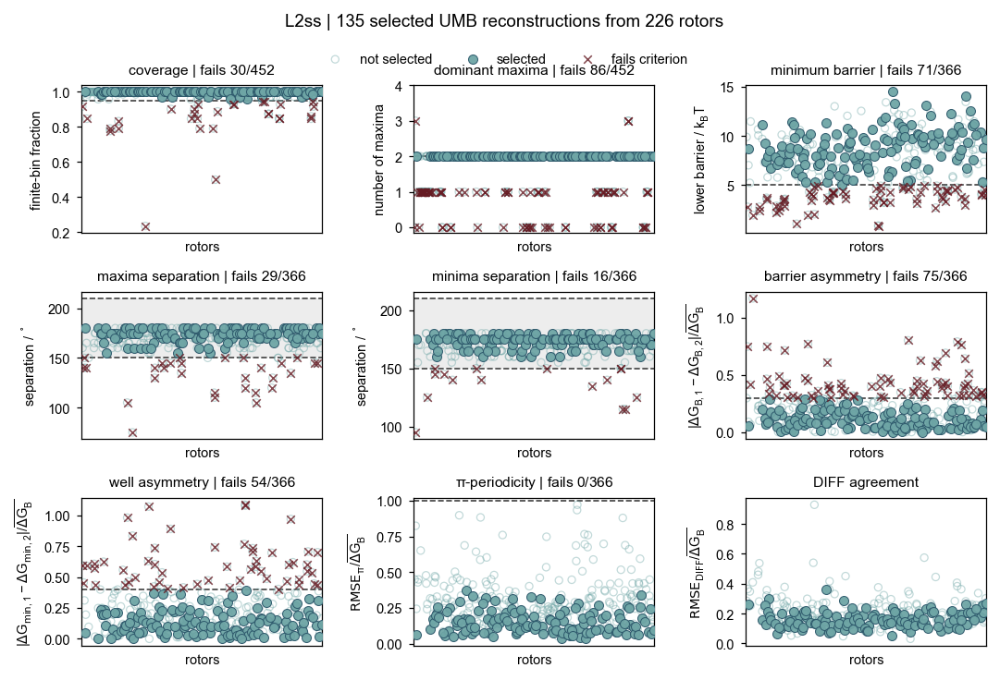

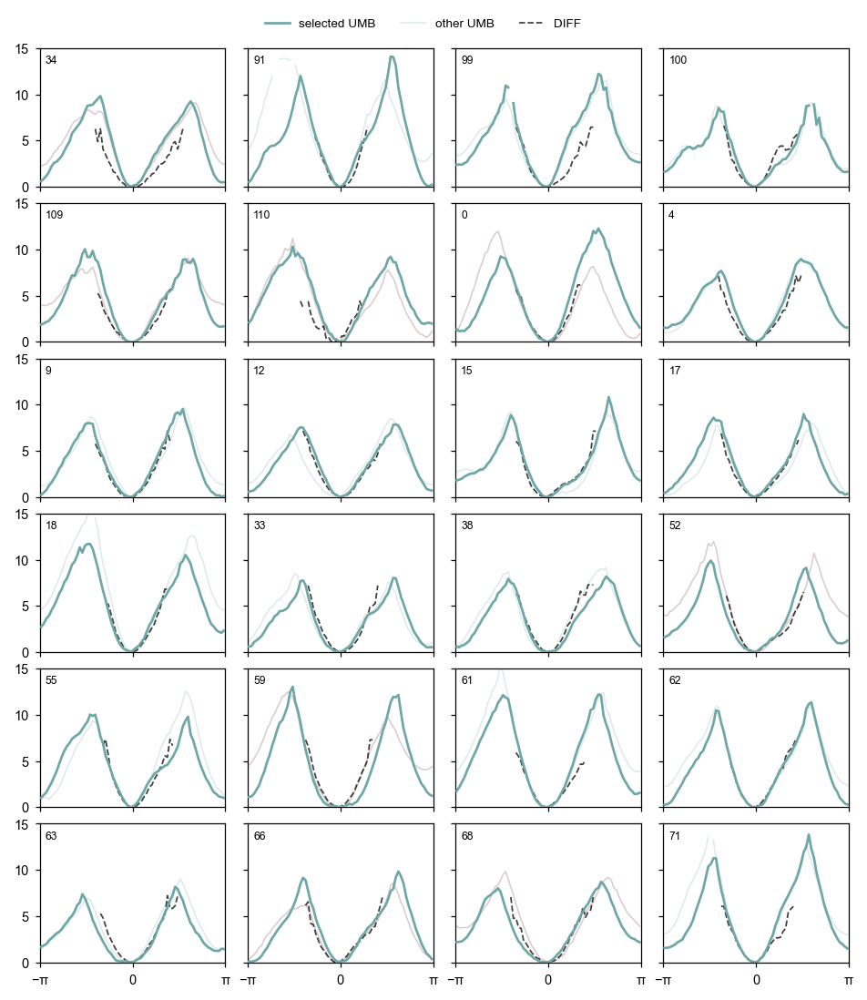

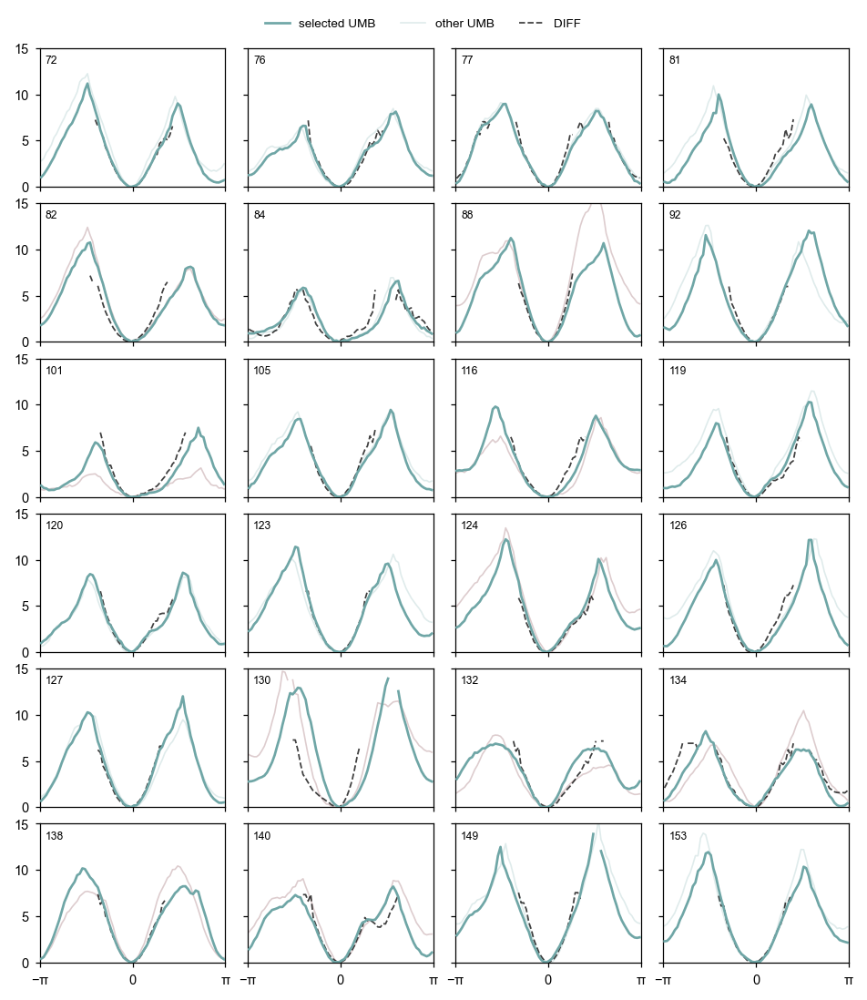

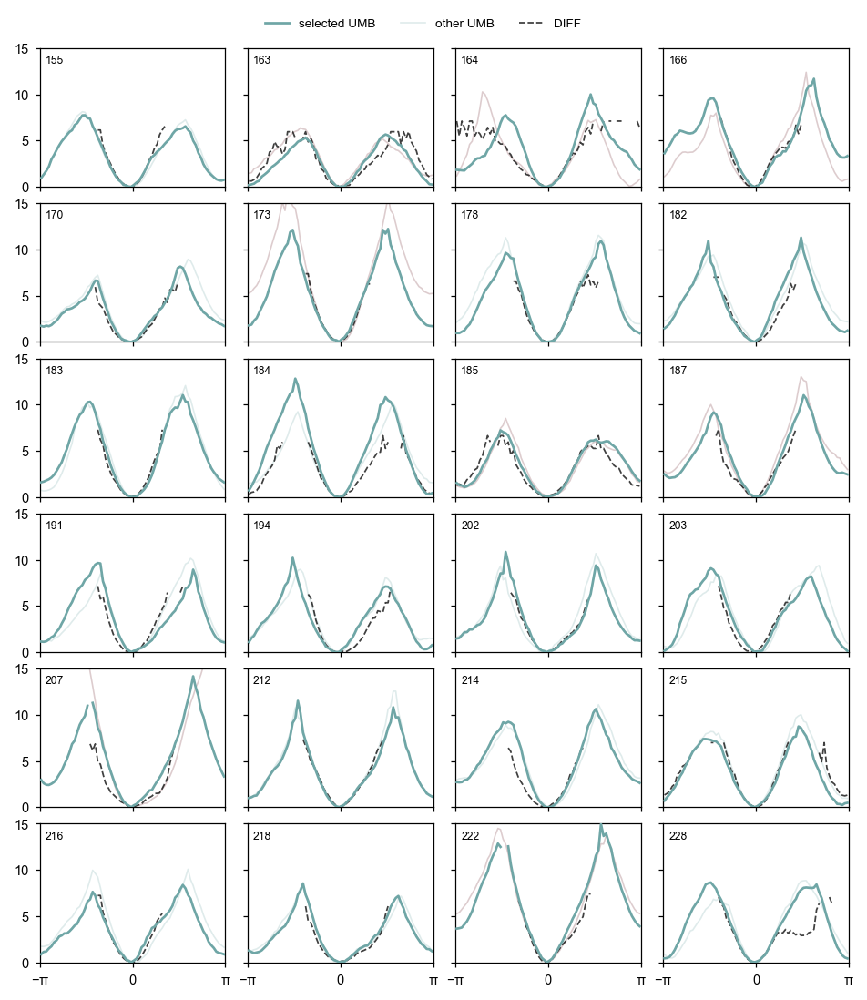

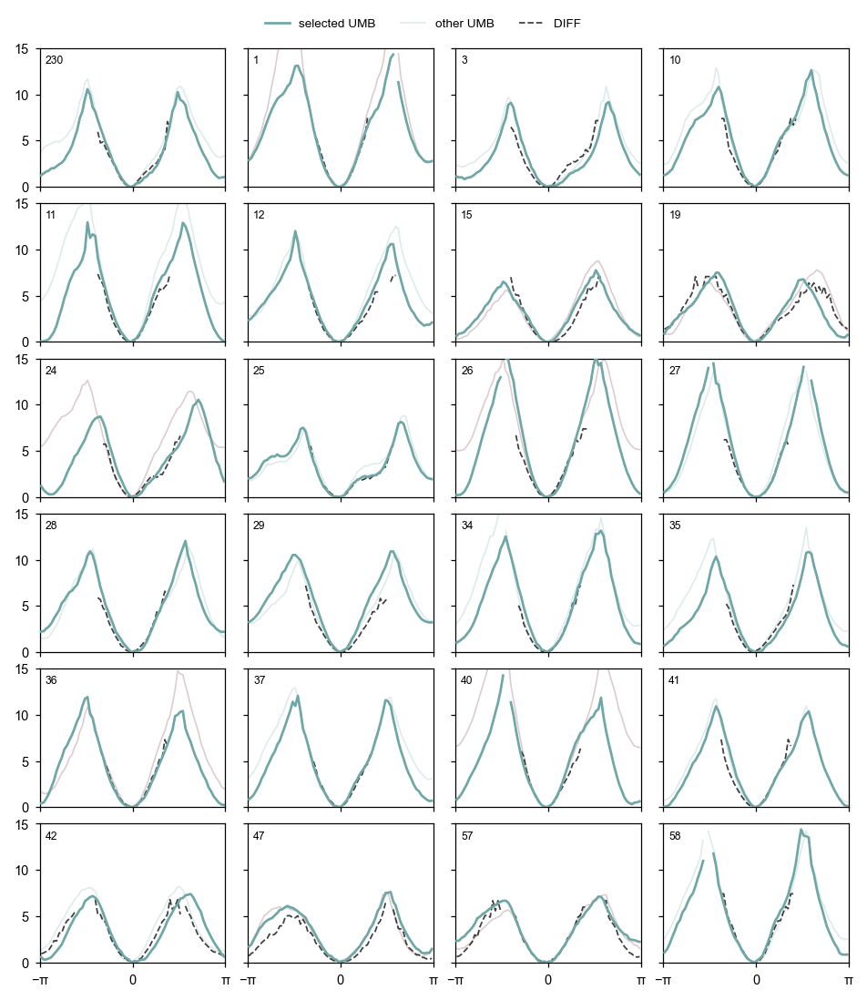

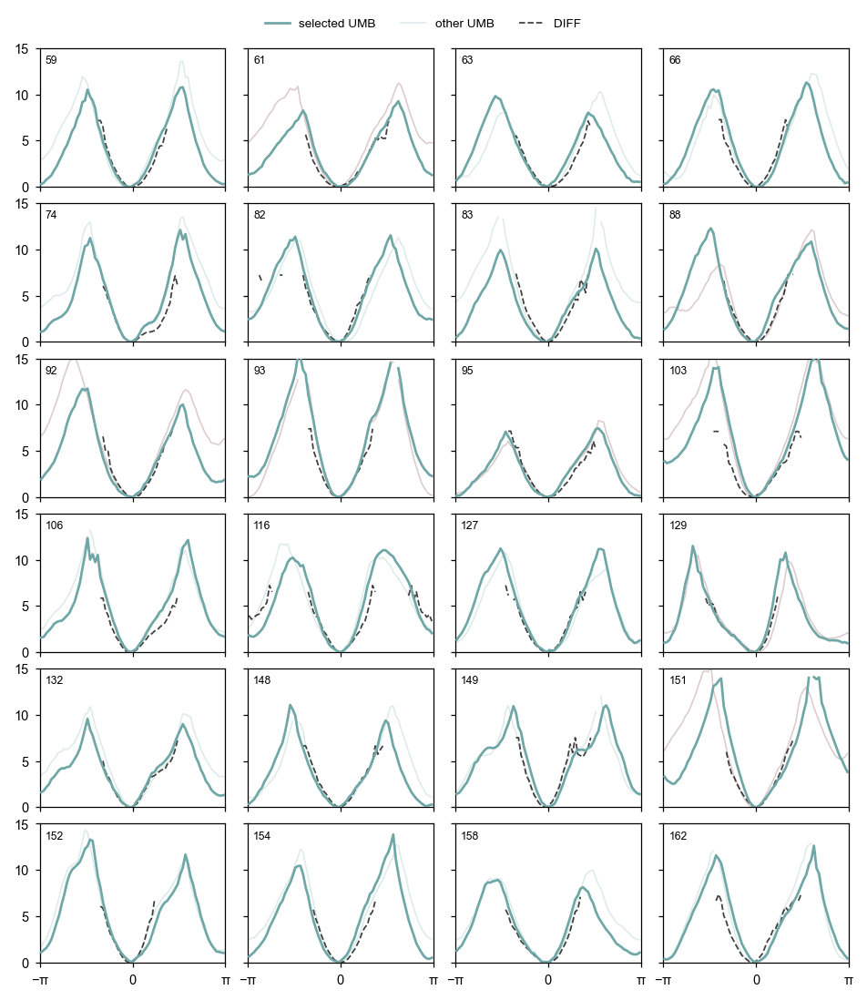

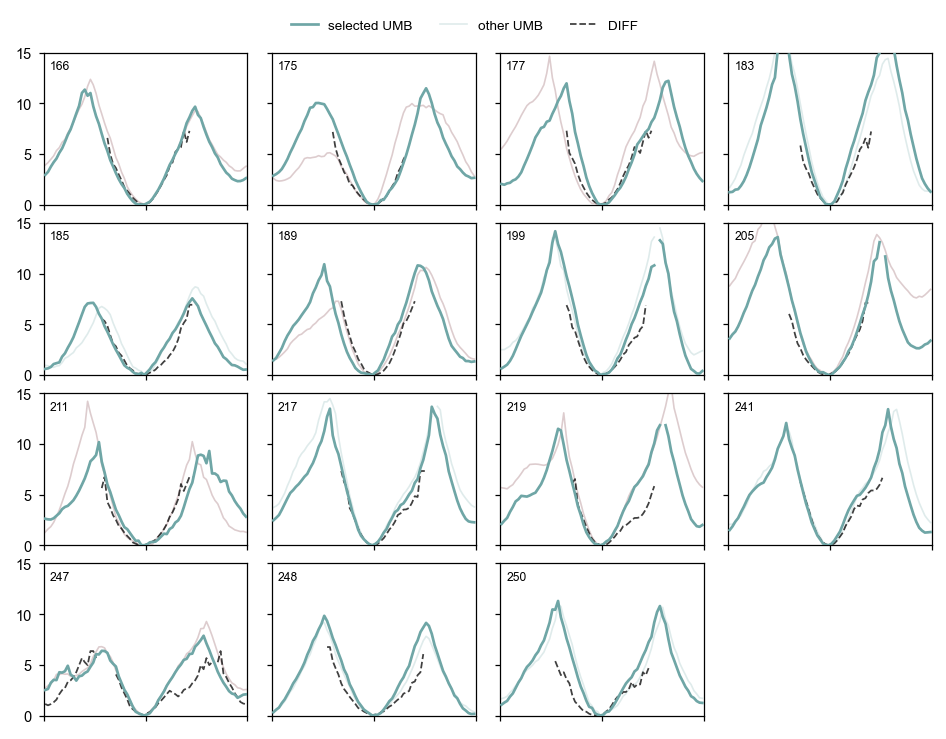

L3ss: 195/681 UMB reconstructions passed | 126/341 rotors retained | 215 rotors rejected


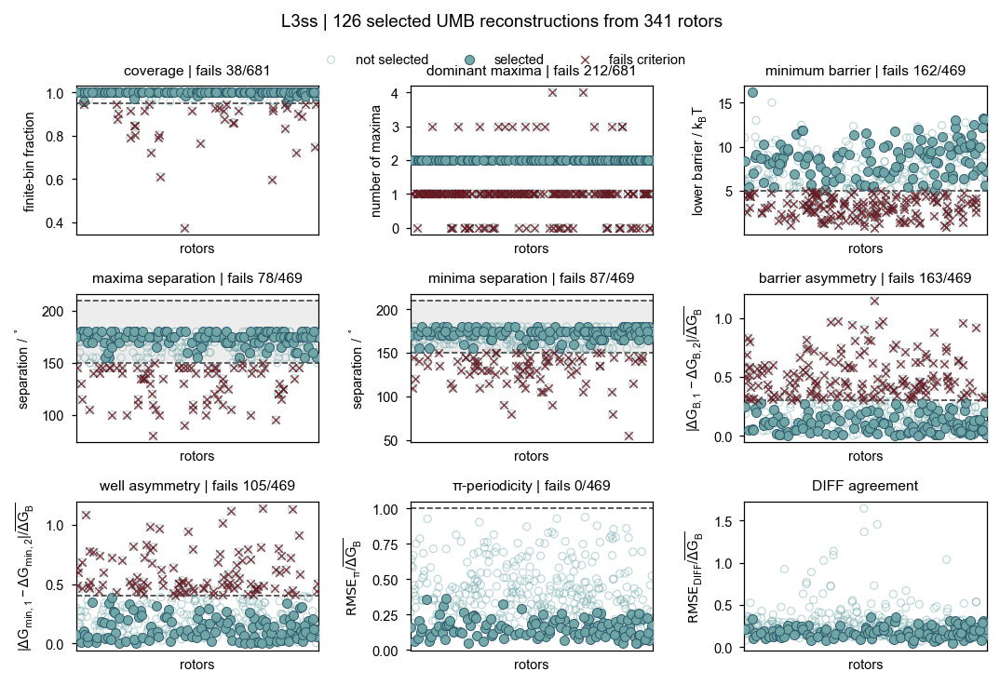

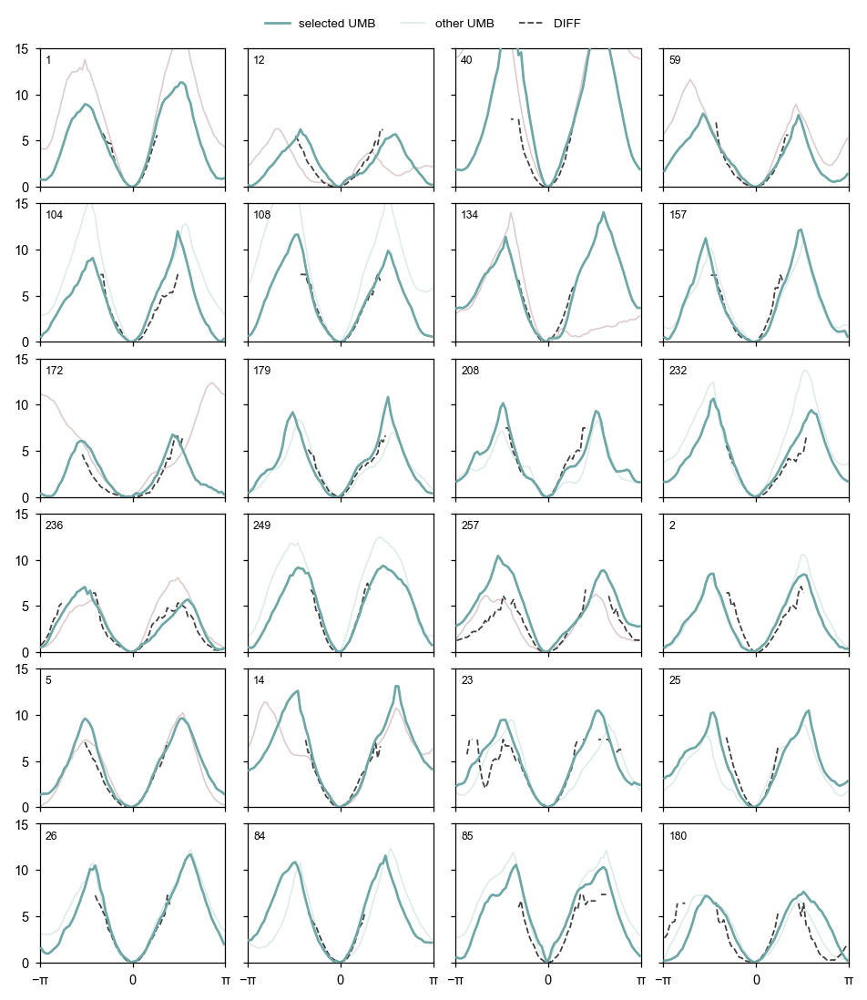

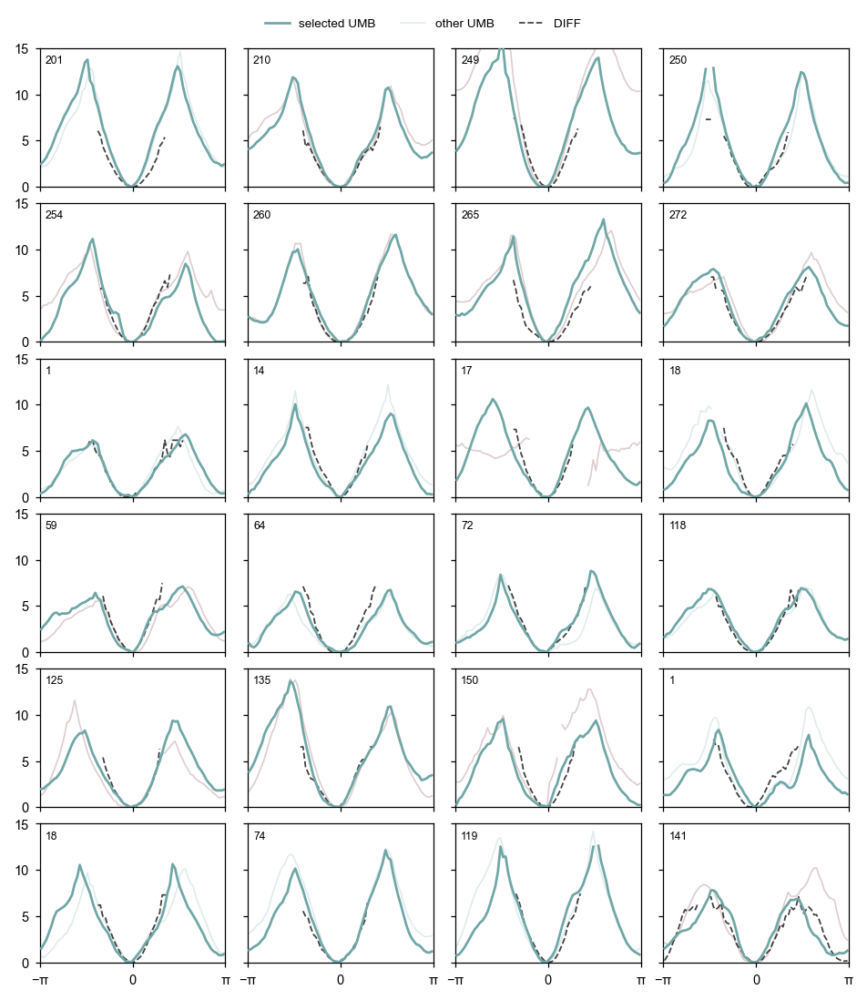

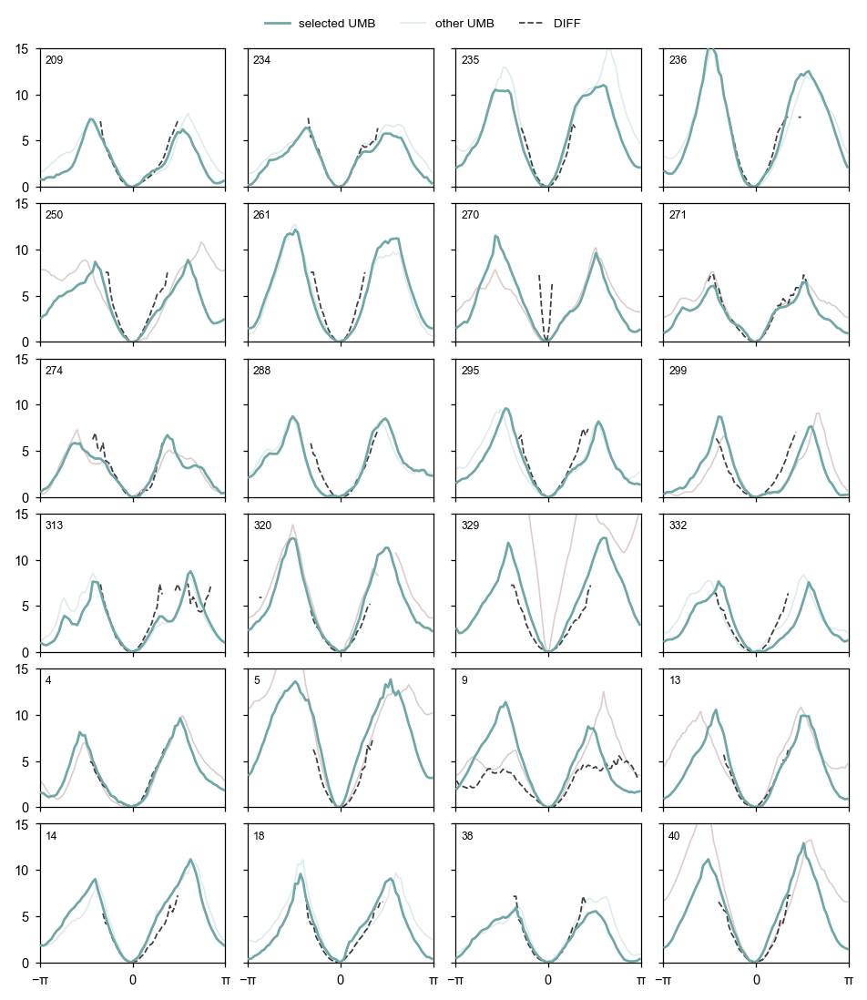

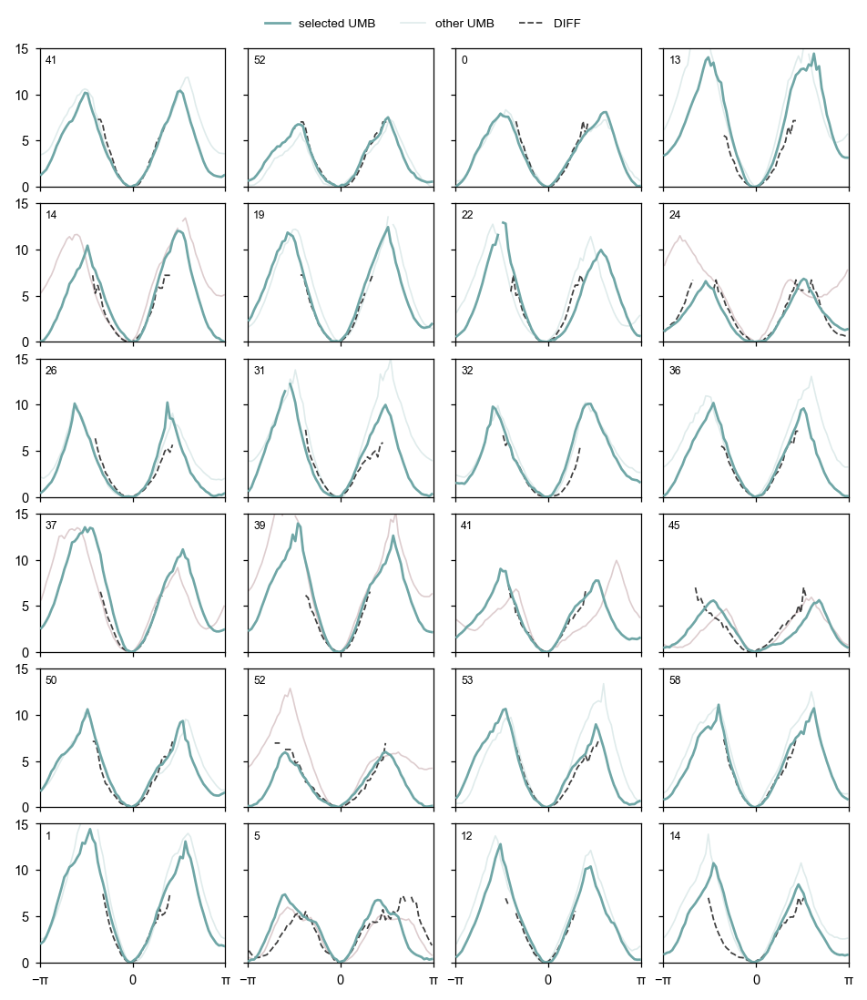

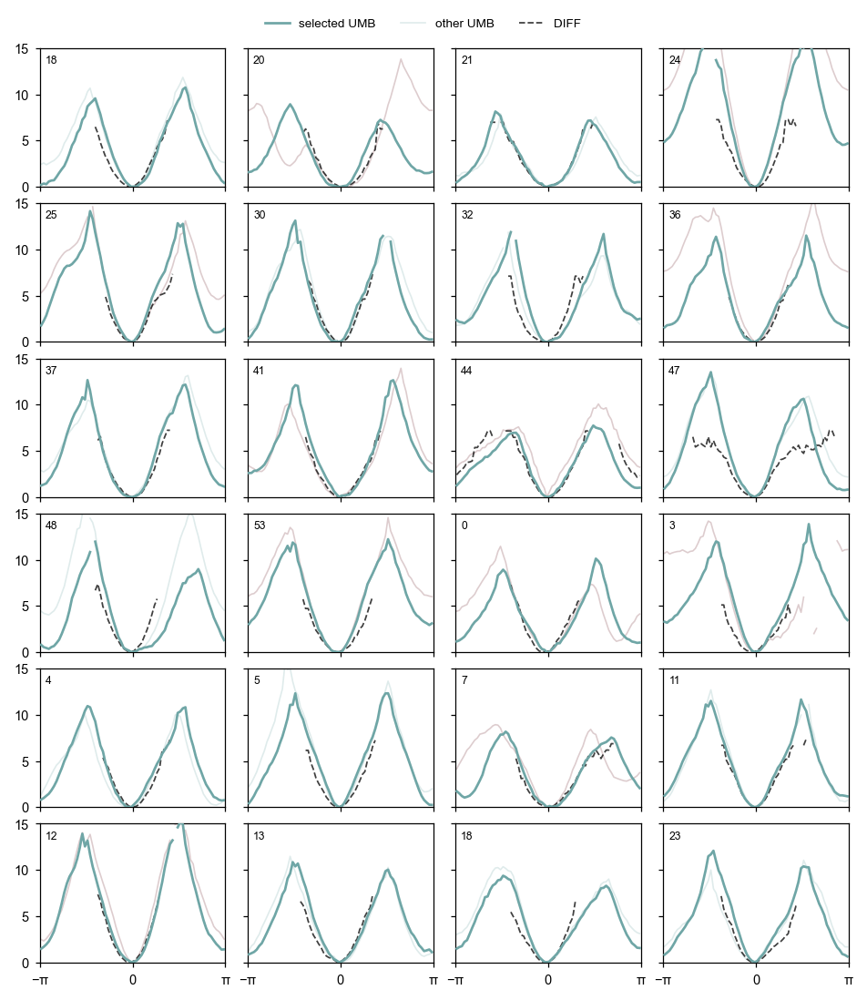

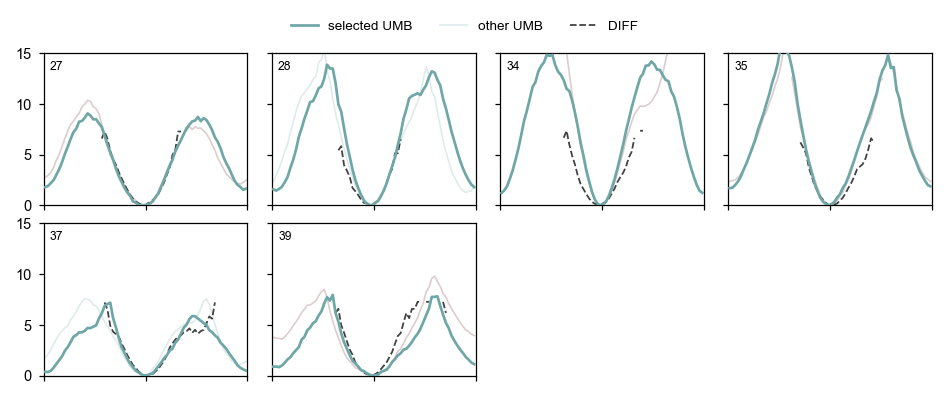

L4ss: 457/1051 UMB reconstructions passed | 290/526 rotors retained | 236 rotors rejected


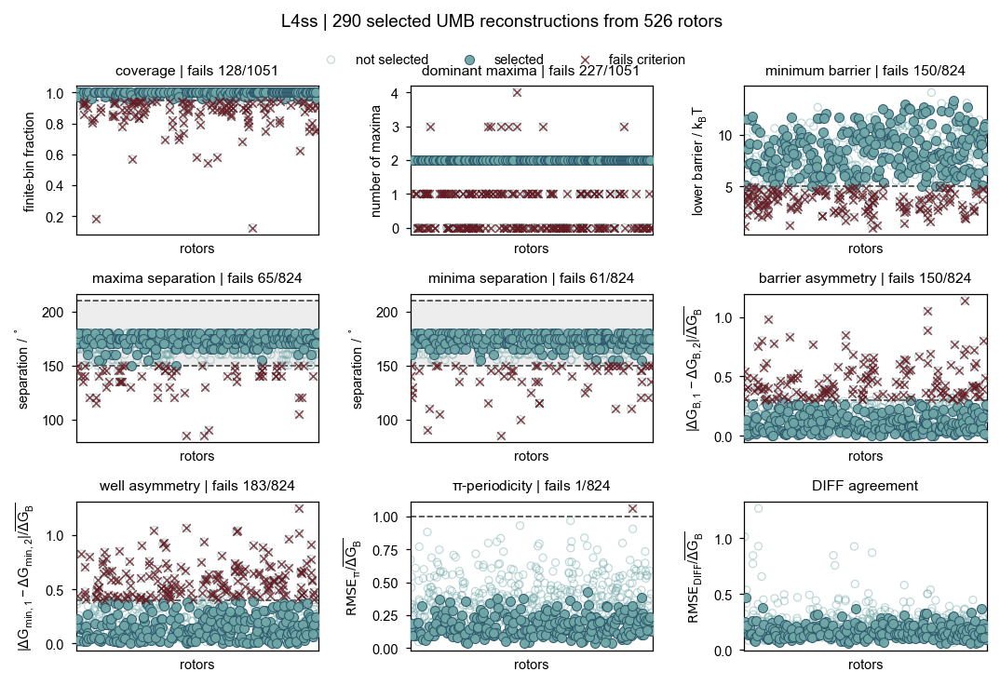

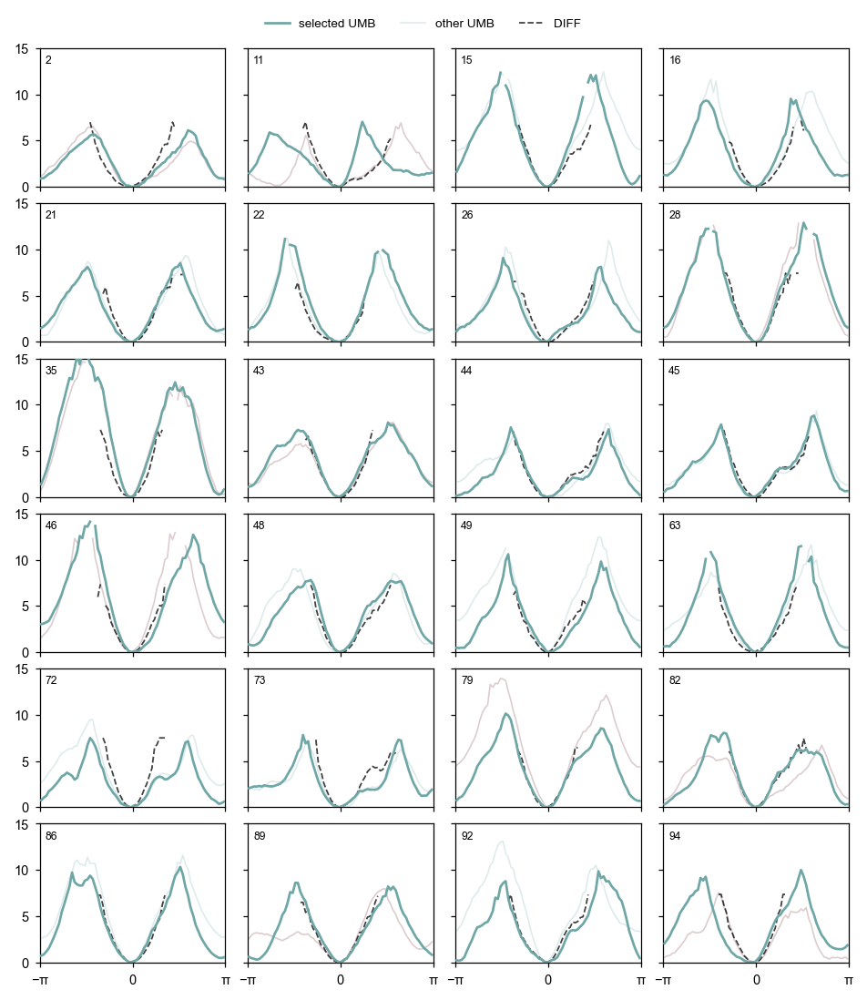

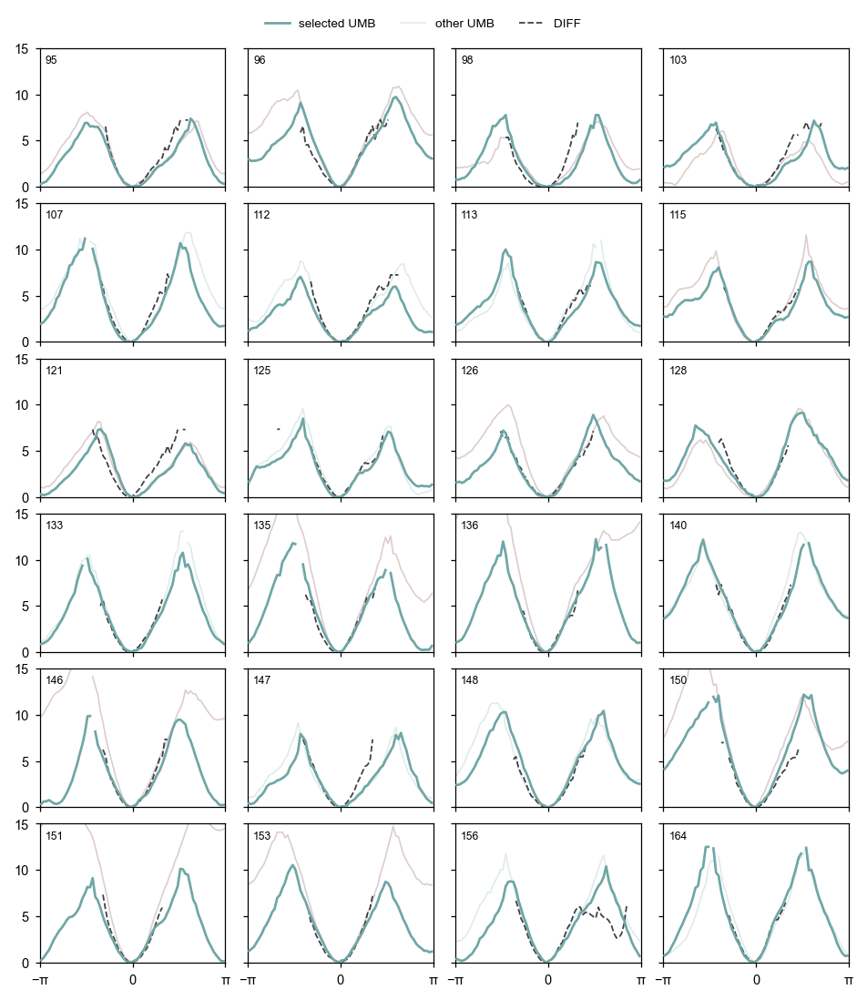

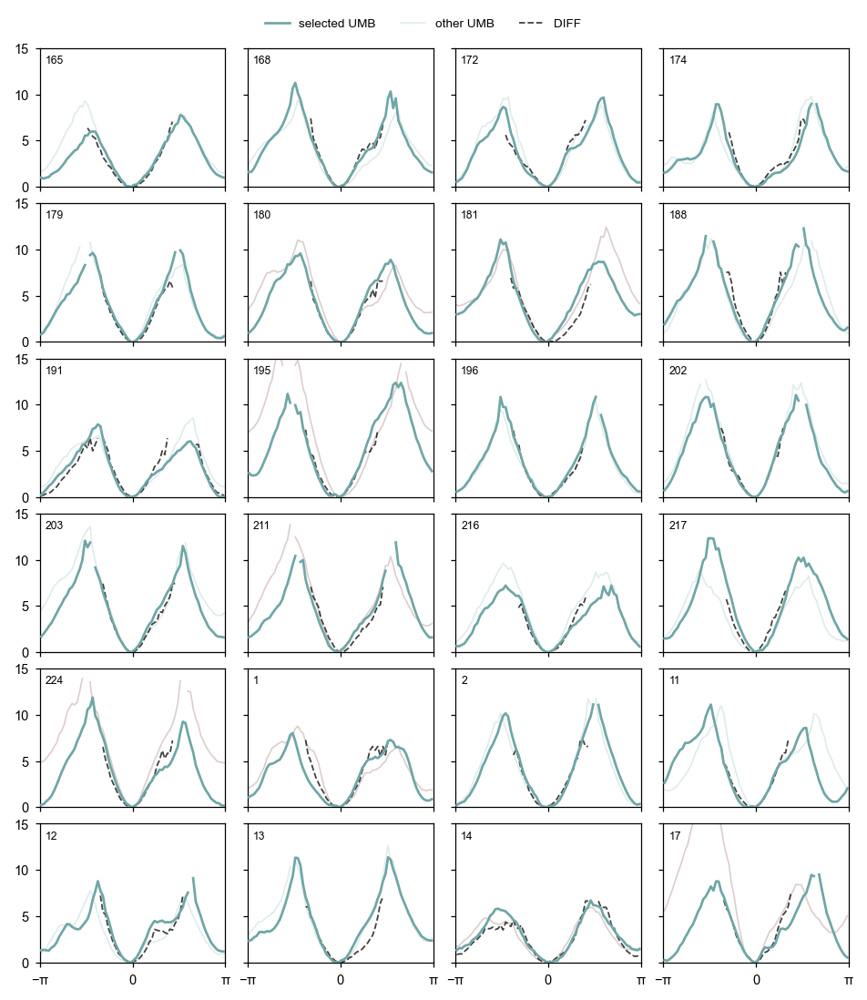

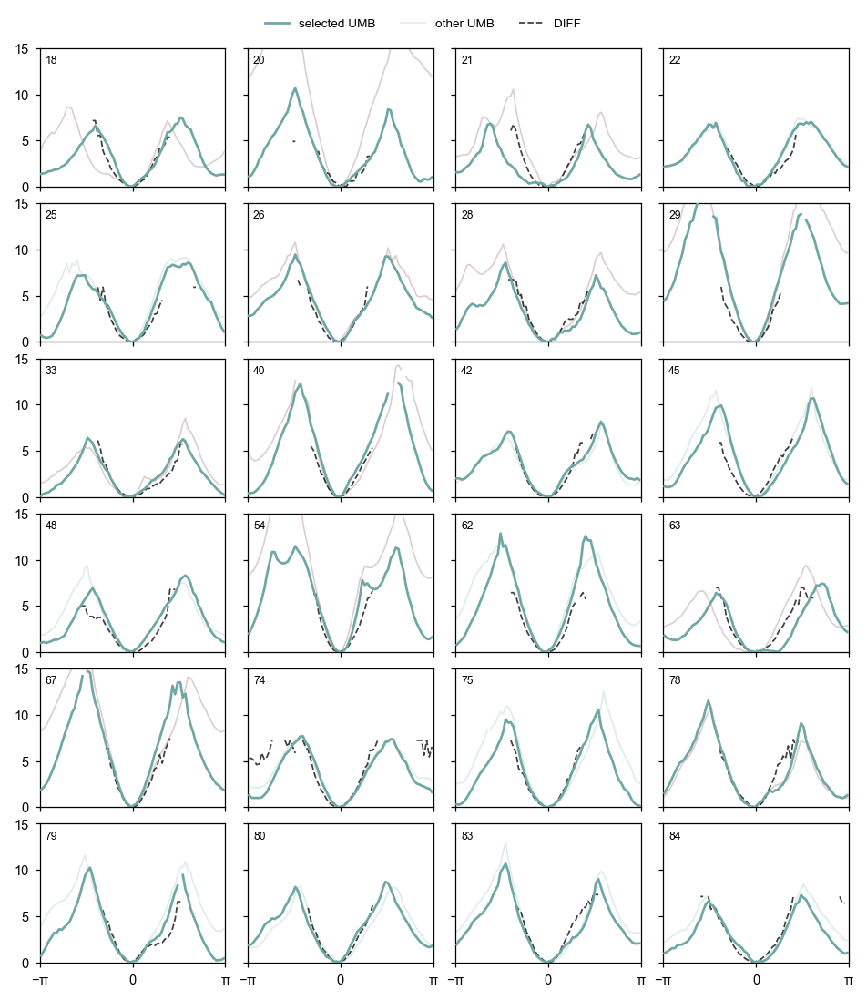

...

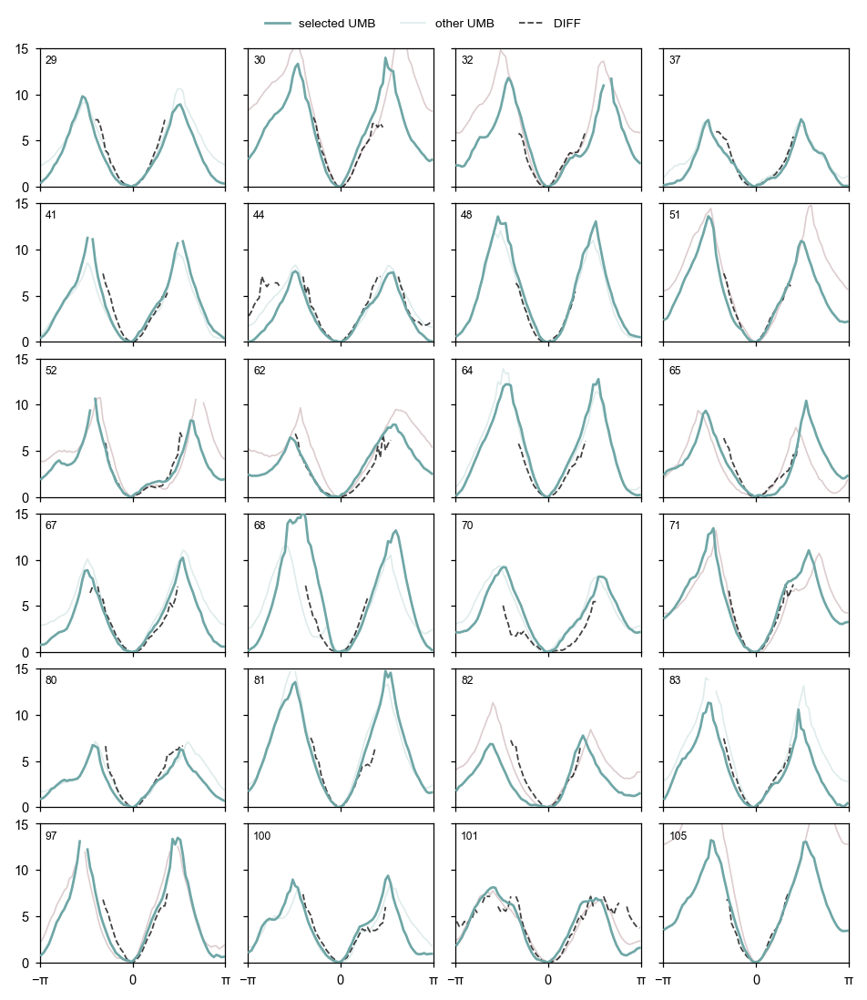

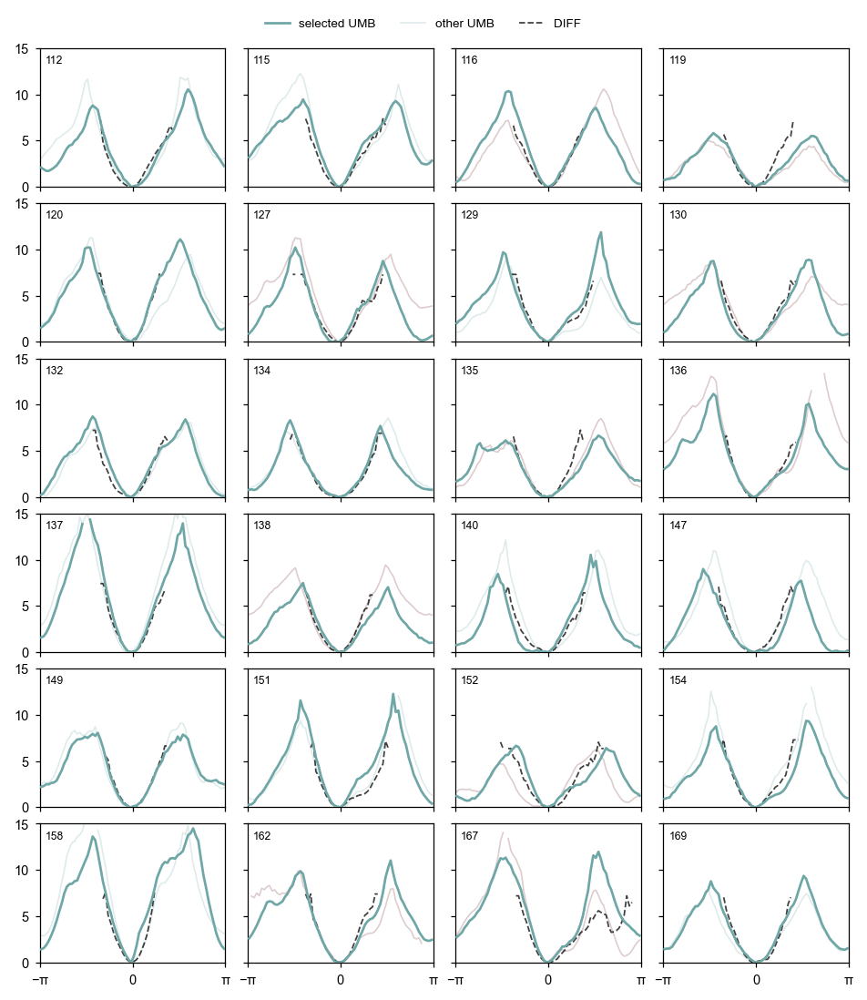

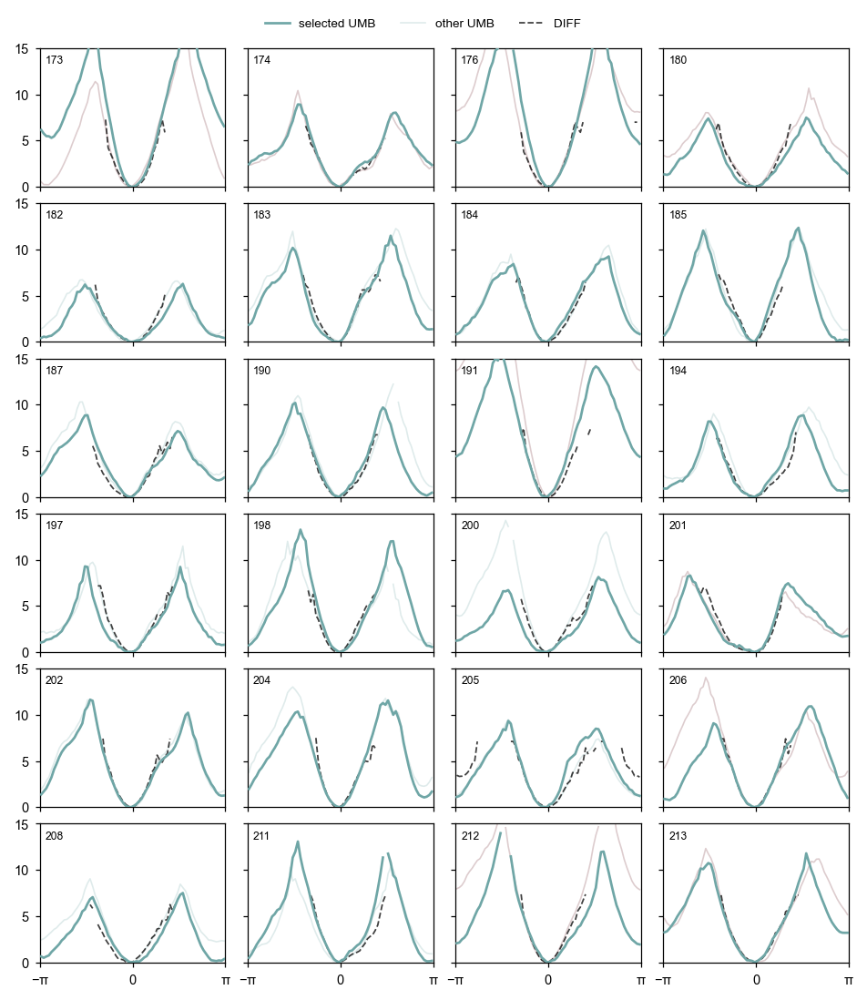

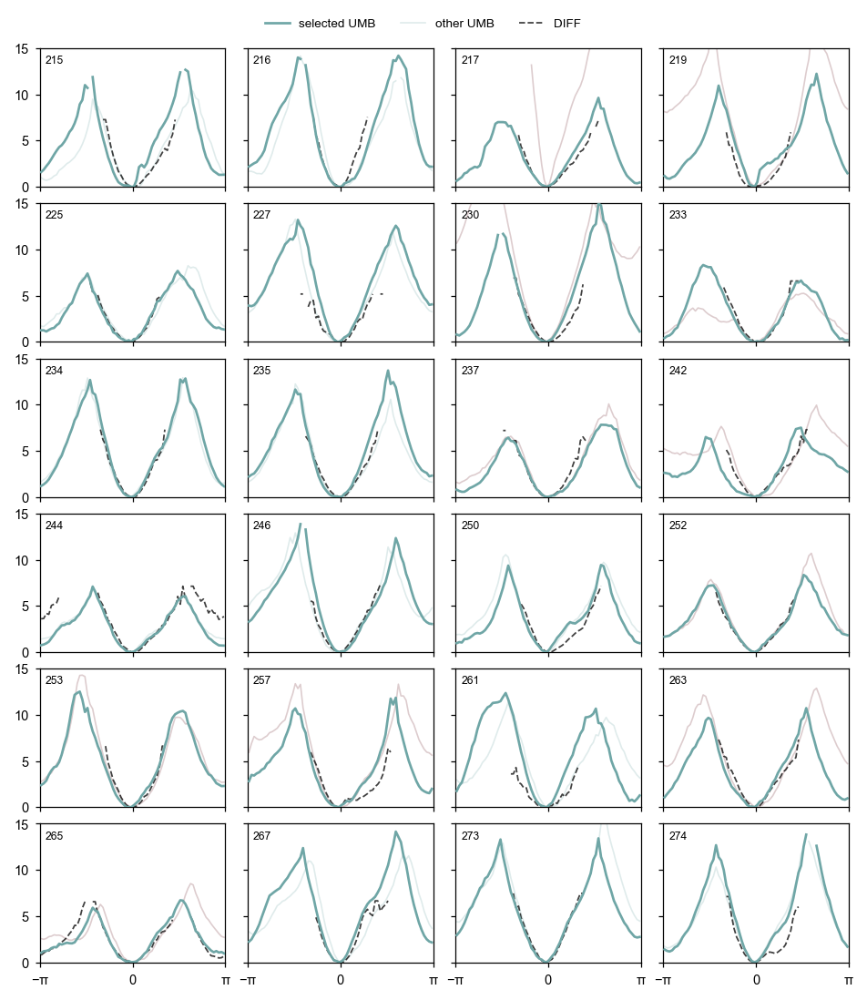

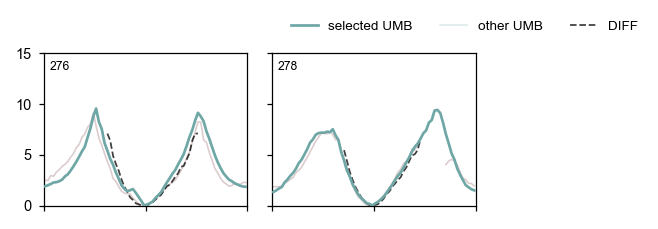

In [13]:
filtered_energy_landscapes = filter_energy_landscapes(
    energy_landscapes_by_stator=energy_landscapes_by_stator,
    stator_variant="all", #["L4ss", "L3ss"],

    min_coverage=0.95,
    min_prominence_fraction=0.2, #0.2
    smooth_nbins=3,

    maxima_separation_tolerance_deg=30,
    minima_separation_tolerance_deg=30,

    min_barrier_kBT=5.0,
    max_barrier_asymmetry=0.3,
    max_well_depth_difference_fraction=0.4,

    use_pi_periodicity_filter=True,
    max_pi_rmse_fraction=1,

    use_diff_rmse_for_selection=True,
    allow_diff_pi_flip=False,
    diff_fit_range_deg=(-90, 90),

    selection_weight_pi=1.0,
    selection_weight_well=1.0,
    selection_weight_barrier=1.0,
    selection_weight_minima_separation=0.2,
    selection_weight_maxima_separation=0.2,
    selection_weight_diff_rmse=1,

    align_main_minimum_to_zero=True,

    show_metric_overview=True,
    show_landscape_galleries=True,
    show_rejected_gallery=False,

    gallery_ncols=4,
    gallery_nrows=6,
    gallery_panel_width_mm=40,
    gallery_panel_height_mm=32,
    gallery_ylim=15,

    C=CK_colors,
)

### Figure 4

#### Analysis

In [14]:
#%% ============================================================================
# 1) PUBLICATION ANALYSIS — RUN ONCE
#
# Computes ONLY what is required for:
#   1. compute_stator_shape_features(...)
#   2. plot_publication_stator(...)
#
# Stored in top_records:
#   - aligned absolute landscape
#   - left/right barrier locations and heights
#   - mean barrier height
#   - 90%-barrier widths and width asymmetry
#   - q20-q80 selection
#
# Stored in bottom_records:
#   - aligned central absolute landscape
#   - normalized branch coordinate u = phi / phi_b
#   - normalized LEFT slope
#   - normalized RIGHT slope
#   - left/right/mean barrier heights
#
# Removed:
#   - old shoulder classification
#   - shoulder thresholds/prominence/flattening
#   - normalized curvature storage
#   - normalized branch-energy storage
#   - full-landscape normalized slope
#   - old top_table / bottom_table
# ============================================================================

def analyze_publication_stator(
    filtered_energy_landscapes,
    stator_variants=("L2ss", "L3ss", "L4ss"),
    percentile_limits=(20, 80),
    top_central_min_search_deg=45,
    top_minimum_barrier_distance_deg=30,
    top_maximum_barrier_distance_deg=150,
    top_barrier_location_smooth_nbins=1,
    barrier_fraction=0.90,
    analysis_half_range_deg=135,
    smooth_nbins=3,
    branch_smooth_nbins=5,
    n_branch_points=80,
    minimum_barrier_distance_deg=30,
    maximum_barrier_distance_deg=150,
    minimum_barrier_kBT=1.0,
    C=None,
):
    import numpy as np

    # -------------------------------------------------------------------------
    # helpers
    # -------------------------------------------------------------------------

    def get_colors(colors):
        if colors is None:
            colors = CK_colors() if "CK_colors" in globals() and callable(CK_colors) else {}
        elif callable(colors):
            colors = colors()

        colors = dict(colors)
        colors.setdefault("target_teal", (73/255, 139/255, 167/255))
        colors.setdefault("orange", (198/255, 131/255, 41/255))
        colors.setdefault("darkred", (102/255, 27/255, 35/255))
        colors.setdefault("darkblue", (46/255, 89/255, 108/255))
        colors.setdefault("grey", (0.40, 0.40, 0.40))
        colors.setdefault("lightgrey", (0.80, 0.80, 0.80))
        colors.setdefault("black", (0, 0, 0))
        return colors

    def circular_interpolate(y):
        y = np.asarray(y, float)
        finite = np.isfinite(y)
        if finite.sum() < 2:
            return np.full_like(y, np.nan)

        x = np.arange(len(y), dtype=float)
        return np.interp(x, x[finite], y[finite], period=len(y))

    def smooth_1d(y, width):
        y = np.asarray(y, float)
        width = int(width)

        if width <= 1:
            return y.copy()

        if width % 2 == 0:
            width += 1

        half = width // 2
        padded = np.pad(y, half, mode="edge")
        return np.convolve(padded, np.ones(width) / width, mode="valid")

    def circular_smooth(y, width):
        y = np.asarray(y, float)
        width = int(width)

        if width <= 1:
            return y.copy()

        if width % 2 == 0:
            width += 1

        half = width // 2
        padded = np.r_[y[-half:], y, y[:half]]
        return np.convolve(padded, np.ones(width) / width, mode="valid")

    def crossing_distance(x, energy, level):
        x = np.asarray(x, float)
        energy = np.asarray(energy, float)

        if len(x) < 2 or not np.isfinite(level):
            return np.nan

        if level < np.nanmin(energy) or level > np.nanmax(energy):
            return np.nan

        for i in range(len(energy) - 1):
            y0, y1 = energy[i], energy[i + 1]

            if (y0 <= level <= y1) or (y1 <= level <= y0):
                if abs(y1 - y0) < 1e-12:
                    return float(0.5 * (x[i] + x[i + 1]))

                f = (level - y0) / (y1 - y0)
                return float(x[i] + f * (x[i + 1] - x[i]))

        return np.nan

    C = get_colors(C)
    variants = list(stator_variants)
    variant_colors = {
        "L2ss": C["target_teal"],
        "L3ss": C["orange"],
        "L4ss": C["darkred"],
    }

    qlo, qhi = map(float, percentile_limits)

    # =========================================================================
    # TOP ANALYSIS
    # Used for:
    #   - explainer landscape
    #   - barrier-height boxplot
    #   - width-asymmetry boxplot
    #   - conversion of normalized extrema to absolute phi
    # =========================================================================

    def process_top(phi, raw_energy):
        raw_energy = np.asarray(raw_energy, float)
        E_quant = circular_interpolate(raw_energy)

        if not np.isfinite(E_quant).all():
            return None

        E_locator = (
            E_quant.copy()
            if int(top_barrier_location_smooth_nbins) <= 1
            else circular_smooth(E_quant, top_barrier_location_smooth_nbins)
        )

        phi_deg = np.degrees(phi)
        center_idx = np.where(np.abs(phi_deg) <= float(top_central_min_search_deg))[0]

        if not len(center_idx):
            return None

        minimum_index = int(center_idx[np.argmin(E_locator[center_idx])])
        zero_index = int(np.argmin(np.abs(phi)))
        shift = zero_index - minimum_index

        E_raw = np.roll(raw_energy, shift)
        E_quant = np.roll(E_quant, shift)
        E_locator = np.roll(E_locator, shift)

        E0 = float(E_quant[zero_index])
        E_quant -= E0
        E_locator -= E_locator[zero_index]
        E_raw = E_raw - E_raw[zero_index] if np.isfinite(E_raw[zero_index]) else E_raw - E0

        left_search = (
            (phi_deg <= -float(top_minimum_barrier_distance_deg))
            & (phi_deg >= -float(top_maximum_barrier_distance_deg))
        )

        right_search = (
            (phi_deg >= float(top_minimum_barrier_distance_deg))
            & (phi_deg <= float(top_maximum_barrier_distance_deg))
        )

        if not left_search.any() or not right_search.any():
            return None

        left_candidates = np.where(left_search)[0]
        right_candidates = np.where(right_search)[0]

        iL = int(left_candidates[np.argmax(E_locator[left_candidates])])
        iR = int(right_candidates[np.argmax(E_locator[right_candidates])])

        if not (iL < zero_index < iR):
            return None

        GL = float(E_raw[iL]) if np.isfinite(E_raw[iL]) else float(E_quant[iL])
        GR = float(E_raw[iR]) if np.isfinite(E_raw[iR]) else float(E_quant[iR])

        if GL <= 0 or GR <= 0:
            return None

        left_idx = np.arange(zero_index, iL - 1, -1)
        right_idx = np.arange(zero_index, iR + 1)

        xL = np.abs(phi[left_idx] - phi[zero_index])
        xR = np.abs(phi[right_idx] - phi[zero_index])

        eL = E_quant[left_idx]
        eR = E_quant[right_idx]

        # common 90%-barrier level, as in your previous analysis
        level = float(barrier_fraction * min(GL, GR))

        wL = crossing_distance(xL, eL, level)
        wR = crossing_distance(xR, eR, level)

        return {
            "phi_rad": phi.copy(),
            "energy_raw": E_raw.copy(),

            "minimum_index": zero_index,
            "left_barrier_index": iL,
            "right_barrier_index": iR,

            "left_barrier_raw": GL,
            "right_barrier_raw": GR,
            "mean_barrier_raw": 0.5 * (GL + GR),

            # full minimum -> barrier angular distances
            # required for physical-coordinate conversion
            "left_width_deg": float(np.degrees(xL[-1])),
            "right_width_deg": float(np.degrees(xR[-1])),

            # 90%-barrier widths used in the global metric panel
            "barrier_level_90": level,
            "left_width_90_deg": float(np.degrees(wL)) if np.isfinite(wL) else np.nan,
            "right_width_90_deg": float(np.degrees(wR)) if np.isfinite(wR) else np.nan,
            "width_difference_90_deg": (
                float(np.degrees(wR - wL))
                if np.isfinite(wL) and np.isfinite(wR)
                else np.nan
            ),
        }

    # =========================================================================
    # BOTTOM ANALYSIS
    #
    # Only generates what the current shape analysis / main figure uses.
    # =========================================================================

    def process_bottom(phi, raw_energy):
        energy = circular_interpolate(raw_energy)

        if not np.isfinite(energy).all():
            return None

        energy = circular_smooth(energy, smooth_nbins)

        # align minimum to phi = 0
        minimum_index = int(np.nanargmin(energy))
        zero_index = int(np.argmin(np.abs(phi)))

        energy = np.roll(energy, zero_index - minimum_index)
        energy -= energy[zero_index]

        phi_deg = np.degrees(phi)

        central_mask = np.abs(phi_deg) <= float(analysis_half_range_deg)

        phi_c = phi[central_mask]
        phi_c_deg = phi_deg[central_mask]
        energy_c = energy[central_mask]

        zero_c = int(np.argmin(np.abs(phi_c)))

        # locate left/right barriers
        left_search = (
            (phi_c_deg <= -float(minimum_barrier_distance_deg))
            & (phi_c_deg >= -float(maximum_barrier_distance_deg))
        )

        right_search = (
            (phi_c_deg >= float(minimum_barrier_distance_deg))
            & (phi_c_deg <= float(maximum_barrier_distance_deg))
        )

        if not left_search.any() or not right_search.any():
            return None

        left_candidates = np.where(left_search)[0]
        right_candidates = np.where(right_search)[0]

        iL = int(left_candidates[np.nanargmax(energy_c[left_candidates])])
        iR = int(right_candidates[np.nanargmax(energy_c[right_candidates])])

        if not (iL < zero_c < iR):
            return None

        left_indices = np.arange(zero_c, iL - 1, -1)
        right_indices = np.arange(zero_c, iR + 1)

        xL = np.abs(phi_c[left_indices] - phi_c[zero_c])
        xR = np.abs(phi_c[right_indices] - phi_c[zero_c])

        eL = energy_c[left_indices]
        eR = energy_c[right_indices]

        if len(xL) < 5 or len(xR) < 5:
            return None

        barrier_L = float(eL[-1])
        barrier_R = float(eR[-1])

        if barrier_L < float(minimum_barrier_kBT) or barrier_R < float(minimum_barrier_kBT):
            return None

        # ---------------------------------------------------------------------
        # normalized branch coordinate and normalized branch energies
        #
        # theta = phi / phi_b
        # G~    = G / DeltaG_b
        # ---------------------------------------------------------------------

        u = np.linspace(0, 1, int(n_branch_points))

        gL = np.interp(u, xL / xL[-1], eL / barrier_L)
        gR = np.interp(u, xR / xR[-1], eR / barrier_R)

        gL = smooth_1d(gL, branch_smooth_nbins)
        gR = smooth_1d(gR, branch_smooth_nbins)

        # enforce exact normalized boundary conditions
        gL[0], gL[-1] = 0.0, 1.0
        gR[0], gR[-1] = 0.0, 1.0

        # ---------------------------------------------------------------------
        # normalized slopes used in the main figure and later extrema analysis
        # ---------------------------------------------------------------------

        du = float(np.mean(np.diff(u)))

        slopeL = smooth_1d(
            np.gradient(gL, du),
            branch_smooth_nbins,
        )

        slopeR = smooth_1d(
            np.gradient(gR, du),
            branch_smooth_nbins,
        )

        return {
            # absolute landscape for consensus panel
            "phi_rad": phi_c.copy(),
            "energy_kBT": energy_c.copy(),

            # normalized branch coordinate
            "u": u.copy(),

            # only branch quantities needed downstream
            "left_slope_normalized": slopeL.copy(),
            "right_slope_normalized": slopeR.copy(),

            # needed for absolute extrema conversion
            "left_barrier_height_kBT": barrier_L,
            "right_barrier_height_kBT": barrier_R,
            "mean_barrier_height_kBT": 0.5 * (barrier_L + barrier_R),
        }

    # =========================================================================
    # PROCESS ALL LANDSCAPES
    # =========================================================================

    top_records = []
    source_lookup = {}

    for variant in variants:
        data = filtered_energy_landscapes[variant]

        phi_raw = np.angle(
            np.exp(
                1j * np.asarray(data["phi_rad"], float)
            )
        )

        order = np.argsort(phi_raw)
        phi = phi_raw[order]

        energies = np.asarray(
            data["energy_kBT"],
            float,
        )[:, order]

        particle_ids = np.asarray(
            data["particle_ids"],
            int,
        )

        for i, raw_energy in enumerate(energies):
            top = process_top(phi, raw_energy)

            if top is None:
                continue

            top.update({
                "stator_variant": variant,
                "particle_id": int(particle_ids[i]),
                "original_index": int(i),
                "selected": False,
            })

            top_records.append(top)

            source_lookup[(variant, int(i))] = {
                "phi": phi.copy(),
                "raw_energy": raw_energy.copy(),
            }

    # =========================================================================
    # q20-q80 BARRIER SELECTION
    # =========================================================================

    thresholds = {}

    for variant in variants:
        current = [
            r
            for r in top_records
            if r["stator_variant"] == variant
        ]

        if not current:
            thresholds[variant] = (np.nan, np.nan)
            continue

        values = np.asarray(
            [r["mean_barrier_raw"] for r in current],
            float,
        )

        lower, upper = np.nanpercentile(
            values,
            [qlo, qhi],
        )

        thresholds[variant] = (
            float(lower),
            float(upper),
        )

        for r in current:
            r["selected"] = bool(
                lower
                <= r["mean_barrier_raw"]
                <= upper
            )

    # =========================================================================
    # BOTTOM PROCESSING ONLY FOR SELECTED ROTORS
    # =========================================================================

    bottom_records = []

    for top in top_records:
        if not top["selected"]:
            continue

        src = source_lookup[
            (
                top["stator_variant"],
                top["original_index"],
            )
        ]

        bottom = process_bottom(
            src["phi"],
            src["raw_energy"],
        )

        if bottom is None:
            continue

        bottom.update({
            "stator_variant": top["stator_variant"],
            "particle_id": top["particle_id"],
            "original_index": top["original_index"],
            "selection_mean_barrier_raw": top["mean_barrier_raw"],
        })

        bottom_records.append(bottom)

    # =========================================================================
    # SUMMARY
    # =========================================================================

    print("\nSELECTION / BOTTOM-PROCESSING SUMMARY")
    print("=" * 88)

    for variant in variants:
        current = [
            r for r in top_records
            if r["stator_variant"] == variant
        ]

        selected = [
            r for r in current
            if r["selected"]
        ]

        bottom = [
            r for r in bottom_records
            if r["stator_variant"] == variant
        ]

        lo, hi = thresholds[variant]

        print(
            f"{variant}: "
            f"raw q{qlo:g}={lo:.2f} | "
            f"q{qhi:g}={hi:.2f} kBT | "
            f"selected={len(selected)}/{len(current)} | "
            f"bottom valid={len(bottom)}"
        )

    # =========================================================================
    # MINIMAL RETURN OBJECT
    # =========================================================================

    return {
        "top_records": top_records,
        "bottom_records": bottom_records,
        "thresholds": thresholds,
        "variant_colors": variant_colors,
        "C": C,
        "settings": {
            "percentile_limits": percentile_limits,
            "barrier_fraction": float(barrier_fraction),
            "analysis_half_range_deg": float(analysis_half_range_deg),
            "smooth_nbins": int(smooth_nbins),
            "branch_smooth_nbins": int(branch_smooth_nbins),
            "n_branch_points": int(n_branch_points),
        },
    }

In [15]:
publication_analysis = analyze_publication_stator(
    filtered_energy_landscapes=filtered_energy_landscapes,
    stator_variants=("L2ss", "L3ss", "L4ss"),

    # retain middle 60% of barrier-height distribution
    percentile_limits=(20, 80),

    # top/global landscape processing
    top_central_min_search_deg=45,
    top_minimum_barrier_distance_deg=30,
    top_maximum_barrier_distance_deg=150,
    top_barrier_location_smooth_nbins=1,
    barrier_fraction=0.90,

    # branch analysis
    analysis_half_range_deg=135,
    smooth_nbins=3,
    branch_smooth_nbins=5,
    n_branch_points=80,
    minimum_barrier_distance_deg=30,
    maximum_barrier_distance_deg=150,
    minimum_barrier_kBT=1.0,

    C=CK_colors,
)


SELECTION / BOTTOM-PROCESSING SUMMARY
L2ss: raw q20=8.36 | q80=12.11 kBT | selected=81/135 | bottom valid=81
L3ss: raw q20=7.88 | q80=12.27 kBT | selected=76/126 | bottom valid=76
L4ss: raw q20=7.75 | q80=12.25 kBT | selected=174/290 | bottom valid=174


#### Plotting

#### previous version

In [16]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from pathlib import Path
# from scipy.signal import savgol_filter


# def plot_publication_stator(
#     publication_analysis,
#     fig_width_mm=180, fig_height_mm=92, energy_ylim=(-0.5, 13.0),
#     center="median", band="iqr", min_consensus_count=3, consensus_lw=1.7,
#     point_size=8, point_alpha_all=0.11, point_alpha_selected=0.62,
#     landscape_scalebar_kBT=5.0, explainer_width_ratio=1.40,
#     top_wspace=0.30, bottom_wspace=0.30,
#     explainer_variant="L2ss", explainer_particle_id=None, explainer_mode="median_barrier",
#     slope_smooth_window=11, slope_smooth_polyorder=3,
#     curvature_smooth_window=7, curvature_smooth_polyorder=2,
#     slope_max_search_range=(0.10, 0.75), slope_min_search_max=0.90,
#     min_negative_width=0.04, min_abs_curvature=0.05,
#     save_dir=None, save_svg=False, save_prefix="publication_stator_final",
# ):
#     top_records = publication_analysis["top_records"]
#     bottom_records = publication_analysis["bottom_records"]
#     variant_colors = publication_analysis["variant_colors"]
#     C = publication_analysis["C"]

#     variants = list(dict.fromkeys(r["stator_variant"] for r in top_records))
#     variant_labels = {"L2ss": "outer", "L3ss": "dual", "L4ss": "inner"}

#     def mm(x): return float(x) / 25.4

#     def style_ax(ax):
#         ax.tick_params(direction="out", length=2.4, width=0.6, labelsize=7)
#         for s in ax.spines.values():
#             s.set_linewidth(0.6)
#             s.set_color(C["black"])
#         ax.grid(False)

#     def style_energy_ax(ax):
#         ax.spines["left"].set_visible(False)
#         ax.spines["right"].set_visible(False)
#         ax.spines["top"].set_visible(False)
#         ax.spines["bottom"].set_linewidth(0.7)
#         ax.spines["bottom"].set_color(C["black"])
#         ax.tick_params(axis="x", direction="out", length=2.4, width=0.6, labelsize=7)
#         ax.tick_params(axis="y", left=False, labelleft=False)
#         ax.grid(False)

#     def set_rad_ticks(ax):
#         ax.set_xticks([-np.pi, 0, np.pi])
#         ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])

#     def quantiles(matrix):
#         matrix = np.asarray(matrix, float)
#         mid = np.nanmean(matrix, axis=0) if str(center).lower() == "mean" else np.nanmedian(matrix, axis=0)
#         if band is None: return mid, None, None
#         if str(band).lower() == "std":
#             sd = np.nanstd(matrix, axis=0)
#             return mid, mid - sd, mid + sd
#         return mid, np.nanpercentile(matrix, 25, axis=0), np.nanpercentile(matrix, 75, axis=0)

#     def draw_consensus(ax, x, matrix, color, label=None, alpha_fill=0.11, lw=None):
#         matrix = np.asarray(matrix, float)
#         if matrix.ndim != 2 or len(matrix) < min_consensus_count: return
#         mid, lo, hi = quantiles(matrix)
#         if lo is not None: ax.fill_between(x, lo, hi, color=color, alpha=alpha_fill, lw=0)
#         ax.plot(x, mid, color=color, lw=consensus_lw if lw is None else lw, label=label)

#     def add_energy_scalebar(ax, height=5.0):
#         ymin, ymax = ax.get_ylim()
#         x0, y0 = np.pi - 0.40, ymin + 0.08 * (ymax - ymin)
#         ax.plot([x0, x0], [y0, y0 + height], color=C["black"], lw=0.9, clip_on=False)
#         ax.text(x0 - 0.10, y0 + height / 2, rf"{height:g} $k_BT$", ha="right", va="center", fontsize=5.8)

#     def smooth_signal(y, window, polyorder):
#         y = np.asarray(y, float)
#         window, polyorder = int(window), int(polyorder)
#         if len(y) < 5 or window <= 1: return y.copy()
#         if window % 2 == 0: window += 1
#         max_window = len(y) if len(y) % 2 else len(y) - 1
#         window = min(window, max_window)
#         if window <= polyorder:
#             window = polyorder + 2
#             if window % 2 == 0: window += 1
#         if window > max_window or window < 3: return y.copy()
#         return savgol_filter(y, window_length=window, polyorder=min(polyorder, window - 1), mode="interp")

#     def zero_crossings(x, y):
#         x, y = np.asarray(x, float), np.asarray(y, float)
#         out = []
#         for i in range(len(y) - 1):
#             y0, y1 = y[i], y[i + 1]
#             if not np.isfinite(y0) or not np.isfinite(y1): continue
#             if y0 > 0 and y1 <= 0: direction = "+-"
#             elif y0 < 0 and y1 >= 0: direction = "-+"
#             else: continue
#             xc = 0.5 * (x[i] + x[i + 1]) if abs(y1 - y0) < 1e-15 else x[i] + (-y0 / (y1 - y0)) * (x[i + 1] - x[i])
#             out.append({"u": float(xc), "direction": direction})
#         return out

#     def boxplot_with_points(ax, values_all, selected_values=None, zero_line=False, seed=4):
#         bp = ax.boxplot(
#             values_all, positions=np.arange(len(variants)), widths=0.50, patch_artist=True,
#             showfliers=False, whis=(5, 95),
#             medianprops=dict(color=C["black"], linewidth=1.0),
#             boxprops=dict(color=C["black"], linewidth=0.6),
#             whiskerprops=dict(color=C["black"], linewidth=0.6),
#             capprops=dict(color=C["black"], linewidth=0.6),
#         )
#         for patch, v in zip(bp["boxes"], variants):
#             patch.set_facecolor(variant_colors[v])
#             patch.set_alpha(0.30)

#         rng = np.random.default_rng(seed)
#         for i, (v, vals) in enumerate(zip(variants, values_all)):
#             vals = np.asarray(vals, float)
#             vals = vals[np.isfinite(vals)]
#             ax.scatter(np.full(len(vals), i) + rng.normal(0, 0.05, len(vals)), vals,
#                        s=point_size, facecolor=variant_colors[v], edgecolor="none",
#                        alpha=point_alpha_all, zorder=2)

#             if selected_values is not None:
#                 sel = np.asarray(selected_values[i], float)
#                 sel = sel[np.isfinite(sel)]
#                 ax.scatter(np.full(len(sel), i) + rng.normal(0, 0.043, len(sel)), sel,
#                            s=point_size + 1, facecolor=variant_colors[v], edgecolor=C["black"],
#                            linewidth=0.15, alpha=point_alpha_selected, zorder=4)

#         if zero_line: ax.axhline(0, color=C["grey"], lw=0.65, ls=":")
#         ax.set_xticks(np.arange(len(variants)))
#         ax.set_xticklabels([variant_labels.get(v, v) for v in variants])
#         style_ax(ax)

#     def paired_boxstrip(ax, values_open, values_filled, ylabel, label_open, label_filled, seed=22):
#         pos_open = np.arange(len(variants)) - 0.15
#         pos_fill = np.arange(len(variants)) + 0.15

#         bp_o = ax.boxplot(
#             values_open, positions=pos_open, widths=0.24, patch_artist=True, showfliers=False, whis=(5, 95),
#             medianprops=dict(color=C["black"], linewidth=0.9),
#             boxprops=dict(color=C["black"], linewidth=0.55),
#             whiskerprops=dict(color=C["black"], linewidth=0.55),
#             capprops=dict(color=C["black"], linewidth=0.55),
#         )

#         bp_f = ax.boxplot(
#             values_filled, positions=pos_fill, widths=0.24, patch_artist=True, showfliers=False, whis=(5, 95),
#             medianprops=dict(color=C["black"], linewidth=0.9),
#             boxprops=dict(color=C["black"], linewidth=0.55),
#             whiskerprops=dict(color=C["black"], linewidth=0.55),
#             capprops=dict(color=C["black"], linewidth=0.55),
#         )

#         for patch, v in zip(bp_o["boxes"], variants):
#             patch.set_facecolor("white")
#             patch.set_edgecolor(variant_colors[v])

#         for patch, v in zip(bp_f["boxes"], variants):
#             patch.set_facecolor(variant_colors[v])
#             patch.set_alpha(0.30)

#         rng = np.random.default_rng(seed)

#         for i, v in enumerate(variants):
#             a = np.asarray(values_open[i], float)
#             b = np.asarray(values_filled[i], float)
#             a, b = a[np.isfinite(a)], b[np.isfinite(b)]

#             ax.scatter(np.full(len(a), pos_open[i]) + rng.normal(0, 0.025, len(a)), a,
#                        s=point_size, facecolor="none", edgecolor=variant_colors[v],
#                        linewidth=0.45, alpha=0.50, zorder=4)

#             ax.scatter(np.full(len(b), pos_fill[i]) + rng.normal(0, 0.025, len(b)), b,
#                        s=point_size, facecolor=variant_colors[v], edgecolor="none",
#                        alpha=0.50, zorder=4)

#         ax.scatter([], [], s=18, facecolor="none", edgecolor=C["grey"], linewidth=0.6, label=label_open)
#         ax.scatter([], [], s=18, facecolor=C["grey"], edgecolor="none", label=label_filled)
#         ax.legend(frameon=False, fontsize=5.8, loc="upper left", handletextpad=0.25)
#         ax.set_xticks(np.arange(len(variants)))
#         ax.set_xticklabels([variant_labels.get(v, v) for v in variants])
#         ax.set_ylabel(ylabel, fontsize=7)
#         style_ax(ax)

#     # =========================================================================
#     # SELECT EXPLAINER
#     # =========================================================================

#     candidates = [r for r in top_records if r["stator_variant"] == explainer_variant and r["selected"]]
#     if not candidates: raise ValueError(f"No selected {explainer_variant} records available.")

#     example = None

#     if explainer_particle_id is not None:
#         matches = [r for r in candidates if int(r["particle_id"]) == int(explainer_particle_id)]
#         if matches: example = matches[0]

#     if example is None:
#         if str(explainer_mode).lower() == "largest_width_asymmetry":
#             vals = np.asarray([abs(r["width_difference_90_deg"]) for r in candidates], float)
#             example = candidates[int(np.nanargmax(vals))]
#         else:
#             vals = np.asarray([r["mean_barrier_raw"] for r in candidates], float)
#             example = candidates[int(np.nanargmin(np.abs(vals - np.nanmedian(vals))))]

#     # =========================================================================
#     # LOOKUP TOP RECORD FOR PHYSICAL RIGHT-BARRIER ANGLE
#     # =========================================================================

#     top_lookup = {(r["stator_variant"], int(r["particle_id"])): r for r in top_records}

#     def get_phi_b(top):
#         phi = np.asarray(top["phi_rad"], float)
#         i0 = int(top["minimum_index"])
#         iR = int(top["right_barrier_index"])
#         dphi = float(phi[iR] - phi[i0])

#         if dphi <= 0:
#             dphi += 2 * np.pi

#         if np.isfinite(dphi) and dphi > 0:
#             return dphi

#         return np.radians(float(top["right_width_deg"]))

#     # =========================================================================
#     # RIGHT-FLANK EXTREMA + ABSOLUTE CONVERSION
#     # =========================================================================

#     feature_rows = []

#     for r in bottom_records:
#         key = (r["stator_variant"], int(r["particle_id"]))

#         if key not in top_lookup:
#             continue

#         top = top_lookup[key]

#         u = np.asarray(r["u"], float)
#         slope_raw = np.asarray(r["right_slope_normalized"], float)

#         finite = np.isfinite(u) & np.isfinite(slope_raw)
#         u, slope_raw = u[finite], slope_raw[finite]

#         if len(u) < 10:
#             continue

#         slope = smooth_signal(slope_raw, slope_smooth_window, slope_smooth_polyorder)
#         curvature = smooth_signal(np.gradient(slope, u), curvature_smooth_window, curvature_smooth_polyorder)

#         crossings = zero_crossings(u, curvature)

#         maxima = [
#             z for z in crossings
#             if z["direction"] == "+-" and slope_max_search_range[0] <= z["u"] <= slope_max_search_range[1]
#         ]

#         minima = [
#             z for z in crossings
#             if z["direction"] == "-+" and z["u"] <= slope_min_search_max
#         ]

#         events = []

#         for zmax in maxima:
#             following = [z for z in minima if z["u"] > zmax["u"]]

#             if not following:
#                 continue

#             zmin = following[0]

#             theta_max = float(zmax["u"])
#             theta_min = float(zmin["u"])

#             region = (u >= theta_max) & (u <= theta_min)

#             if not region.any():
#                 continue

#             ids = np.where(region)[0]

#             events.append({
#                 "theta_s_max": theta_max,
#                 "theta_s_min": theta_min,
#                 "s_max": float(np.interp(theta_max, u, slope)),
#                 "s_min": float(np.interp(theta_min, u, slope)),
#                 "delta_theta": theta_min - theta_max,
#                 "kappa_min": float(np.nanmin(curvature[ids])),
#             })

#         if not events:
#             continue

#         event = min(events, key=lambda x: x["kappa_min"])

#         if event["delta_theta"] < min_negative_width:
#             continue

#         if event["kappa_min"] > -min_abs_curvature:
#             continue

#         phi_b = get_phi_b(top)
#         barrier = float(r["right_barrier_height_kBT"])

#         if not np.isfinite(phi_b) or phi_b <= 0 or not np.isfinite(barrier) or barrier <= 0:
#             continue

#         event["phi_s_max"] = event["theta_s_max"] * phi_b
#         event["phi_s_min"] = event["theta_s_min"] * phi_b

#         event["s_abs_max"] = barrier / phi_b * event["s_max"]
#         event["s_abs_min"] = barrier / phi_b * event["s_min"]

#         feature_rows.append({
#             "stator_variant": r["stator_variant"],
#             "particle_id": int(r["particle_id"]),
#             "phi_b": phi_b,
#             "barrier_kBT": barrier,
#             **event,
#         })

#     feature_df = pd.DataFrame(feature_rows)

#     # =========================================================================
#     # FIGURE LAYOUT
#     # =========================================================================

#     fig = plt.figure(figsize=(mm(fig_width_mm), mm(fig_height_mm)))
#     outer = fig.add_gridspec(2, 1, height_ratios=(1.0, 1.0), hspace=0.38)

#     # TOP: first column wide, remaining three equal
#     gs_top = outer[0].subgridspec(
#         1, 4,
#         width_ratios=(1.8, 1.2, 0.8, 0.8),
#         wspace=top_wspace,
#     )

#     # BOTTOM: original requested widths
#     gs_bottom = outer[1].subgridspec(
#         1, 4,
#         width_ratios=(1, 1, 1.35, 1.35),
#         wspace=bottom_wspace,
#     )


#     ax_def = fig.add_subplot(gs_top[0, 0])
#     ax_cons = fig.add_subplot(gs_top[0, 1])
#     ax_barrier = fig.add_subplot(gs_top[0, 2])
#     ax_asym = fig.add_subplot(gs_top[0, 3])
#     ax_left     = fig.add_subplot(gs_bottom[0, 0])
#     ax_right    = fig.add_subplot(gs_bottom[0, 1], sharex=ax_left, sharey=ax_left)
#     ax_position = fig.add_subplot(gs_bottom[0, 2])
#     ax_value    = fig.add_subplot(gs_bottom[0, 3])

#     # =========================================================================
#     # TOP 1 — METRIC DEFINITION
#     # =========================================================================
#     phi = np.asarray(example["phi_rad"], float)
#     E = np.asarray(example["energy_raw"], float)

#     i0 = int(example["minimum_index"])
#     iL = int(example["left_barrier_index"])
#     iR = int(example["right_barrier_index"])

#     phi0, phiL, phiR = float(phi[i0]), float(phi[iL]), float(phi[iR])
#     G0 = float(E[i0]) if np.isfinite(E[i0]) else 0.0
#     GL, GR = float(example["left_barrier_raw"]), float(example["right_barrier_raw"])

#     level90 = float(example["barrier_level_90"])
#     wL90 = np.radians(float(example["left_width_90_deg"]))
#     wR90 = np.radians(float(example["right_width_90_deg"]))

#     ax_def.plot(phi, E, color=variant_colors[explainer_variant], lw=1.55, zorder=3)
#     ax_def.scatter([phiL, phi0, phiR], [GL, G0, GR], s=19, color=C["darkred"],
#                    edgecolor=C["black"], linewidth=0.25, zorder=5)

#     ax_def.vlines([phiL, phiR], G0, [GL, GR], color=C["grey"], lw=0.65, ls="--")
#     ax_def.axhline(G0 + level90, color=C["grey"], lw=0.55, ls=":")

#     if np.isfinite(wL90):
#         ax_def.annotate("", xy=(-wL90, G0 + level90), xytext=(phi0, G0 + level90),
#                         arrowprops=dict(arrowstyle="<->", color=C["darkblue"], lw=0.8))
#         ax_def.text(-0.5 * wL90, G0 + level90 + 0.30, r"$w_L$", ha="center", fontsize=6.5)

#     if np.isfinite(wR90):
#         ax_def.annotate("", xy=(wR90, G0 + level90), xytext=(phi0, G0 + level90),
#                         arrowprops=dict(arrowstyle="<->", color=C["darkblue"], lw=0.8))
#         ax_def.text(0.5 * wR90, G0 + level90 + 0.30, r"$w_R$", ha="center", fontsize=6.5)

#     ax_def.text(phiL + 0.12, G0 + 0.53 * (GL - G0), r"$\Delta G_L$", ha="left", va="center", fontsize=6.5)
#     ax_def.text(phiR - 0.12, G0 + 0.53 * (GR - G0), r"$\Delta G_R$", ha="right", va="center", fontsize=6.5)

#     ax_def.text(0.03, 0.94, r"$0.9\,\Delta G_b$", transform=ax_def.transAxes,
#                 ha="left", va="top", fontsize=6)

#     ax_def.axvline(0, color=C["grey"], lw=0.5, ls=":")
#     ax_def.set_xlim(-np.pi, np.pi)
#     ax_def.set_ylim(*energy_ylim)
#     ax_def.set_xlabel(r"$\varphi$ / rad", fontsize=7)

#     set_rad_ticks(ax_def)
#     style_energy_ax(ax_def)
#     add_energy_scalebar(ax_def, landscape_scalebar_kBT)

#     # =========================================================================
#     # TOP 2 — MEAN BARRIER
#     # =========================================================================
#     all_barriers = [
#         np.asarray([r["mean_barrier_raw"] for r in top_records if r["stator_variant"] == v], float)
#         for v in variants
#     ]

#     selected_barriers = [
#         np.asarray([r["mean_barrier_raw"] for r in top_records if r["stator_variant"] == v and r["selected"]], float)
#         for v in variants
#     ]

#     boxplot_with_points(ax_barrier, all_barriers, selected_values=selected_barriers, seed=4)
#     ax_barrier.set_ylabel(r"$\Delta G_b$ / $k_BT$", fontsize=7)
#     ax_barrier.set_ylim(5, 16)

#     # =========================================================================
#     # TOP 3 — WIDTH ASYMMETRY
#     # =========================================================================
#     all_width_values = []
#     selected_width_values = []

#     for v in variants:
#         all_deg = np.asarray(
#             [r["width_difference_90_deg"] for r in top_records if r["stator_variant"] == v],
#             float,
#         )

#         sel_deg = np.asarray(
#             [r["width_difference_90_deg"] for r in top_records if r["stator_variant"] == v and r["selected"]],
#             float,
#         )

#         all_width_values.append(np.radians(all_deg[np.isfinite(all_deg)]))
#         selected_width_values.append(np.radians(sel_deg[np.isfinite(sel_deg)]))

#     boxplot_with_points(
#         ax_asym,
#         all_width_values,
#         selected_values=selected_width_values,
#         zero_line=True,
#         seed=8,
#     )

#     ax_asym.set_ylabel(r"$\Delta w = w_R-w_L$ / rad", fontsize=7)
#     ax_asym.set_ylim(-0.55, 1.05)

#     # =========================================================================
#     # TOP 4 — ABSOLUTE CONSENSUS LANDSCAPE
#     # =========================================================================
#     for v in variants:
#         current = [r for r in bottom_records if r["stator_variant"] == v]

#         if len(current) >= min_consensus_count:
#             draw_consensus(
#                 ax_cons,
#                 current[0]["phi_rad"],
#                 np.asarray([r["energy_kBT"] for r in current]),
#                 variant_colors[v],
#                 label=variant_labels.get(v, v),
#                 alpha_fill=0.11,
#             )

#     ax_cons.axvline(0, color=C["grey"], lw=0.55, ls=":")
#     # ax_cons.set_xlim(-3/4 * np.pi, 3/4 * np.pi)
    
#     # Zoom consensus to 1.1 × the median barrier positions
#     phi_b_left = np.nanmedian([
#         np.radians(r["left_width_deg"])
#         for r in top_records if r["selected"]
#     ])
    
#     phi_b_right = np.nanmedian([
#         np.radians(r["right_width_deg"])
#         for r in top_records if r["selected"]
#     ])
    
#     ax_cons.set_xlim(-1.1 * phi_b_left, 1.1 * phi_b_right)

#     ax_cons.set_xticks([-np.pi/2, 0, np.pi/2])
#     ax_cons.set_xticklabels([r"$-\pi/2$", "0", r"$\pi/2$"])
#     ax_cons.set_ylim(*energy_ylim)
#     ax_cons.set_xlabel(r"$\varphi$ / rad", fontsize=7)
#     ax_cons.set_ylabel(r"$G(\varphi)$ / $k_BT$", fontsize=7)
#     style_ax(ax_cons)

#     # =========================================================================
#     # BOTTOM 1 — NORMALIZED LEFT-BRANCH SLOPE
#     # =========================================================================
#     for v in variants:
#         current = [r for r in bottom_records if r["stator_variant"] == v]

#         if len(current) >= min_consensus_count:
#             draw_consensus(
#                 ax_left,
#                 current[0]["u"],
#                 np.asarray([r["left_slope_normalized"] for r in current]),
#                 variant_colors[v],
#                 label=variant_labels.get(v, v),
#                 alpha_fill=0.10,
#             )

#     ax_left.axhline(1, color=C["grey"], lw=0.55, ls=":")
#     ax_left.set_xlim(0, 1)
#     ax_left.set_xlabel(r"$\vartheta\,=\,\varphi\,/\,\varphi_{b,l}$", fontsize=7)
#     ax_left.set_ylabel(r"$d\tilde G\,/\,d\vartheta$", fontsize=7)

#     style_ax(ax_left)

#     # =========================================================================
#     # BOTTOM 2 — NORMALIZED RIGHT-BRANCH SLOPE
#     # =========================================================================
#     for v in variants:
#         current = [r for r in bottom_records if r["stator_variant"] == v]

#         if len(current) >= min_consensus_count:
#             draw_consensus(
#                 ax_right,
#                 current[0]["u"],
#                 np.asarray([r["right_slope_normalized"] for r in current]),
#                 variant_colors[v],
#                 label=variant_labels.get(v, v),
#                 alpha_fill=0.10,
#             )

#     ax_right.axhline(1, color=C["grey"], lw=0.55, ls=":")
#     ax_right.set_xlim(0, 1)
#     ax_right.set_xlabel(r"$\vartheta\,=\,\varphi\,/\,\varphi_{b,r}$", fontsize=7)
#     ax_right.set_ylabel(r"$d\tilde G\,/\,d\vartheta$", fontsize=7)
#     style_ax(ax_right)

#     # =========================================================================
#     # BOTTOM 3 — ABSOLUTE EXTREMUM POSITIONS
#     # =========================================================================
#     vals_phi_max = [
#         feature_df.loc[feature_df["stator_variant"] == v, "phi_s_max"].to_numpy(float)
#         for v in variants
#     ]

#     vals_phi_min = [
#         feature_df.loc[feature_df["stator_variant"] == v, "phi_s_min"].to_numpy(float)
#         for v in variants
#     ]

#     paired_boxstrip(
#         ax_position,
#         vals_phi_max,
#         vals_phi_min,
#         ylabel=r" $\varphi_{\rm ext}$ / rad",
#         label_open=r"$\varphi_{\max}$",
#         label_filled=r"$\varphi_{\min}$",
#         seed=22,
#     )

#     # =========================================================================
#     # BOTTOM 4 — ABSOLUTE EXTREMUM VALUES
#     # =========================================================================
#     vals_smax = [
#         feature_df.loc[feature_df["stator_variant"] == v, "s_abs_max"].to_numpy(float)
#         for v in variants
#     ]

#     vals_smin = [
#         feature_df.loc[feature_df["stator_variant"] == v, "s_abs_min"].to_numpy(float)
#         for v in variants
#     ]

#     paired_boxstrip(
#         ax_value,
#         vals_smax,
#         vals_smin,
#         ylabel=r"$(dG\,/\,d\varphi)_{\rm ext}$ / $k_BT\,\mathrm{rad}^{-1}$",
#         label_open=r"$(dG\,/\,d\varphi)_{\max}$",
#         label_filled=r"$(dG\,/\,d\varphi)_{\min}$",
#         seed=23,
#     )

#     # =========================================================================
#     # SAVE / RETURN
#     # =========================================================================

#     fig.subplots_adjust(left=0.06, right=0.995, bottom=0.10, top=0.96)

#     if save_dir is not None:
#         save_dir = Path(save_dir)
#         save_dir.mkdir(parents=True, exist_ok=True)

#         fig.savefig(
#             save_dir / f"{save_prefix}.png",
#             dpi=300,
#             bbox_inches="tight",
#         )

#         if save_svg:
#             fig.savefig(
#                 save_dir / f"{save_prefix}.svg",
#                 bbox_inches="tight",
#             )

#     plt.show()
#     plt.close(fig)


In [17]:
# publication_result = plot_publication_stator(
#     publication_analysis,
#     fig_width_mm=160,
#     fig_height_mm=80,
#     energy_ylim=(-0.5, 10.8),
#     top_wspace=0.4,
#     bottom_wspace=0.40,
#     explainer_variant="L2ss",
#     explainer_particle_id=55,
#     explainer_mode="median_barrier",
#     slope_smooth_window=11,
#     slope_smooth_polyorder=3,
#     curvature_smooth_window=7,
#     curvature_smooth_polyorder=2,
#     slope_max_search_range=(0.10, 0.85),
#     slope_min_search_max=0.90,
#     min_negative_width=0.04,
#     min_abs_curvature=0.05,
#     save_dir=r"R:\_06__Umbrella_Sampling\02_Figures\Figure_4_earlier",
#     save_svg=True,
# )

#### latest version

In [18]:
#%% ============================================================================
# FIGURE 4 — PUBLICATION FIGURE
#
# TOP:
#   metric definition | consensus landscape | barrier height | width asymmetry
#
# BOTTOM:
#   normalized left slope | normalized right slope |
#   outer joint extrema | dual joint extrema | inner joint extrema
#
# Joint extrema:
#   x = phi_ext [rad]
#   y = (dG/dphi)_ext [kBT/rad]
#
#   colored contours + dotted guides = local slope maximum
#   grey contours + dotted guides    = subsequent local slope minimum
#   '+'                              = median
# ============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.signal import savgol_filter
from scipy.stats import kruskal, mannwhitneyu, gaussian_kde
from matplotlib.ticker import FuncFormatter, MaxNLocator
from matplotlib.lines import Line2D


def plot_publication_stator(
    publication_analysis,
    fig_width_mm=180,
    fig_height_mm=92,
    energy_ylim=(-0.5, 13.0),

    center="median",
    band="iqr",
    min_consensus_count=3,
    consensus_lw=1.7,

    point_size=8,
    point_alpha_all=0.11,
    point_alpha_selected=0.62,

    landscape_scalebar_kBT=5.0,
    explainer_width_ratio=1.40,

    top_wspace=0.30,
    bottom_wspace=0.24,

    explainer_variant="L2ss",
    explainer_particle_id=None,
    explainer_mode="median_barrier",

    # extremum detection
    slope_smooth_window=11,
    slope_smooth_polyorder=3,
    curvature_smooth_window=7,
    curvature_smooth_polyorder=2,
    slope_max_search_range=(0.10, 0.75),
    slope_min_search_max=0.90,
    min_negative_width=0.04,
    min_abs_curvature=0.05,

    # joint KDE
    joint_kde_points=160,
    joint_kde_bw_method=None,
    joint_contour_fractions=(0.20, 0.40, 0.60, 0.80),
    joint_contour_alphas=(0.28, 0.48, 0.72, 1.00),
    joint_contour_lws=(0.60, 0.72, 0.86, 1.02),
    joint_minimum_alpha_factor=0.65,
    joint_abs_xlim=None,
    joint_abs_ylim=None,
    joint_xtick_step=0.5,

    # median marker + dotted projections
    joint_median_marker="+",
    joint_median_markersize=7.5,
    joint_median_markeredgewidth=1.1,
    joint_guide_lw=0.70,
    joint_guide_alpha_max=0.90,
    joint_guide_alpha_min=0.70,

    # statistics
    print_statistics=True,
    show_significance=False,
    significance_fontsize=5.5,

    # save
    save_dir=None,
    save_svg=False,
    save_prefix="publication_stator_final",
):

    # =========================================================================
    # INPUT
    # =========================================================================

    top_records = publication_analysis["top_records"]
    bottom_records = publication_analysis["bottom_records"]
    variant_colors = publication_analysis["variant_colors"]
    C = publication_analysis["C"]

    # Keep publication order if available
    preferred_order = ["L2ss", "L3ss", "L4ss"]
    present = {r["stator_variant"] for r in top_records}
    variants = [v for v in preferred_order if v in present]
    variants += [v for v in dict.fromkeys(r["stator_variant"] for r in top_records)
                 if v not in variants]

    variant_labels = {"L2ss": "outer", "L3ss": "dual", "L4ss": "inner"}
    minimum_color = C.get("midgrey", C["grey"])

    # =========================================================================
    # GENERAL HELPERS
    # =========================================================================

    def mm(x):
        return float(x) / 25.4

    def clean_tick(x, pos=None):
        if np.isclose(x, round(x)):
            return f"{int(round(x))}"
        return f"{x:g}"

    def style_ax(ax):
        ax.tick_params(direction="out", length=2.4, width=0.6, labelsize=7)
        ax.yaxis.set_major_formatter(FuncFormatter(clean_tick))
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color(C["black"])
        ax.grid(False)

    def style_energy_ax(ax):
        ax.spines["left"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["top"].set_visible(False)
        ax.spines["bottom"].set_linewidth(0.7)
        ax.spines["bottom"].set_color(C["black"])
        ax.tick_params(axis="x", direction="out", length=2.4, width=0.6, labelsize=7)
        ax.tick_params(axis="y", left=False, labelleft=False)
        ax.grid(False)

    def set_rad_ticks(ax):
        ax.set_xticks([-np.pi, 0, np.pi])
        ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])

    def quantiles(matrix):
        matrix = np.asarray(matrix, float)

        if str(center).lower() == "mean":
            mid = np.nanmean(matrix, axis=0)
        else:
            mid = np.nanmedian(matrix, axis=0)

        if band is None:
            return mid, None, None

        if str(band).lower() == "std":
            sd = np.nanstd(matrix, axis=0)
            return mid, mid - sd, mid + sd

        lo = np.nanpercentile(matrix, 25, axis=0)
        hi = np.nanpercentile(matrix, 75, axis=0)
        return mid, lo, hi

    def draw_consensus(ax, x, matrix, color, label=None, alpha_fill=0.11, lw=None):
        matrix = np.asarray(matrix, float)
        if matrix.ndim != 2 or len(matrix) < min_consensus_count:
            return

        mid, lo, hi = quantiles(matrix)

        if lo is not None:
            ax.fill_between(x, lo, hi, color=color, alpha=alpha_fill, lw=0)

        ax.plot(x, mid, color=color,
                lw=consensus_lw if lw is None else lw,
                label=label)

    def add_energy_scalebar(ax, height=5.0):
        ymin, ymax = ax.get_ylim()
        x0 = np.pi - 0.40
        y0 = ymin + 0.08 * (ymax - ymin)

        ax.plot([x0, x0], [y0, y0 + height],
                color=C["black"], lw=0.9, clip_on=False)

        ax.text(x0 - 0.10, y0 + height / 2, rf"{height:g} $k_BT$",
                ha="right", va="center", fontsize=5.8)

    # =========================================================================
    # SIGNAL PROCESSING
    # =========================================================================

    def smooth_signal(y, window, polyorder):
        y = np.asarray(y, float)
        window = int(window)
        polyorder = int(polyorder)

        if len(y) < 5 or window <= 1:
            return y.copy()

        if window % 2 == 0:
            window += 1

        max_window = len(y) if len(y) % 2 else len(y) - 1
        window = min(window, max_window)

        if window <= polyorder:
            window = polyorder + 2
            if window % 2 == 0:
                window += 1

        if window > max_window or window < 3:
            return y.copy()

        return savgol_filter(
            y,
            window_length=window,
            polyorder=min(polyorder, window - 1),
            mode="interp",
        )

    def zero_crossings(x, y):
        x = np.asarray(x, float)
        y = np.asarray(y, float)
        out = []

        for i in range(len(y) - 1):
            y0, y1 = y[i], y[i + 1]

            if not np.isfinite(y0) or not np.isfinite(y1):
                continue

            if y0 > 0 and y1 <= 0:
                direction = "+-"       # local maximum
            elif y0 < 0 and y1 >= 0:
                direction = "-+"       # local minimum
            else:
                continue

            if abs(y1 - y0) < 1e-15:
                xc = 0.5 * (x[i] + x[i + 1])
            else:
                xc = x[i] + (-y0 / (y1 - y0)) * (x[i + 1] - x[i])

            out.append({"u": float(xc), "direction": direction})

        return out

    # =========================================================================
    # BOXPLOT HELPER
    # =========================================================================

    def boxplot_with_points(ax, values_all, selected_values=None,
                            zero_line=False, seed=4):

        bp = ax.boxplot(
            values_all,
            positions=np.arange(len(variants)),
            widths=0.50,
            patch_artist=True,
            showfliers=False,
            whis=(5, 95),
            medianprops=dict(color=C["black"], linewidth=1.0),
            boxprops=dict(color=C["black"], linewidth=0.6),
            whiskerprops=dict(color=C["black"], linewidth=0.6),
            capprops=dict(color=C["black"], linewidth=0.6),
        )

        for patch, v in zip(bp["boxes"], variants):
            patch.set_facecolor(variant_colors[v])
            patch.set_alpha(0.30)

        rng = np.random.default_rng(seed)

        for i, (v, vals) in enumerate(zip(variants, values_all)):
            vals = np.asarray(vals, float)
            vals = vals[np.isfinite(vals)]

            ax.scatter(
                np.full(len(vals), i) + rng.normal(0, 0.05, len(vals)),
                vals,
                s=point_size,
                facecolor=variant_colors[v],
                edgecolor="none",
                alpha=point_alpha_all,
                zorder=2,
            )

            if selected_values is not None:
                sel = np.asarray(selected_values[i], float)
                sel = sel[np.isfinite(sel)]

                ax.scatter(
                    np.full(len(sel), i) + rng.normal(0, 0.043, len(sel)),
                    sel,
                    s=point_size + 1,
                    facecolor=variant_colors[v],
                    edgecolor=C["black"],
                    linewidth=0.15,
                    alpha=point_alpha_selected,
                    zorder=4,
                )

        if zero_line:
            ax.axhline(0, color=C["grey"], lw=0.65, ls=":")

        ax.set_xticks(np.arange(len(variants)))
        ax.set_xticklabels([variant_labels.get(v, v) for v in variants])
        style_ax(ax)

    # =========================================================================
    # STATISTICS
    # =========================================================================

    def holm_correct(pvalues):
        pvalues = np.asarray(pvalues, float)
        result = np.full(len(pvalues), np.nan)
        valid = np.flatnonzero(np.isfinite(pvalues))

        if not len(valid):
            return result

        p = pvalues[valid]
        order = np.argsort(p)
        corrected = np.empty(len(p))
        running = 0.0

        for rank, idx in enumerate(order):
            value = min((len(p) - rank) * p[idx], 1.0)
            running = max(running, value)
            corrected[idx] = running

        result[valid] = corrected
        return result

    def pstars(p):
        if not np.isfinite(p):
            return "n/a"
        if p < 1e-4:
            return "****"
        if p < 1e-3:
            return "***"
        if p < 1e-2:
            return "**"
        if p < 0.05:
            return "*"
        return "ns"

    def compare_groups(groups):
        clean = {}
        for v in variants:
            vals = np.asarray(groups[v], float)
            clean[v] = vals[np.isfinite(vals)]

        valid_groups = [clean[v] for v in variants if len(clean[v])]

        if len(valid_groups) >= 2:
            H, p_global = kruskal(*valid_groups)
        else:
            H, p_global = np.nan, np.nan

        rows, raw_p = [], []

        for i in range(len(variants)):
            for j in range(i + 1, len(variants)):
                v1, v2 = variants[i], variants[j]
                a, b = clean[v1], clean[v2]

                if len(a) and len(b):
                    U, p = mannwhitneyu(a, b, alternative="two-sided")
                else:
                    U, p = np.nan, np.nan

                rows.append({
                    "variant_1": v1,
                    "variant_2": v2,
                    "comparison": f"{variant_labels[v1]} vs {variant_labels[v2]}",
                    "n1": len(a),
                    "n2": len(b),
                    "U": U,
                    "p_raw": p,
                })
                raw_p.append(p)

        p_holm = holm_correct(raw_p)

        for row, p_adj in zip(rows, p_holm):
            row["p_holm"] = p_adj
            row["stars"] = pstars(p_adj)

        return {
            "groups": clean,
            "n": {variant_labels[v]: len(clean[v]) for v in variants},
            "H": H,
            "p_global": p_global,
            "global_stars": pstars(p_global),
            "pairwise": pd.DataFrame(rows),
        }

    def add_significance_brackets(ax, result, x_positions=None):
        if x_positions is None:
            x_positions = np.arange(len(variants))

        significant = result["pairwise"]
        significant = significant[
            np.isfinite(significant["p_holm"]) &
            (significant["p_holm"] < 0.05)
        ]

        if significant.empty:
            return

        ymin, ymax = ax.get_ylim()
        yrange = ymax - ymin
        y = ymax - 0.05 * yrange
        step = 0.09 * yrange
        variant_to_x = {v: x_positions[i] for i, v in enumerate(variants)}

        for _, row in significant.iterrows():
            x1 = variant_to_x[row["variant_1"]]
            x2 = variant_to_x[row["variant_2"]]

            ax.plot(
                [x1, x1, x2, x2],
                [y, y + 0.015 * yrange, y + 0.015 * yrange, y],
                color=C["black"], lw=0.55, clip_on=False,
            )

            ax.text(
                0.5 * (x1 + x2), y + 0.022 * yrange, row["stars"],
                ha="center", va="bottom",
                fontsize=significance_fontsize, color=C["black"],
            )

            y -= step

    # =========================================================================
    # SELECT EXPLAINER ROTOR
    # =========================================================================

    candidates = [
        r for r in top_records
        if r["stator_variant"] == explainer_variant and r["selected"]
    ]

    if not candidates:
        raise ValueError(f"No selected {explainer_variant} records available.")

    example = None

    if explainer_particle_id is not None:
        matches = [
            r for r in candidates
            if int(r["particle_id"]) == int(explainer_particle_id)
        ]
        if matches:
            example = matches[0]

    if example is None:
        if str(explainer_mode).lower() == "largest_width_asymmetry":
            vals = np.asarray(
                [abs(r["width_difference_90_deg"]) for r in candidates], float
            )
            example = candidates[int(np.nanargmax(vals))]
        else:
            vals = np.asarray([r["mean_barrier_raw"] for r in candidates], float)
            example = candidates[
                int(np.nanargmin(np.abs(vals - np.nanmedian(vals))))
            ]

    # =========================================================================
    # RIGHT-FLANK EXTREMA
    #
    # Detect extrema on normalized slope:
    #     s(theta) = dG~/dtheta
    #
    # Then convert to physical coordinates:
    #     phi_ext = theta_ext * phi_b
    #     (dG/dphi)_ext = (DeltaG_b / phi_b) * s_ext
    # =========================================================================

    top_lookup = {
        (r["stator_variant"], int(r["particle_id"])): r
        for r in top_records
    }

    def get_phi_b(top):
        phi = np.asarray(top["phi_rad"], float)
        i0 = int(top["minimum_index"])
        iR = int(top["right_barrier_index"])

        dphi = float(phi[iR] - phi[i0])
        if dphi <= 0:
            dphi += 2 * np.pi

        if np.isfinite(dphi) and dphi > 0:
            return dphi

        return np.radians(float(top["right_width_deg"]))

    feature_rows = []

    for r in bottom_records:
        key = (r["stator_variant"], int(r["particle_id"]))
        if key not in top_lookup:
            continue

        top = top_lookup[key]

        u = np.asarray(r["u"], float)
        slope_raw = np.asarray(r["right_slope_normalized"], float)

        finite = np.isfinite(u) & np.isfinite(slope_raw)
        u, slope_raw = u[finite], slope_raw[finite]

        if len(u) < 10:
            continue

        slope = smooth_signal(
            slope_raw,
            slope_smooth_window,
            slope_smooth_polyorder,
        )

        curvature = smooth_signal(
            np.gradient(slope, u),
            curvature_smooth_window,
            curvature_smooth_polyorder,
        )

        crossings = zero_crossings(u, curvature)

        maxima = [
            z for z in crossings
            if z["direction"] == "+-" and
            slope_max_search_range[0] <= z["u"] <= slope_max_search_range[1]
        ]

        minima = [
            z for z in crossings
            if z["direction"] == "-+" and z["u"] <= slope_min_search_max
        ]

        events = []

        for zmax in maxima:
            following = [z for z in minima if z["u"] > zmax["u"]]
            if not following:
                continue

            zmin = following[0]

            theta_max = float(zmax["u"])
            theta_min = float(zmin["u"])

            region = (u >= theta_max) & (u <= theta_min)
            if not region.any():
                continue

            ids = np.where(region)[0]

            events.append({
                "theta_s_max": theta_max,
                "theta_s_min": theta_min,
                "s_max": float(np.interp(theta_max, u, slope)),
                "s_min": float(np.interp(theta_min, u, slope)),
                "delta_theta": theta_min - theta_max,
                "kappa_min": float(np.nanmin(curvature[ids])),
            })

        if not events:
            continue

        # strongest flattening event
        event = min(events, key=lambda x: x["kappa_min"])

        if event["delta_theta"] < min_negative_width:
            continue

        if event["kappa_min"] > -min_abs_curvature:
            continue

        phi_b = get_phi_b(top)
        barrier = float(r["right_barrier_height_kBT"])

        if not np.isfinite(phi_b) or phi_b <= 0:
            continue
        if not np.isfinite(barrier) or barrier <= 0:
            continue

        event["phi_s_max"] = event["theta_s_max"] * phi_b
        event["phi_s_min"] = event["theta_s_min"] * phi_b
        event["s_abs_max"] = barrier / phi_b * event["s_max"]
        event["s_abs_min"] = barrier / phi_b * event["s_min"]

        feature_rows.append({
            "stator_variant": r["stator_variant"],
            "particle_id": int(r["particle_id"]),
            "phi_b": phi_b,
            "barrier_kBT": barrier,
            **event,
        })

    feature_df = pd.DataFrame(feature_rows)

    if feature_df.empty:
        raise ValueError("No valid right-flank extrema were found.")

    # =========================================================================
    # STATISTICS
    # =========================================================================

    barrier_groups = {
        v: [r["mean_barrier_raw"] for r in top_records
            if r["stator_variant"] == v]
        for v in variants
    }

    width_groups = {
        v: [
            np.radians(r["width_difference_90_deg"])
            for r in top_records
            if r["stator_variant"] == v
            and r["selected"]
            and np.isfinite(r["width_difference_90_deg"])
        ]
        for v in variants
    }

    phi_max_groups = {
        v: feature_df.loc[
            feature_df["stator_variant"] == v, "phi_s_max"
        ].to_numpy(float)
        for v in variants
    }

    phi_min_groups = {
        v: feature_df.loc[
            feature_df["stator_variant"] == v, "phi_s_min"
        ].to_numpy(float)
        for v in variants
    }

    slope_max_groups = {
        v: feature_df.loc[
            feature_df["stator_variant"] == v, "s_abs_max"
        ].to_numpy(float)
        for v in variants
    }

    slope_min_groups = {
        v: feature_df.loc[
            feature_df["stator_variant"] == v, "s_abs_min"
        ].to_numpy(float)
        for v in variants
    }

    statistics = {
        "barrier_height": compare_groups(barrier_groups),
        "width_asymmetry": compare_groups(width_groups),
        "phi_s_max": compare_groups(phi_max_groups),
        "phi_s_min": compare_groups(phi_min_groups),
        "s_abs_max": compare_groups(slope_max_groups),
        "s_abs_min": compare_groups(slope_min_groups),
    }

    sample_sizes = {}

    for v in variants:
        name = variant_labels[v]

        sample_sizes[name] = {
            "all": sum(r["stator_variant"] == v for r in top_records),
            "selected": sum(
                r["stator_variant"] == v and r["selected"]
                for r in top_records
            ),
            "slope_consensus": sum(
                r["stator_variant"] == v for r in bottom_records
            ),
            "extrema": int(np.sum(feature_df["stator_variant"] == v)),
        }

    # =========================================================================
    # PRINT STATISTICS
    # =========================================================================

    if print_statistics:
        print("\n" + "=" * 100)
        print("SAMPLE SIZES")
        print("=" * 100)

        for v in variants:
            name = variant_labels[v]
            n = sample_sizes[name]

            print(
                f"{name:>5s}: all={n['all']:3d} | "
                f"q20-q80 selected={n['selected']:3d} | "
                f"slope consensus={n['slope_consensus']:3d} | "
                f"extrema={n['extrema']:3d}"
            )

        pretty = {
            "barrier_height": "Barrier height ΔGb [ALL rotors]",
            "width_asymmetry": "Width asymmetry Δw [q20-q80 selected]",
            "phi_s_max": "Extremum position φmax",
            "phi_s_min": "Extremum position φmin",
            "s_abs_max": "Slope maximum (dG/dφ)max",
            "s_abs_min": "Slope minimum (dG/dφ)min",
        }

        print("\n" + "=" * 100)
        print("STATISTICAL COMPARISONS")
        print("=" * 100)

        for key, result in statistics.items():
            print(f"\n{pretty[key]}")
            print(f"  n = {result['n']}")
            print(
                f"  Kruskal-Wallis: H={result['H']:.3f}, "
                f"p={result['p_global']:.4g} [{result['global_stars']}]"
            )

            # Descriptive statistics matching the non-parametric comparisons
            for v in variants:
                vals = np.asarray(result["groups"][v], float)
                vals = vals[np.isfinite(vals)]
                if len(vals):
                    q1, med, q3 = np.nanpercentile(vals, [25, 50, 75])
                    print(
                        f"  {variant_labels[v]:>5s}: n={len(vals):3d} | "
                        f"median={med:.3f} | IQR=[{q1:.3f}, {q3:.3f}]"
                    )

            for _, row in result["pairwise"].iterrows():
                print(
                    f"  {row['comparison']:<20s} "
                    f"n={int(row['n1'])}/{int(row['n2'])} | "
                    f"p_Holm={row['p_holm']:.4g} [{row['stars']}]"
                )

    # =========================================================================
    # JOINT PANEL LIMITS
    # =========================================================================

    all_phi = np.r_[
        feature_df["phi_s_max"].to_numpy(float),
        feature_df["phi_s_min"].to_numpy(float),
    ]
    all_slope = np.r_[
        feature_df["s_abs_max"].to_numpy(float),
        feature_df["s_abs_min"].to_numpy(float),
    ]

    all_phi = all_phi[np.isfinite(all_phi)]
    all_slope = all_slope[np.isfinite(all_slope)]

    if joint_abs_xlim is None:
        lo, hi = np.nanpercentile(all_phi, [1, 99])
        span = max(hi - lo, 1e-6)
        joint_abs_xlim = (max(0.0, lo - 0.08 * span), hi + 0.08 * span)

    if joint_abs_ylim is None:
        lo, hi = np.nanpercentile(all_slope, [1, 99])
        span = max(hi - lo, 1e-6)
        joint_abs_ylim = (max(0.0, lo - 0.08 * span), hi + 0.08 * span)

    # =========================================================================
    # JOINT KDE HELPERS
    # =========================================================================

    def make_joint_kde(x, y):
        x = np.asarray(x, float)
        y = np.asarray(y, float)

        finite = np.isfinite(x) & np.isfinite(y)
        x, y = x[finite], y[finite]

        xi = np.linspace(joint_abs_xlim[0], joint_abs_xlim[1], joint_kde_points)
        yi = np.linspace(joint_abs_ylim[0], joint_abs_ylim[1], joint_kde_points)
        X, Y = np.meshgrid(xi, yi)

        if len(x) < 3 or np.nanstd(x) == 0 or np.nanstd(y) == 0:
            return X, Y, np.full_like(X, np.nan)

        try:
            kde = gaussian_kde(
                np.vstack([x, y]),
                bw_method=joint_kde_bw_method,
            )
            Z = kde(
                np.vstack([X.ravel(), Y.ravel()])
            ).reshape(X.shape)

        except np.linalg.LinAlgError:
            Z = np.full_like(X, np.nan)

        return X, Y, Z

    def draw_density(ax, X, Y, Z, color, alpha_factor=1.0, zorder=1):
        if not np.isfinite(Z).any():
            return

        z_peak = np.nanmax(Z)
        if not np.isfinite(z_peak) or z_peak <= 0:
            return

        for frac, alpha, lw in zip(
            joint_contour_fractions,
            joint_contour_alphas,
            joint_contour_lws,
        ):
            ax.contour(
                X, Y, Z,
                levels=[frac * z_peak],
                colors=[color],
                linestyles="-",
                linewidths=lw,
                alpha=alpha * alpha_factor,
                zorder=zorder,
            )

    def draw_median_projection(
        ax, x, y, color,
        zorder=2,
        alpha=0.9,
        lw=None,
    ):
        """
        Dotted projections from the median point to the x/y axes.
        They terminate at the median rather than crossing the whole panel.
        """
        x = np.asarray(x, float)
        y = np.asarray(y, float)

        finite = np.isfinite(x) & np.isfinite(y)
        x, y = x[finite], y[finite]

        if len(x) == 0:
            return

        xm = np.nanmedian(x)
        ym = np.nanmedian(y)

        xmin, _ = ax.get_xlim()
        ymin, _ = ax.get_ylim()

        if lw is None:
            lw = joint_guide_lw

        # horizontal projection to y-axis
        ax.plot(
            [xmin, xm], [ym, ym],
            color=color,
            lw=lw,
            ls=":",
            alpha=alpha,
            zorder=zorder,
        )

        # vertical projection to x-axis
        ax.plot(
            [xm, xm], [ymin, ym],
            color=color,
            lw=lw,
            ls=":",
            alpha=alpha,
            zorder=zorder,
        )

        # median +
        ax.plot(
            xm, ym,
            marker=joint_median_marker,
            ms=joint_median_markersize,
            mew=joint_median_markeredgewidth,
            color=color,
            ls="none",
            zorder=zorder + 0.5,
        )

    def draw_joint_panel(ax, variant):
        d = feature_df.loc[feature_df["stator_variant"] == variant]
        color = variant_colors[variant]

        x_max = d["phi_s_max"].to_numpy(float)
        y_max = d["s_abs_max"].to_numpy(float)
        x_min = d["phi_s_min"].to_numpy(float)
        y_min = d["s_abs_min"].to_numpy(float)

        X, Y, Z_min = make_joint_kde(x_min, y_min)
        _, _, Z_max = make_joint_kde(x_max, y_max)

        # Set limits BEFORE median projections
        ax.set_xlim(*joint_abs_xlim)
        ax.set_ylim(*joint_abs_ylim)

        # ---------------------------------------------------------------------
        # MINIMUM: grey, entirely in background
        # ---------------------------------------------------------------------

        draw_median_projection(
            ax, x_min, y_min,
            color=minimum_color,
            zorder=0.5,
            alpha=joint_guide_alpha_min,
            lw=joint_guide_lw,
        )

        draw_density(
            ax, X, Y, Z_min,
            color=minimum_color,
            alpha_factor=joint_minimum_alpha_factor,
            zorder=1,
        )

        # Redraw grey + above grey contours
        finite_min = np.isfinite(x_min) & np.isfinite(y_min)
        if finite_min.any():
            xm_min = np.nanmedian(x_min[finite_min])
            ym_min = np.nanmedian(y_min[finite_min])

            ax.plot(
                xm_min, ym_min,
                marker=joint_median_marker,
                ms=joint_median_markersize,
                mew=joint_median_markeredgewidth,
                color=minimum_color,
                ls="none",
                zorder=2,
            )

        # ---------------------------------------------------------------------
        # MAXIMUM: colored, entirely in foreground
        # ---------------------------------------------------------------------

        draw_density(
            ax, X, Y, Z_max,
            color=color,
            alpha_factor=1.0,
            zorder=4,
        )

        draw_median_projection(
            ax, x_max, y_max,
            color=color,
            zorder=5,
            alpha=joint_guide_alpha_max,
            lw=joint_guide_lw,
        )

        # ---------------------------------------------------------------------
        # AXES
        # ---------------------------------------------------------------------

        ax.set_title(
            variant_labels.get(variant, variant),
            fontsize=6.5,
            pad=2.5,
        )

        if joint_xtick_step is not None:
            start = np.ceil(
                joint_abs_xlim[0] / joint_xtick_step
            ) * joint_xtick_step

            stop = np.floor(
                joint_abs_xlim[1] / joint_xtick_step
            ) * joint_xtick_step

            if stop >= start:
                ax.set_xticks(
                    np.arange(
                        start,
                        stop + 0.5 * joint_xtick_step,
                        joint_xtick_step,
                    )
                )

        ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.xaxis.set_major_formatter(FuncFormatter(clean_tick))
        ax.yaxis.set_major_formatter(FuncFormatter(clean_tick))

        style_ax(ax)

    # =========================================================================
    # FIGURE LAYOUT
    # =========================================================================

    fig = plt.figure(figsize=(mm(fig_width_mm), mm(fig_height_mm)))

    outer = fig.add_gridspec(
        2, 1,
        height_ratios=(1.0, 1.0),
        hspace=0.38,
    )

    # Top: definition | consensus | barrier | asymmetry
    gs_top = outer[0].subgridspec(
        1, 4,
        width_ratios=(1.8, 1.2, 1.0, 1.0),
        wspace=top_wspace,
    )

    # Bottom: left slope | right slope | outer | dual | inner
    gs_bottom = outer[1].subgridspec(
        1, 5,
        width_ratios=(1.25, 1.25, 1.0, 1.0, 1.0),
        wspace=bottom_wspace,
    )

    ax_def = fig.add_subplot(gs_top[0, 0])
    ax_cons = fig.add_subplot(gs_top[0, 1])
    ax_barrier = fig.add_subplot(gs_top[0, 2])
    ax_asym = fig.add_subplot(gs_top[0, 3])

    ax_left = fig.add_subplot(gs_bottom[0, 0])
    ax_right = fig.add_subplot(gs_bottom[0, 1], sharex=ax_left, sharey=ax_left)

    ax_joint = [
        fig.add_subplot(gs_bottom[0, 2]),
        fig.add_subplot(gs_bottom[0, 3]),
        fig.add_subplot(gs_bottom[0, 4]),
    ]

    # =========================================================================
    # TOP 1 — METRIC DEFINITION
    # =========================================================================

    phi = np.asarray(example["phi_rad"], float)
    E = np.asarray(example["energy_raw"], float)

    i0 = int(example["minimum_index"])
    iL = int(example["left_barrier_index"])
    iR = int(example["right_barrier_index"])

    phi0 = float(phi[i0])
    phiL = float(phi[iL])
    phiR = float(phi[iR])

    G0 = float(E[i0]) if np.isfinite(E[i0]) else 0.0
    GL = float(example["left_barrier_raw"])
    GR = float(example["right_barrier_raw"])

    level90 = float(example["barrier_level_90"])
    wL90 = np.radians(float(example["left_width_90_deg"]))
    wR90 = np.radians(float(example["right_width_90_deg"]))

    ax_def.plot(
        phi, E,
        color=variant_colors[explainer_variant],
        lw=1.55,
        zorder=3,
    )

    ax_def.scatter(
        [phiL, phi0, phiR],
        [GL, G0, GR],
        s=19,
        color=C["darkred"],
        edgecolor=C["black"],
        linewidth=0.25,
        zorder=5,
    )

    ax_def.vlines(
        [phiL, phiR],
        G0,
        [GL, GR],
        color=C["grey"],
        lw=0.65,
        ls="--",
    )

    ax_def.axhline(
        G0 + level90,
        color=C["grey"],
        lw=0.55,
        ls=":",
    )

    if np.isfinite(wL90):
        ax_def.annotate(
            "",
            xy=(-wL90, G0 + level90),
            xytext=(phi0, G0 + level90),
            arrowprops=dict(
                arrowstyle="<->",
                color=C["darkblue"],
                lw=0.8,
            ),
        )

        ax_def.text(
            -0.5 * wL90,
            G0 + level90 + 0.30,
            r"$w_L$",
            ha="center",
            fontsize=6.5,
        )

    if np.isfinite(wR90):
        ax_def.annotate(
            "",
            xy=(wR90, G0 + level90),
            xytext=(phi0, G0 + level90),
            arrowprops=dict(
                arrowstyle="<->",
                color=C["darkblue"],
                lw=0.8,
            ),
        )

        ax_def.text(
            0.5 * wR90,
            G0 + level90 + 0.30,
            r"$w_R$",
            ha="center",
            fontsize=6.5,
        )

    ax_def.text(
        phiL + 0.12,
        G0 + 0.53 * (GL - G0),
        r"$\Delta G_L$",
        ha="left",
        va="center",
        fontsize=6.5,
    )

    ax_def.text(
        phiR - 0.12,
        G0 + 0.53 * (GR - G0),
        r"$\Delta G_R$",
        ha="right",
        va="center",
        fontsize=6.5,
    )

    ax_def.text(
        0.03, 0.94,
        r"$0.9\,\Delta G_b$",
        transform=ax_def.transAxes,
        ha="left",
        va="top",
        fontsize=6,
    )

    ax_def.axvline(0, color=C["grey"], lw=0.5, ls=":")
    ax_def.set_xlim(-np.pi, np.pi)
    ax_def.set_ylim(*energy_ylim)
    ax_def.set_xlabel(r"$\varphi$ / rad", fontsize=7)

    set_rad_ticks(ax_def)
    style_energy_ax(ax_def)
    add_energy_scalebar(ax_def, landscape_scalebar_kBT)

    # =========================================================================
    # TOP 2 — CONSENSUS LANDSCAPE
    # =========================================================================

    for v in variants:
        current = [
            r for r in bottom_records
            if r["stator_variant"] == v
        ]

        if len(current) >= min_consensus_count:
            draw_consensus(
                ax_cons,
                current[0]["phi_rad"],
                np.asarray([r["energy_kBT"] for r in current]),
                variant_colors[v],
                label=variant_labels[v],
                alpha_fill=0.11,
            )

    ax_cons.axvline(0, color=C["grey"], lw=0.55, ls=":")

    phi_b_left = np.nanmedian([
        np.radians(r["left_width_deg"])
        for r in top_records
        if r["selected"]
    ])

    phi_b_right = np.nanmedian([
        np.radians(r["right_width_deg"])
        for r in top_records
        if r["selected"]
    ])

    ax_cons.set_xlim(-1.1 * phi_b_left, 1.1 * phi_b_right)
    ax_cons.set_xticks([-np.pi / 2, 0, np.pi / 2])
    ax_cons.set_xticklabels([r"$-\pi/2$", "0", r"$\pi/2$"])
    ax_cons.set_ylim(*energy_ylim)

    ax_cons.set_xlabel(r"$\varphi$ / rad", fontsize=7)
    ax_cons.set_ylabel(r"$G(\varphi)$ / $k_BT$", fontsize=7)

    style_ax(ax_cons)

    # =========================================================================
    # TOP 3 — BARRIER HEIGHT
    # =========================================================================

    all_barriers = [
        np.asarray([
            r["mean_barrier_raw"]
            for r in top_records
            if r["stator_variant"] == v
        ], float)
        for v in variants
    ]

    selected_barriers = [
        np.asarray([
            r["mean_barrier_raw"]
            for r in top_records
            if r["stator_variant"] == v and r["selected"]
        ], float)
        for v in variants
    ]

    boxplot_with_points(
        ax_barrier,
        all_barriers,
        selected_values=selected_barriers,
        seed=4,
    )

    ax_barrier.set_ylabel(r"$\Delta G_b$ / $k_BT$", fontsize=7)
    ax_barrier.set_ylim(5, 16)

    if show_significance:
        add_significance_brackets(
            ax_barrier,
            statistics["barrier_height"],
        )

    # =========================================================================
    # TOP 4 — WIDTH ASYMMETRY
    # =========================================================================

    all_width_values = []
    selected_width_values = []

    for v in variants:
        all_deg = np.asarray([
            r["width_difference_90_deg"]
            for r in top_records
            if r["stator_variant"] == v
        ], float)

        sel_deg = np.asarray([
            r["width_difference_90_deg"]
            for r in top_records
            if r["stator_variant"] == v and r["selected"]
        ], float)

        all_width_values.append(
            np.radians(all_deg[np.isfinite(all_deg)])
        )

        selected_width_values.append(
            np.radians(sel_deg[np.isfinite(sel_deg)])
        )

    boxplot_with_points(
        ax_asym,
        all_width_values,
        selected_values=selected_width_values,
        zero_line=True,
        seed=8,
    )

    ax_asym.set_ylabel(r"$\Delta w=w_R-w_L$ / rad", fontsize=7)
    ax_asym.set_ylim(-0.55, 1.05)

    if show_significance:
        add_significance_brackets(
            ax_asym,
            statistics["width_asymmetry"],
        )

    # =========================================================================
    # BOTTOM 1 — LEFT NORMALIZED SLOPE
    # =========================================================================

    for v in variants:
        current = [
            r for r in bottom_records
            if r["stator_variant"] == v
        ]

        if len(current) >= min_consensus_count:
            draw_consensus(
                ax_left,
                current[0]["u"],
                np.asarray([
                    r["left_slope_normalized"]
                    for r in current
                ]),
                variant_colors[v],
                label=variant_labels[v],
                alpha_fill=0.10,
            )

    ax_left.axhline(1, color=C["grey"], lw=0.55, ls=":")
    ax_left.set_xlim(0, 1)

    ax_left.set_xlabel(
        r"$\vartheta=\varphi/\varphi_{b,l}$",
        fontsize=7,
    )
    ax_left.set_ylabel(
        r"$d\tilde G/d\vartheta$",
        fontsize=7,
    )

    ax_left.xaxis.set_major_formatter(FuncFormatter(clean_tick))
    style_ax(ax_left)

    # =========================================================================
    # BOTTOM 2 — RIGHT NORMALIZED SLOPE
    # =========================================================================

    for v in variants:
        current = [
            r for r in bottom_records
            if r["stator_variant"] == v
        ]

        if len(current) >= min_consensus_count:
            draw_consensus(
                ax_right,
                current[0]["u"],
                np.asarray([
                    r["right_slope_normalized"]
                    for r in current
                ]),
                variant_colors[v],
                label=variant_labels[v],
                alpha_fill=0.10,
            )

    ax_right.axhline(1, color=C["grey"], lw=0.55, ls=":")
    ax_right.set_xlim(0, 1)

    ax_right.set_xlabel(
        r"$\vartheta=\varphi/\varphi_{b,r}$",
        fontsize=7,
    )
    ax_right.set_ylabel(
        r"$d\tilde G/d\vartheta$",
        fontsize=7,
    )

    ax_right.xaxis.set_major_formatter(FuncFormatter(clean_tick))
    style_ax(ax_right)

    # =========================================================================
    # BOTTOM 3–5 — ABSOLUTE JOINT EXTREMUM DISTRIBUTIONS
    # =========================================================================

    for j, (ax, v) in enumerate(zip(ax_joint, variants)):
        draw_joint_panel(ax, v)

        ax.set_xlabel(
            r"$\varphi_{\rm ext}$ / rad",
            fontsize=7,
        )

        if j == 0:
            ax.set_ylabel(
                r"$(dG/d\varphi)_{\rm ext}$ / "
                r"$k_BT\,\mathrm{rad}^{-1}$",
                fontsize=7,
            )
        else:
            ax.tick_params(axis="y", labelleft=False)

    # =========================================================================
    # LEGEND FOR JOINT PANELS
    # =========================================================================

    joint_handles = [
        Line2D(
            [0], [0],
            color=C["black"],
            lw=0.95,
            ls="-",
            label="maximum",
        ),
        Line2D(
            [0], [0],
            color=minimum_color,
            lw=0.95,
            ls="-",
            label="minimum",
        ),
    ]

    ax_joint[1].legend(
        handles=joint_handles,
        frameon=False,
        fontsize=5.5,
        ncol=2,
        loc="lower center",
        bbox_to_anchor=(0.5, 1.10),
        columnspacing=0.9,
        handlelength=1.8,
        handletextpad=0.35,
    )

    # =========================================================================
    # SAVE / RETURN
    # =========================================================================

    fig.subplots_adjust(
        left=0.06,
        right=0.995,
        bottom=0.10,
        top=0.96,
    )

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

        fig.savefig(
            save_dir / f"{save_prefix}.png",
            dpi=300,
            bbox_inches="tight",
        )

        if save_svg:
            fig.savefig(
                save_dir / f"{save_prefix}.svg",
                bbox_inches="tight",
            )

    plt.show()
    plt.close(fig)

    return {
        "feature_table": feature_df,
        "statistics": statistics,
        "sample_sizes": sample_sizes,
    }


SAMPLE SIZES
outer: all=135 | q20-q80 selected= 81 | slope consensus= 81 | extrema= 71
 dual: all=126 | q20-q80 selected= 76 | slope consensus= 76 | extrema= 66
inner: all=290 | q20-q80 selected=174 | slope consensus=174 | extrema=158

STATISTICAL COMPARISONS

Barrier height ΔGb [ALL rotors]
  n = {'outer': 135, 'dual': 126, 'inner': 290}
  Kruskal-Wallis: H=1.110, p=0.5741 [ns]
  outer: n=135 | median=10.490 | IQR=[8.696, 11.673]
   dual: n=126 | median=10.130 | IQR=[8.235, 11.808]
  inner: n=290 | median=9.842 | IQR=[8.032, 11.786]
  outer vs dual        n=135/126 | p_Holm=1 [ns]
  outer vs inner       n=135/290 | p_Holm=0.8641 [ns]
  dual vs inner        n=126/290 | p_Holm=1 [ns]

Width asymmetry Δw [q20-q80 selected]
  n = {'outer': 81, 'dual': 76, 'inner': 174}
  Kruskal-Wallis: H=6.838, p=0.03274 [*]
  outer: n= 81 | median=0.306 | IQR=[0.157, 0.509]
   dual: n= 76 | median=0.233 | IQR=[-0.012, 0.416]
  inner: n=174 | median=0.308 | IQR=[0.144, 0.495]
  outer vs dual        n=81

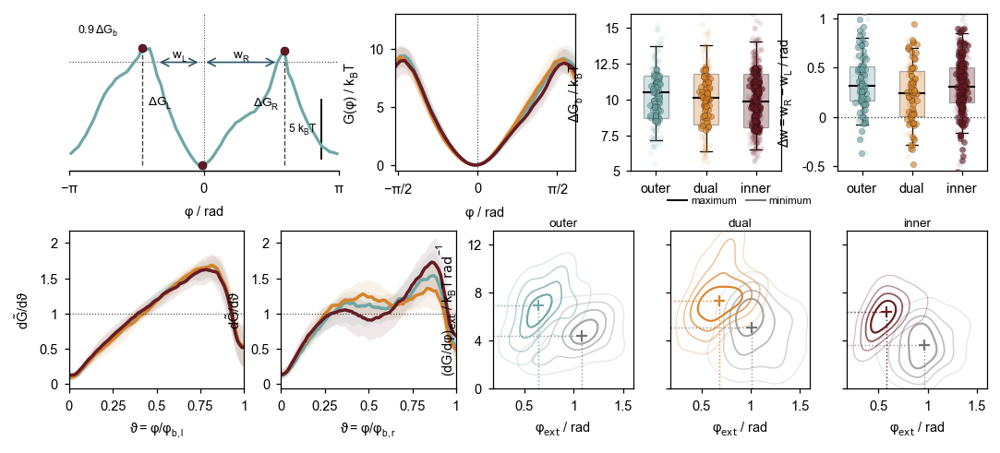

In [19]:
publication_result = plot_publication_stator(
    publication_analysis,

    fig_width_mm=180,
    fig_height_mm=80,
    energy_ylim=(-0.5, 13),

    top_wspace=0.30,
    bottom_wspace=0.24,

    explainer_variant="L2ss",
    explainer_particle_id=55,
    explainer_mode="median_barrier",

    # extremum detection
    slope_smooth_window=11,
    slope_smooth_polyorder=3,
    curvature_smooth_window=7,
    curvature_smooth_polyorder=2,
    slope_max_search_range=(0.10, 0.75),
    slope_min_search_max=0.90,
    min_negative_width=0.04,
    min_abs_curvature=0.05,

    # joint KDE
    joint_kde_points=160,
    joint_contour_fractions=(0.20, 0.40, 0.60, 0.80),
    joint_contour_alphas=(0.28, 0.48, 0.72, 1.00),
    joint_contour_lws=(0.60, 0.72, 0.86, 1.02),

    # minimum/grey contours quieter and behind
    joint_minimum_alpha_factor=0.65,

    # common absolute limits; set manually if desired
    joint_abs_xlim=None,
    joint_abs_ylim=None,

    # absolute x axis in radians
    joint_xtick_step=0.5,

    # median '+' and dotted projections
    joint_median_markersize=6,
    joint_median_markeredgewidth=1,
    joint_guide_lw=0.70,
    joint_guide_alpha_max=0.90,
    joint_guide_alpha_min=0.70,

    print_statistics=True,
    show_significance=False,

    save_dir=r"N:\users\lweiss\_06__Umbrella_Sampling\02_Figures\Figure_4",
    save_svg=True,
    save_prefix="publication_stator_final",
)


# #%% ============================================================================
# # OPTIONAL — INSPECT EXTREMUM STATISTICS
# # ============================================================================

# display(publication_result["statistics"]["phi_s_max"]["pairwise"])
# display(publication_result["statistics"]["phi_s_min"]["pairwise"])
# display(publication_result["statistics"]["s_abs_max"]["pairwise"])
# display(publication_result["statistics"]["s_abs_min"]["pairwise"])

# publication_result["sample_sizes"]

#### SI Plot - Rotor gallery

#### _[Consensus]_

In [20]:
# #%% ============================================================================
# # FULL DROP-IN
# #
# # TOP ROW:
# #   raw energy landscapes for L2ss / L3ss / L4ss
# #
# # BOTTOM ROW:
# #   consensus-only landscapes for L2ss / L3ss / L4ss
# #   with detected metric locations overlaid
# #
# # Uses existing publication_analysis only.
# # No expensive re-analysis is performed here.
# # ============================================================================

# import numpy as np
# import matplotlib.pyplot as plt
# from pathlib import Path


# #%% ============================================================================
# # PREPARE DATA
# # ============================================================================

# def prepare_publication_metric_consensus(
#     publication_analysis,
#     stator_variants=("L2ss", "L3ss", "L4ss"),
#     selection_key="selected",
#     phi_grid_n=361,
#     barrier_fraction=0.90,
# ):
#     top_records = publication_analysis["top_records"]
#     variants = list(stator_variants)
#     phi_grid = np.linspace(-np.pi, np.pi, int(phi_grid_n))

#     def interpolate_to_grid(phi, energy):
#         phi = np.asarray(phi, float)
#         energy = np.asarray(energy, float)

#         finite = np.isfinite(phi) & np.isfinite(energy)
#         if finite.sum() < 2:
#             return np.full_like(phi_grid, np.nan)

#         x = phi[finite]
#         y = energy[finite]

#         order = np.argsort(x)
#         x = x[order]
#         y = y[order]

#         out = np.full_like(phi_grid, np.nan)
#         inside = (phi_grid >= np.nanmin(x)) & (phi_grid <= np.nanmax(x))

#         if inside.any():
#             out[inside] = np.interp(phi_grid[inside], x, y)

#         return out

#     def consensus(matrix):
#         matrix = np.asarray(matrix, float)

#         return {
#             "median": np.nanmedian(matrix, axis=0),
#             "q25": np.nanpercentile(matrix, 25, axis=0),
#             "q75": np.nanpercentile(matrix, 75, axis=0),
#         }

#     def median_finite(values):
#         values = np.asarray(values, float)
#         values = values[np.isfinite(values)]
#         return float(np.nanmedian(values)) if len(values) else np.nan

#     prepared = {
#         "variants": variants,
#         "phi_grid": phi_grid,
#         "by_variant": {},
#         "variant_colors": publication_analysis["variant_colors"],
#         "C": publication_analysis["C"],
#     }

#     for variant in variants:
#         current = [r for r in top_records if r["stator_variant"] == variant]

#         valid = []

#         for r in current:
#             phi = np.asarray(r["phi_rad"], float)
#             energy = np.asarray(r["energy_raw"], float)

#             if len(phi) != len(energy):
#                 continue

#             rr = dict(r)
#             rr["_phi"] = phi.copy()
#             rr["_energy"] = energy.copy()
#             rr["_selected"] = bool(r.get(selection_key, True))
#             rr["_interp"] = interpolate_to_grid(phi, energy)

#             valid.append(rr)

#         selected = [r for r in valid if r["_selected"]]
#         nonselected = [r for r in valid if not r["_selected"]]

#         if len(valid) == 0:
#             prepared["by_variant"][variant] = {
#                 "all": [],
#                 "selected": [],
#                 "nonselected": [],
#                 "matrix_all": None,
#                 "matrix_selected": None,
#                 "consensus": None,
#                 "metrics": None,
#                 "n_all": 0,
#                 "n_selected": 0,
#             }
#             continue

#         if len(selected) == 0:
#             selected = valid.copy()
#             nonselected = []

#         matrix_all = np.vstack([r["_interp"] for r in valid])
#         matrix_selected = np.vstack([r["_interp"] for r in selected])

#         cons = consensus(matrix_selected)

#         # --------------------------------------------------------------------
#         # IMPORTANT:
#         # do NOT redetect features on the consensus.
#         #
#         # Instead use the median of the per-rotor detections that were already
#         # obtained in publication_analysis.
#         # --------------------------------------------------------------------
#         phiL = median_finite([
#             r["phi_rad"][int(r["left_barrier_index"])]
#             for r in selected
#             if "left_barrier_index" in r
#         ])

#         phiR = median_finite([
#             r["phi_rad"][int(r["right_barrier_index"])]
#             for r in selected
#             if "right_barrier_index" in r
#         ])

#         dGL = median_finite([r["left_barrier_raw"] for r in selected])
#         dGR = median_finite([r["right_barrier_raw"] for r in selected])
#         dGmean = median_finite([r["mean_barrier_raw"] for r in selected])

#         wL90 = np.radians(
#             median_finite([r["left_width_90_deg"] for r in selected])
#         )

#         wR90 = np.radians(
#             median_finite([r["right_width_90_deg"] for r in selected])
#         )

#         dw90 = (
#             wR90 - wL90
#             if np.isfinite(wL90) and np.isfinite(wR90)
#             else np.nan
#         )

#         level90 = median_finite([
#             r["barrier_level_90"]
#             for r in selected
#         ])

#         metrics = {
#             "phiL": phiL,
#             "phiR": phiR,
#             "phi0": 0.0,
#             "dGL": dGL,
#             "dGR": dGR,
#             "dGmean": dGmean,
#             "wL90": wL90,
#             "wR90": wR90,
#             "dw90": dw90,
#             "level90": level90,
#         }

#         prepared["by_variant"][variant] = {
#             "all": valid,
#             "selected": selected,
#             "nonselected": nonselected,
#             "matrix_all": matrix_all,
#             "matrix_selected": matrix_selected,
#             "consensus": cons,
#             "metrics": metrics,
#             "n_all": len(valid),
#             "n_selected": len(selected),
#         }

#     return prepared


# #%% ============================================================================
# # PLOT
# # ============================================================================

# def plot_publication_metric_consensus(
#     prepared,
#     fig_width_mm=160,
#     fig_height_mm=88,
#     energy_ylim=(-0.5, 13.0),

#     # raw top row
#     individual_alpha_all=0.040,
#     individual_alpha_selected=0.12,
#     individual_lw_all=0.45,
#     individual_lw_selected=0.55,

#     # consensus
#     consensus_lw=1.8,
#     consensus_fill_alpha=0.15,

#     # metric overlays
#     metric_marker_size=18,
#     metric_lw=0.7,

#     landscape_scalebar_kBT=5.0,

#     show_selected_darker=True,
#     show_counts=True,
#     show_metric_numbers=True,

#     save_dir=None,
#     save_svg=False,
#     save_prefix="raw_and_consensus_metric_landscapes",
# ):
#     variants = prepared["variants"]
#     phi_grid = np.asarray(prepared["phi_grid"], float)
#     variant_colors = prepared["variant_colors"]
#     C = prepared["C"]

#     def mm(x):
#         return float(x) / 25.4

#     def set_rad_ticks(ax):
#         ax.set_xticks([-np.pi, 0, np.pi])
#         ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])

#     def style_energy_ax(ax):
#         ax.spines["left"].set_visible(False)
#         ax.spines["right"].set_visible(False)
#         ax.spines["top"].set_visible(False)
#         ax.spines["bottom"].set_linewidth(0.65)
#         ax.spines["bottom"].set_color(C["black"])

#         ax.tick_params(
#             axis="x",
#             direction="out",
#             length=2.4,
#             width=0.6,
#             labelsize=7,
#         )

#         ax.tick_params(
#             axis="y",
#             left=False,
#             labelleft=False,
#         )

#         ax.grid(False)

#     def add_energy_scalebar(ax, height):
#         ymin, ymax = ax.get_ylim()

#         x0 = np.pi - 0.38
#         y0 = ymin + 0.08 * (ymax - ymin)

#         ax.plot(
#             [x0, x0],
#             [y0, y0 + height],
#             color=C["black"],
#             lw=0.9,
#             clip_on=False,
#         )

#         ax.text(
#             x0 - 0.10,
#             y0 + 0.5 * height,
#             rf"{height:g} $k_BT$",
#             ha="right",
#             va="center",
#             fontsize=5.8,
#         )

#     def interp_y(x, y, x0):
#         finite = np.isfinite(x) & np.isfinite(y)

#         if finite.sum() < 2 or not np.isfinite(x0):
#             return np.nan

#         xx = x[finite]
#         yy = y[finite]

#         order = np.argsort(xx)
#         xx = xx[order]
#         yy = yy[order]

#         if x0 < xx.min() or x0 > xx.max():
#             return np.nan

#         return float(np.interp(x0, xx, yy))

#     # =========================================================================
#     # FIGURE
#     # =========================================================================

#     fig, axes = plt.subplots(
#         2,
#         len(variants),
#         figsize=(mm(fig_width_mm), mm(fig_height_mm)),
#         squeeze=False,
#     )

#     fig.subplots_adjust(
#         left=0.035,
#         right=0.995,
#         bottom=0.10,
#         top=0.97,
#         wspace=0.08,
#         hspace=0.30,
#     )

#     # =========================================================================
#     # TOP ROW — RAW LANDSCAPES
#     # =========================================================================

#     for col, variant in enumerate(variants):
#         ax = axes[0, col]

#         data = prepared["by_variant"][variant]
#         color = variant_colors[variant]

#         all_records = data["all"]
#         selected = data["selected"]
#         nonselected = data["nonselected"]

#         # all non-selected rotors: faint
#         for r in nonselected:
#             ax.plot(
#                 r["_phi"],
#                 r["_energy"],
#                 color=color,
#                 lw=individual_lw_all,
#                 alpha=individual_alpha_all,
#             )

#         # selected rotors: darker
#         if show_selected_darker:
#             for r in selected:
#                 ax.plot(
#                     r["_phi"],
#                     r["_energy"],
#                     color=color,
#                     lw=individual_lw_selected,
#                     alpha=individual_alpha_selected,
#                 )
#         else:
#             for r in selected:
#                 ax.plot(
#                     r["_phi"],
#                     r["_energy"],
#                     color=color,
#                     lw=individual_lw_all,
#                     alpha=individual_alpha_all,
#                 )

#         # consensus of selected subset
#         if data["consensus"] is not None:
#             cons = data["consensus"]

#             ax.fill_between(
#                 phi_grid,
#                 cons["q25"],
#                 cons["q75"],
#                 color=color,
#                 alpha=consensus_fill_alpha,
#                 lw=0,
#             )

#             ax.plot(
#                 phi_grid,
#                 cons["median"],
#                 color=color,
#                 lw=consensus_lw,
#                 zorder=4,
#             )

#         ax.axvline(
#             0,
#             color=C["grey"],
#             lw=0.5,
#             ls=":",
#         )

#         ax.set_xlim(-np.pi, np.pi)
#         ax.set_ylim(*energy_ylim)

#         ax.set_title(
#             variant,
#             fontsize=8.5,
#             fontweight="bold",
#             pad=2,
#         )

#         ax.set_xlabel(
#             r"$\varphi$ / rad",
#             fontsize=7,
#         )

#         set_rad_ticks(ax)
#         style_energy_ax(ax)
#         add_energy_scalebar(ax, landscape_scalebar_kBT)

#         if show_counts:
#             ax.text(
#                 0.97,
#                 0.94,
#                 f"all={data['n_all']}   sel={data['n_selected']}",
#                 transform=ax.transAxes,
#                 ha="right",
#                 va="top",
#                 fontsize=5.8,
#                 color=C["grey"],
#             )

#     # =========================================================================
#     # BOTTOM ROW — CLEAN CONSENSUS + METRICS
#     # =========================================================================

#     for col, variant in enumerate(variants):
#         ax = axes[1, col]

#         data = prepared["by_variant"][variant]
#         color = variant_colors[variant]
#         cons = data["consensus"]
#         metrics = data["metrics"]

#         if cons is None or metrics is None:
#             ax.set_visible(False)
#             continue

#         med = cons["median"]
#         q25 = cons["q25"]
#         q75 = cons["q75"]

#         phiL = metrics["phiL"]
#         phiR = metrics["phiR"]

#         dGL = metrics["dGL"]
#         dGR = metrics["dGR"]
#         dGmean = metrics["dGmean"]

#         wL90 = metrics["wL90"]
#         wR90 = metrics["wR90"]
#         dw90 = metrics["dw90"]
#         level90 = metrics["level90"]

#         # ---------------------------------------------------------------------
#         # consensus
#         # ---------------------------------------------------------------------
#         ax.fill_between(
#             phi_grid,
#             q25,
#             q75,
#             color=color,
#             alpha=consensus_fill_alpha,
#             lw=0,
#         )

#         ax.plot(
#             phi_grid,
#             med,
#             color=color,
#             lw=consensus_lw,
#             zorder=3,
#         )

#         # ---------------------------------------------------------------------
#         # median detected barrier locations
#         # ---------------------------------------------------------------------
#         y0 = interp_y(phi_grid, med, 0.0)
#         yL = interp_y(phi_grid, med, phiL)
#         yR = interp_y(phi_grid, med, phiR)

#         if np.isfinite(phiL) and np.isfinite(yL):
#             ax.scatter(
#                 phiL,
#                 yL,
#                 s=metric_marker_size,
#                 facecolor=C["darkred"],
#                 edgecolor=C["black"],
#                 linewidth=0.25,
#                 zorder=7,
#             )

#             ax.vlines(
#                 phiL,
#                 y0,
#                 yL,
#                 color=C["grey"],
#                 lw=metric_lw,
#                 ls="--",
#             )

#         if np.isfinite(phiR) and np.isfinite(yR):
#             ax.scatter(
#                 phiR,
#                 yR,
#                 s=metric_marker_size,
#                 facecolor=C["darkred"],
#                 edgecolor=C["black"],
#                 linewidth=0.25,
#                 zorder=7,
#             )

#             ax.vlines(
#                 phiR,
#                 y0,
#                 yR,
#                 color=C["grey"],
#                 lw=metric_lw,
#                 ls="--",
#             )

#         ax.scatter(
#             0,
#             y0,
#             s=metric_marker_size,
#             facecolor=C["darkred"],
#             edgecolor=C["black"],
#             linewidth=0.25,
#             zorder=7,
#         )

#         # ---------------------------------------------------------------------
#         # 90% width
#         # ---------------------------------------------------------------------
#         if np.isfinite(level90):
#             ax.axhline(
#                 level90,
#                 color=C["grey"],
#                 lw=0.55,
#                 ls=":",
#             )

#         if np.isfinite(wL90):
#             ax.scatter(
#                 -wL90,
#                 level90,
#                 marker="s",
#                 s=metric_marker_size * 0.85,
#                 color=C["darkblue"],
#                 zorder=8,
#             )

#         if np.isfinite(wR90):
#             ax.scatter(
#                 wR90,
#                 level90,
#                 marker="s",
#                 s=metric_marker_size * 0.85,
#                 color=C["darkblue"],
#                 zorder=8,
#             )

#         # arrows
#         y_arrow = max(
#             y0 + 0.65,
#             0.65,
#         )

#         if np.isfinite(wL90):
#             ax.annotate(
#                 "",
#                 xy=(0, y_arrow),
#                 xytext=(-wL90, y_arrow),
#                 arrowprops=dict(
#                     arrowstyle="<->",
#                     color=C["darkblue"],
#                     lw=0.75,
#                 ),
#             )

#             ax.text(
#                 -0.5 * wL90,
#                 y_arrow + 0.25,
#                 r"$w_{L,90}$",
#                 ha="center",
#                 va="bottom",
#                 fontsize=5.8,
#             )

#         if np.isfinite(wR90):
#             ax.annotate(
#                 "",
#                 xy=(wR90, y_arrow),
#                 xytext=(0, y_arrow),
#                 arrowprops=dict(
#                     arrowstyle="<->",
#                     color=C["darkblue"],
#                     lw=0.75,
#                 ),
#             )

#             ax.text(
#                 0.5 * wR90,
#                 y_arrow + 0.25,
#                 r"$w_{R,90}$",
#                 ha="center",
#                 va="bottom",
#                 fontsize=5.8,
#             )

#         # ---------------------------------------------------------------------
#         # text annotations
#         # ---------------------------------------------------------------------
#         if show_metric_numbers:
#             if np.isfinite(phiL) and np.isfinite(yL):
#                 ax.text(
#                     phiL + 0.08,
#                     0.5 * (y0 + yL),
#                     rf"$\Delta G_L={dGL:.1f}$",
#                     ha="left",
#                     va="center",
#                     fontsize=5.8,
#                 )

#             if np.isfinite(phiR) and np.isfinite(yR):
#                 ax.text(
#                     phiR - 0.08,
#                     0.5 * (y0 + yR),
#                     rf"$\Delta G_R={dGR:.1f}$",
#                     ha="right",
#                     va="center",
#                     fontsize=5.8,
#                 )

#             ax.text(
#                 0.03,
#                 0.95,
#                 rf"$\overline{{\Delta G_B}}={dGmean:.1f}\,k_BT$",
#                 transform=ax.transAxes,
#                 ha="left",
#                 va="top",
#                 fontsize=6.2,
#             )

#             if np.isfinite(dw90):
#                 ax.text(
#                     0.03,
#                     0.84,
#                     rf"$\Delta w_{{90}}={dw90:.2f}\,\mathrm{{rad}}$",
#                     transform=ax.transAxes,
#                     ha="left",
#                     va="top",
#                     fontsize=6.2,
#                 )

#         ax.axvline(
#             0,
#             color=C["grey"],
#             lw=0.5,
#             ls=":",
#         )

#         ax.set_xlim(-np.pi, np.pi)
#         ax.set_ylim(*energy_ylim)

#         ax.set_xlabel(
#             r"$\varphi$ / rad",
#             fontsize=7,
#         )

#         set_rad_ticks(ax)
#         style_energy_ax(ax)
#         add_energy_scalebar(ax, landscape_scalebar_kBT)

#         if show_counts:
#             ax.text(
#                 0.97,
#                 0.94,
#                 f"n={data['n_selected']}",
#                 transform=ax.transAxes,
#                 ha="right",
#                 va="top",
#                 fontsize=5.8,
#                 color=C["grey"],
#             )

#     # =========================================================================
#     # SAVE
#     # =========================================================================

#     if save_dir is not None:
#         save_dir = Path(save_dir)
#         save_dir.mkdir(parents=True, exist_ok=True)

#         fig.savefig(
#             save_dir / f"{save_prefix}.png",
#             dpi=300,
#             bbox_inches="tight",
#         )

#         if save_svg:
#             fig.savefig(
#                 save_dir / f"{save_prefix}.svg",
#                 bbox_inches="tight",
#             )

#     plt.show()
#     plt.close(fig)

#     return fig


# #%% ============================================================================
# # RUN
# #
# # preparation is fast and does NOT rerun the expensive rotor analysis
# # ============================================================================

# publication_metric_data = prepare_publication_metric_consensus(
#     publication_analysis=publication_analysis,
#     stator_variants=("L2ss", "L3ss", "L4ss"),

#     # exact same selected flag as your main analysis
#     selection_key="selected",

#     phi_grid_n=361,
#     barrier_fraction=0.90,
# )


# fig_landscape_metrics = plot_publication_metric_consensus(
#     prepared=publication_metric_data,

#     fig_width_mm=160,
#     fig_height_mm=88,

#     energy_ylim=(-0.5, 13.0),

#     # raw top row
#     individual_alpha_all=0.040,
#     individual_alpha_selected=0.12,
#     individual_lw_all=0.45,
#     individual_lw_selected=0.55,

#     # consensus
#     consensus_lw=1.8,
#     consensus_fill_alpha=0.15,

#     # metrics
#     metric_marker_size=18,
#     metric_lw=0.7,

#     landscape_scalebar_kBT=5.0,

#     show_selected_darker=True,
#     show_counts=True,
#     show_metric_numbers=True,

#     save_dir=None,
#     save_svg=False,
# )

#### Rotor gallery

In [21]:
import math
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

def plot_rotor_metric_gallery(
    publication_analysis,
    stator_variant="all",
    only_selected=False,
    sort_by="particle_id",
    ncols=4,
    nrows=4,
    panel_width_mm=40,
    panel_height_mm=32,
    show_barrier_lines=True,
    save_dir=None,
    save_svg=False,
    save_prefix="rotor_metric_gallery_clean",
):
    top_records = publication_analysis["top_records"]
    variant_colors = publication_analysis["variant_colors"]
    C = publication_analysis["C"]

    def mm(x): return float(x) / 25.4

    def style_ax(ax):
        ax.tick_params(direction="out", length=2.0, width=0.5, labelsize=5.5)
        for s in ax.spines.values():
            s.set_linewidth(0.55)
            s.set_color(C["black"])
        ax.grid(False)

    def get_energy(record):
        for key in ["energy_raw", "energy_kBT", "energy"]:
            if key in record and record[key] is not None:
                return np.asarray(record[key], float)
        raise KeyError("Record does not contain 'energy_raw' or 'energy_kBT'.")

    def safe_float(record, key, default=np.nan):
        value = record.get(key, default)
        try:
            return float(value)
        except Exception:
            return default

    if isinstance(stator_variant, str) and stator_variant.lower() == "all":
        variants = list(dict.fromkeys(r["stator_variant"] for r in top_records))
    elif isinstance(stator_variant, (list, tuple)):
        variants = list(stator_variant)
    else:
        variants = [stator_variant]

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)

    returned_paths = {}

    for variant in variants:
        records = [r for r in top_records if r["stator_variant"] == variant]
        if only_selected:
            records = [r for r in records if bool(r.get("selected", False))]
        if not records:
            print(f"{variant}: no records to plot.")
            continue

        if sort_by == "particle_id":
            records = sorted(records, key=lambda r: int(r["particle_id"]))
        elif sort_by == "barrier":
            records = sorted(records, key=lambda r: (-safe_float(r, "mean_barrier_raw"), int(r["particle_id"])))
        elif sort_by == "width_asym":
            records = sorted(records, key=lambda r: (-abs(safe_float(r, "width_difference_90_deg")), int(r["particle_id"])))

        panels_per_page = int(ncols * nrows)
        n_pages = math.ceil(len(records) / panels_per_page)
        color = variant_colors.get(variant, C["black"])
        saved_pages = []

        for page in range(n_pages):
            page_records = records[page * panels_per_page:(page + 1) * panels_per_page]
            fig, axes = plt.subplots(nrows, ncols, squeeze=False, figsize=(mm(panel_width_mm * ncols), mm(panel_height_mm * nrows)))
            fig.subplots_adjust(left=0.055, right=0.995, bottom=0.060, top=0.985, wspace=0.12, hspace=0.12)

            for panel_index, record in enumerate(page_records):
                row, col = divmod(panel_index, ncols)
                ax = axes[row, col]

                phi = np.asarray(record["phi_rad"], float)
                E = get_energy(record)

                iL = int(record["left_barrier_index"])
                iR = int(record["right_barrier_index"])

                phiL, phiR = float(phi[iL]), float(phi[iR])
                GL, GR = float(E[iL]), float(E[iR])

                Gb = safe_float(record, "mean_barrier_raw")
                wL_deg = safe_float(record, "left_width_90_deg")
                wR_deg = safe_float(record, "right_width_90_deg")

                ax.plot(phi, E, color=color, lw=1.2, zorder=3)

                if show_barrier_lines:
                    ax.axvline(phiL, color=C["grey"], lw=0.5, ls=":", alpha=0.75, zorder=1)
                    ax.axvline(phiR, color=C["grey"], lw=0.5, ls=":", alpha=0.75, zorder=1)

                ax.scatter([phiL, phiR], [GL, GR], s=18, marker="s", facecolors="none", edgecolors=C["black"], linewidths=0.65, zorder=5)

                ax.text(
                    0.97, 0.95,
                    rf"$\Delta G_b={Gb:.1f}\,k_BT,\;\;w_L={wL_deg:.1f}^\circ,\;\; w_R={wR_deg:.1f}^\circ$",
                    transform=ax.transAxes,
                    ha="right",
                    va="top",
                    fontsize=5,
                    color=C["black"],
                )

                ax.set_xlim(-np.pi, np.pi)
                ax.set_xticks([-np.pi, 0, np.pi])
                ax.set_ylim(0, 15)
                ax.set_yticks(np.arange(0, 16, 3))

                if row == nrows - 1:
                    ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
                    ax.set_xlabel(r"$\varphi$ / rad", fontsize=5.8)
                else:
                    ax.set_xticklabels([])

                if col == 0:
                    ax.set_ylabel(r"$G(\varphi)$ / $k_BT$", fontsize=5.8)
                else:
                    ax.set_yticklabels([])

                style_ax(ax)

            for panel_index in range(len(page_records), panels_per_page):
                axes[panel_index // ncols, panel_index % ncols].set_visible(False)

            if save_dir is not None:
                fn = f"{save_prefix}_{variant}_page{page + 1:02d}"
                png_path = save_dir / f"{fn}.png"
                fig.savefig(png_path, dpi=300, bbox_inches="tight")
                if save_svg:
                    fig.savefig(save_dir / f"{fn}.svg", bbox_inches="tight")
                saved_pages.append(str(png_path))

            plt.show()
            plt.close(fig)

        returned_paths[variant] = saved_pages

    return returned_paths

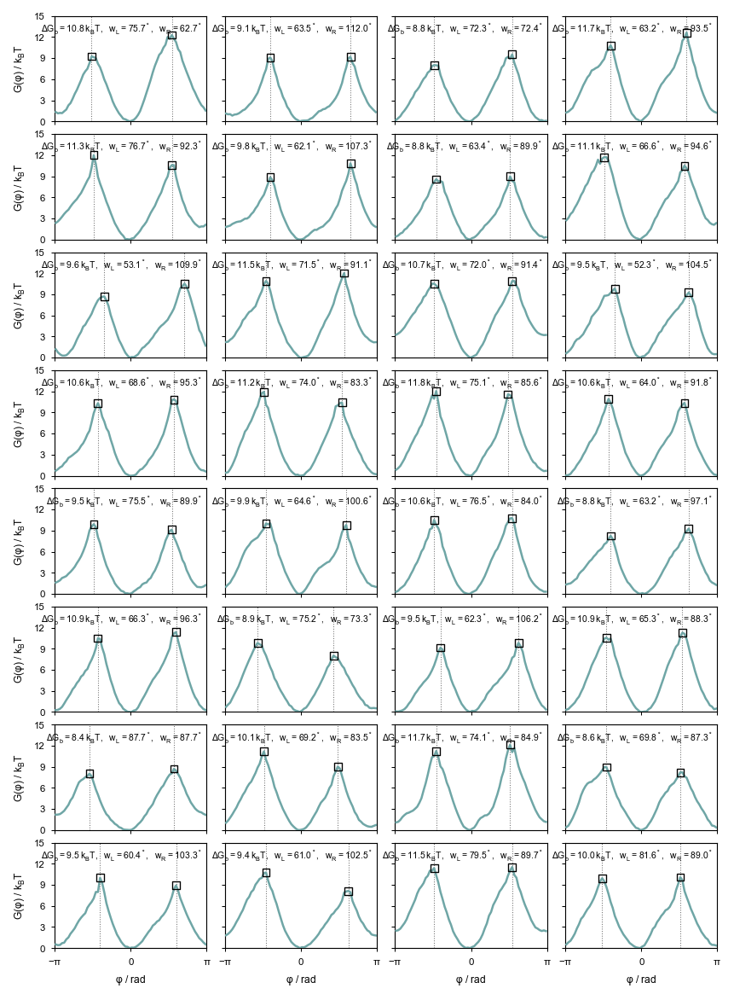

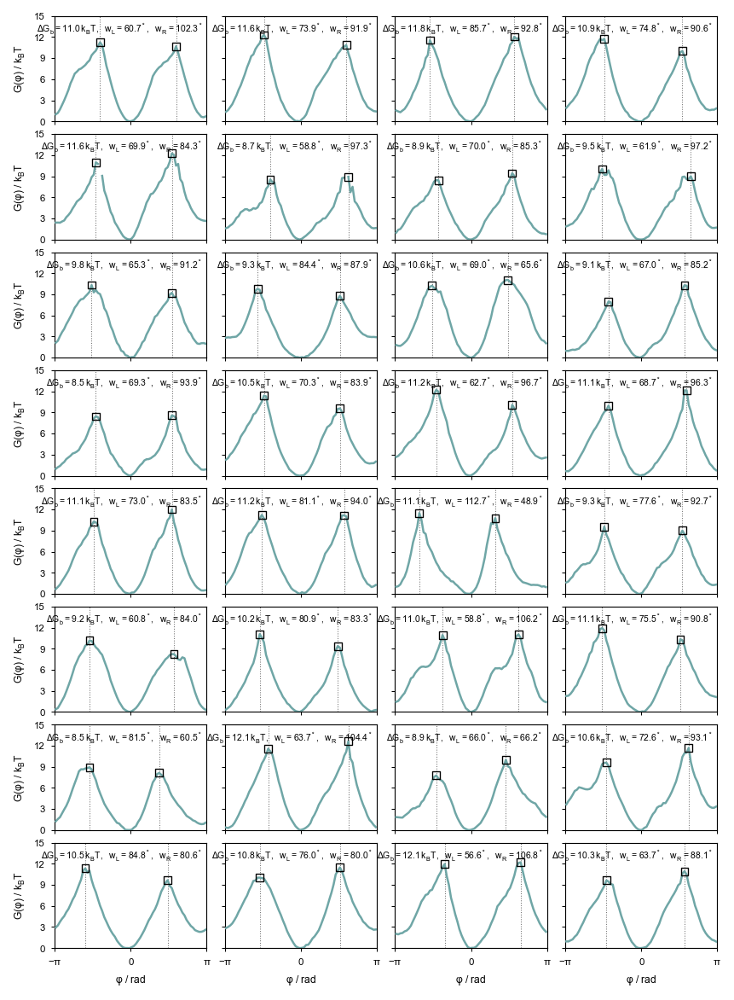

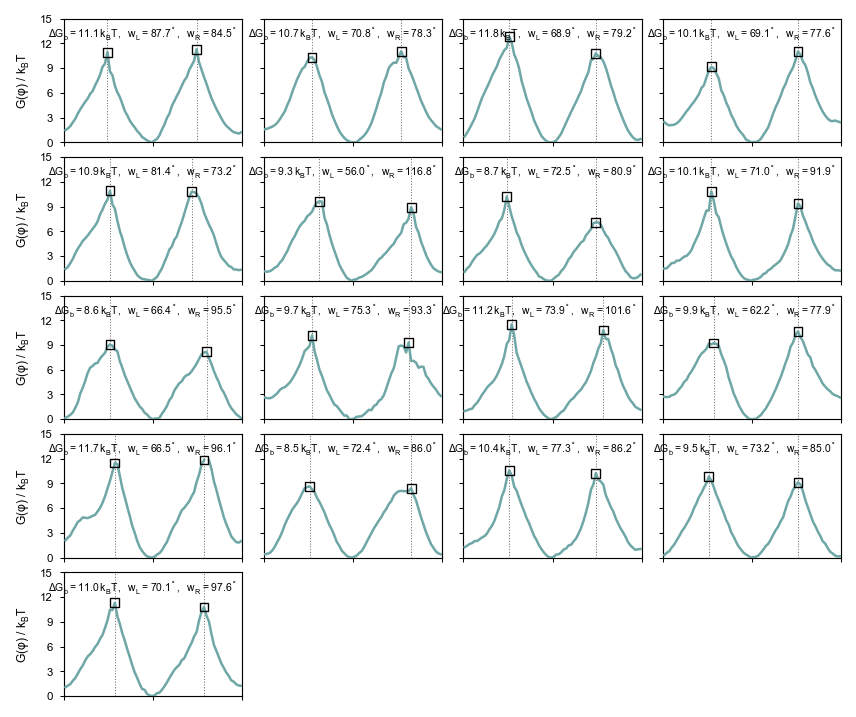

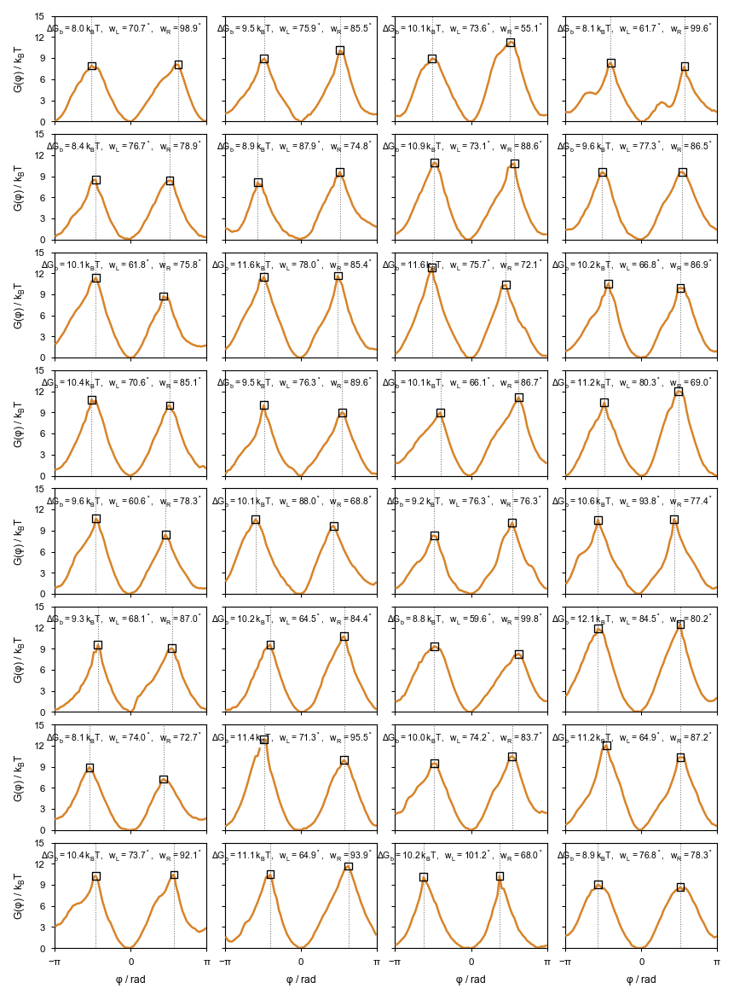

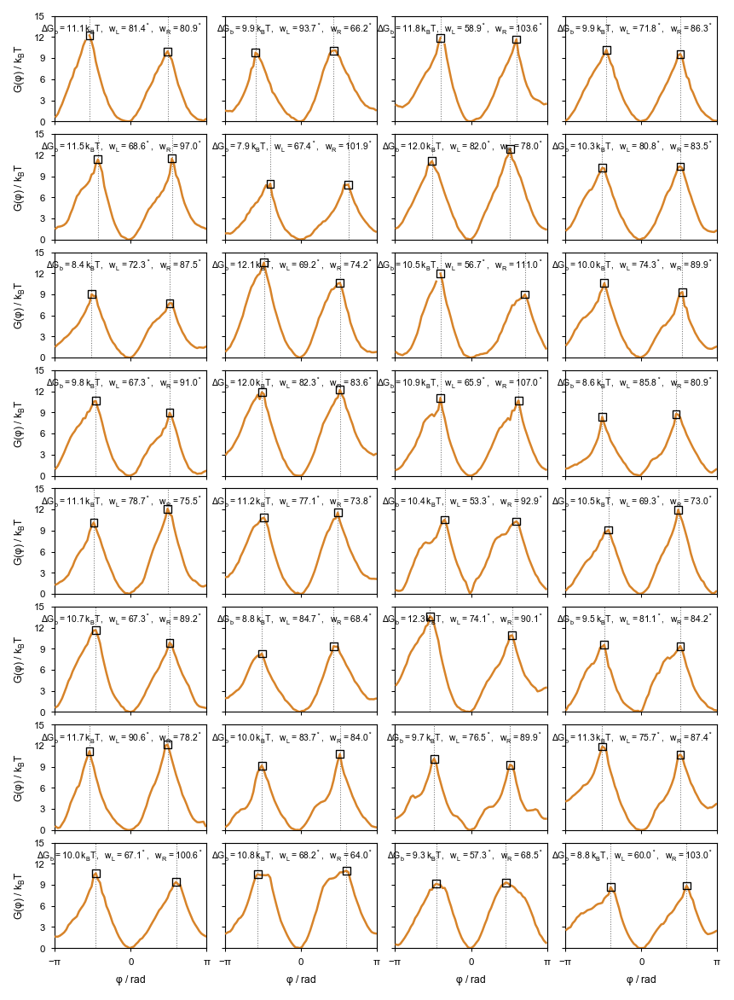

...

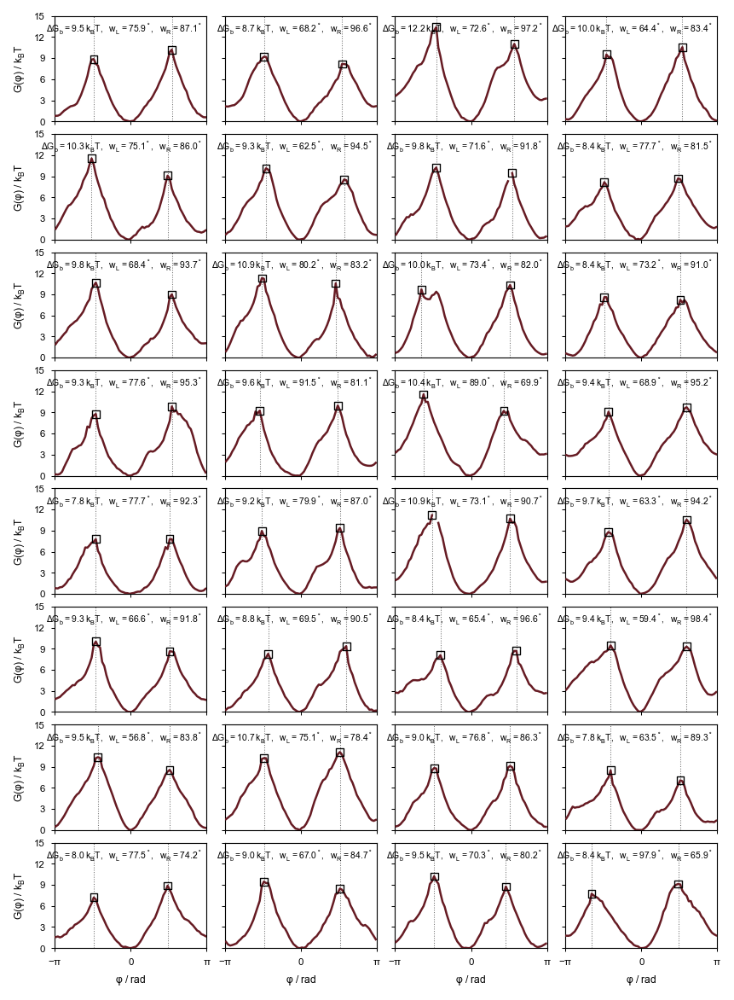

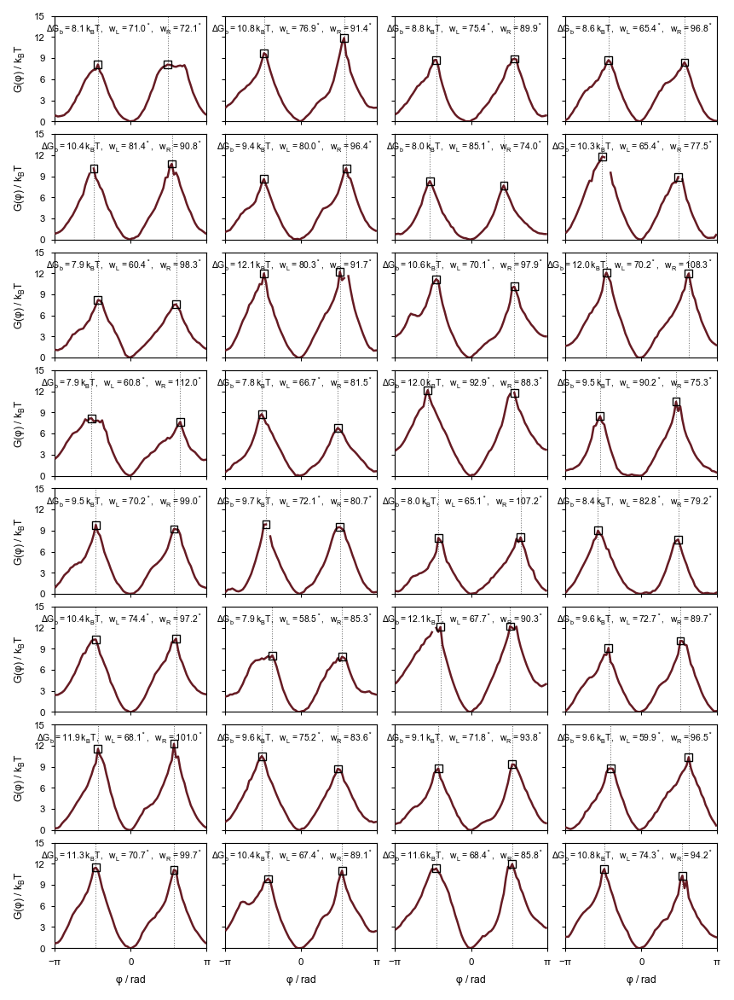

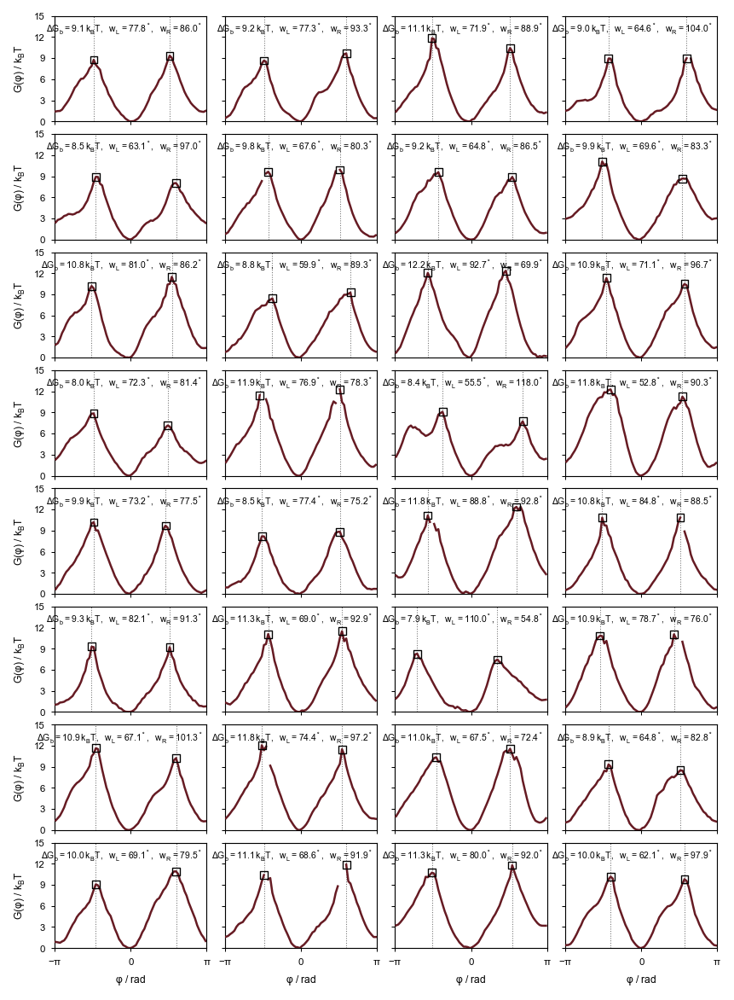

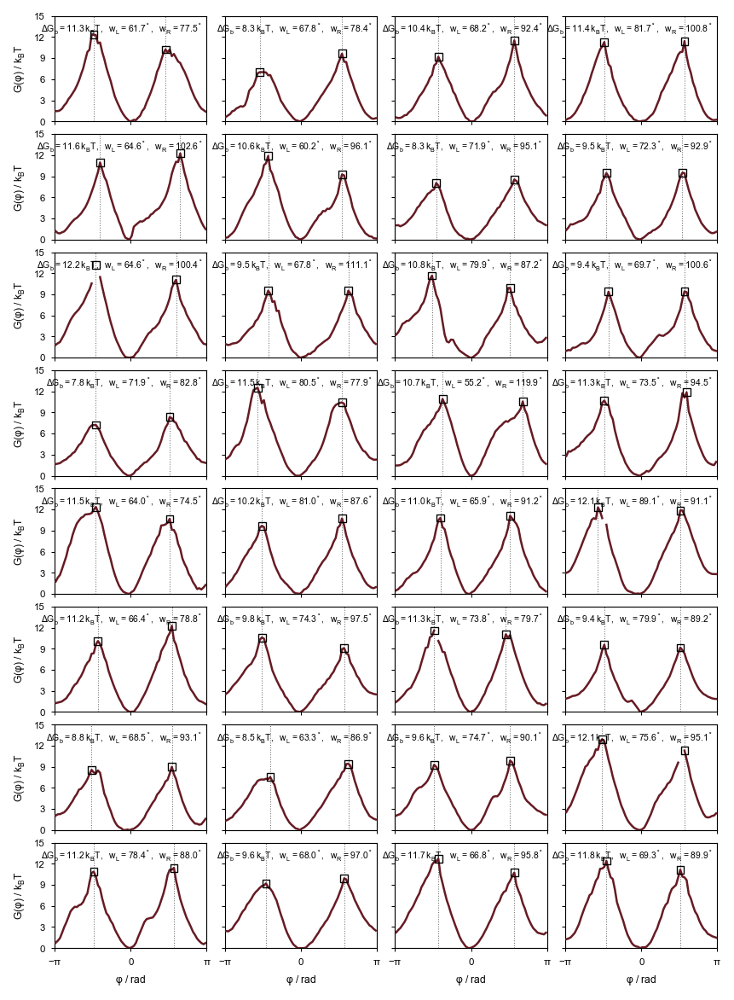

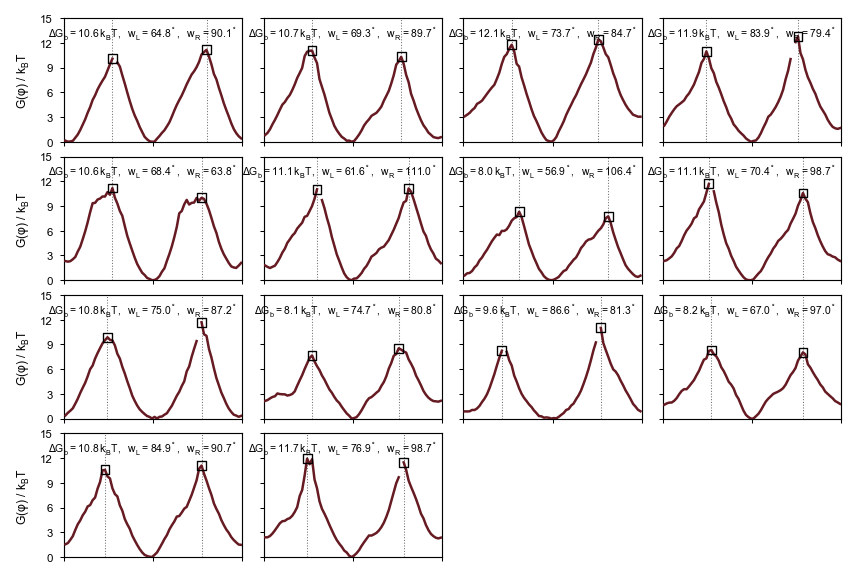

{'L2ss': ['R:\\_06__Umbrella_Sampling\\02_Figures\\Supplementary_Information\\to_Figure_4\\SI_toFig4_reconstruction_gallery_L2ss_page01.png',
  'R:\\_06__Umbrella_Sampling\\02_Figures\\Supplementary_Information\\to_Figure_4\\SI_toFig4_reconstruction_gallery_L2ss_page02.png',
  'R:\\_06__Umbrella_Sampling\\02_Figures\\Supplementary_Information\\to_Figure_4\\SI_toFig4_reconstruction_gallery_L2ss_page03.png'],
 'L3ss': ['R:\\_06__Umbrella_Sampling\\02_Figures\\Supplementary_Information\\to_Figure_4\\SI_toFig4_reconstruction_gallery_L3ss_page01.png',
  'R:\\_06__Umbrella_Sampling\\02_Figures\\Supplementary_Information\\to_Figure_4\\SI_toFig4_reconstruction_gallery_L3ss_page02.png',
  'R:\\_06__Umbrella_Sampling\\02_Figures\\Supplementary_Information\\to_Figure_4\\SI_toFig4_reconstruction_gallery_L3ss_page03.png'],
 'L4ss': ['R:\\_06__Umbrella_Sampling\\02_Figures\\Supplementary_Information\\to_Figure_4\\SI_toFig4_reconstruction_gallery_L4ss_page01.png',
  'R:\\_06__Umbrella_Sampling\\02_Fi

In [22]:
plot_rotor_metric_gallery(
    publication_analysis,
    stator_variant=("L2ss", "L3ss", "L4ss"),
    only_selected=True,
    sort_by="particle_id",
    ncols=4,
    nrows=8,
    panel_width_mm=35,
    panel_height_mm=25,
    show_barrier_lines=True,
    save_dir=r"R:\_06__Umbrella_Sampling\02_Figures\Supplementary_Information\to_Figure_4",
    save_svg=True,
    save_prefix="SI_toFig4_reconstruction_gallery",
)